# `Projeto Aprendizado de Máquina Não Supervisionado`

 **Professor:** Francisco de A. T. de Carvalho

 **Integrantes:**
- Anysabele de Paula Barbosa Santos
- Millena Ferreira Marçal das Neves

### Roteiro do notebook

1. Ambiente
2. Dados
3. Inspeção exploratória
4. Infraestrutura comum dos experimentos
5. Questão 1 - um bloco por algoritmo
6. Questão 1 - consolidação
7. Questão 2
8. Exportação e checklist final

## `1. Ambiente`


In [ ]:
# pacotes ausentes no colab, com versões fixadas para reprodutibilidade:
#   kmedoids     -> k-medoids (PAM / FasterPAM) sobre matriz de distâncias explícita (Etapa 6)
#   scikit-fuzzy -> implementação de referência do fuzzy c-means (Etapas 4 e 5)
#   umap-learn   -> UMAP (Questão 2)
%pip install -q "kmedoids==0.5.5" "scikit-fuzzy==0.5.0" "umap-learn==0.5.12"


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/venv_colab/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# bibliotecas padrão
import hashlib
import io
import json
import platform
import urllib.request
import zipfile
from functools import partial
from itertools import combinations
from importlib.metadata import version as versao_instalada
from pathlib import Path

# ecosistemas cientificos (pré instalados no colab)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage, set_link_color_palette
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree
from scipy.spatial.distance import pdist, squareform
from scipy.special import comb
from scipy.stats import multivariate_normal, spearmanr
from sklearn.cluster import DBSCAN, KMeans, kmeans_plusplus
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.mixture import GaussianMixture

# pacotes especificos, importados antes para evitar erros durante o desenvolvimento
import kmedoids
import skfuzzy
import umap

print("Importações concluídas.")

/tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/venv_colab/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Importações concluídas.


In [ ]:
CONFIG = {
    # reprodutibilidade
    "semente_global": 2026,

    # protocolo experimental da Questão 1, conforme o enunciado
    "valores_k": [1, 2, 3, 4, 5],
    "n_execucoes": 10,
    "metrica_silhueta": "euclidean",   # decisão
    "rtol_objetivo": 1e-6,             # tolerância relativa para "execuções que atingiram o melhor valor"

    # parâmetros dos algoritmos da questão 1: valores definidos A PRIORI. A busca de
    # hiperparâmetros pode substituí-los: a célula de seleção de cada algoritmo grava
    # aqui a configuração escolhida, e as execuções oficiais leem estes valores
    "kmeans": {"max_iter": 300,                         # Lloyd até a partição parar de mudar
               "inicializacao": "sorteio"},             # k objetos distintos sorteados
    "kmedoids": {"max_iter": 100,
                 "inicializacao": "sorteio"},           # os mesmos objetos iniciais do k-means
    "fcm": {"m": 2.0, "tol": 1e-6, "max_iter": 1000},   # parada
    "kfcm": {"m": 2.0, "tol": 1e-6, "max_iter": 1000,  # mesmos m, tolerância e limite do FCM
             "kernel": "gaussiano",
             "quantil_largura": 0.5},
    "precisao_cm": 0.1,                                 # resolução das medidas (todas com 1 casa decimal)
    "gmm": {"covariance_type": "full",
            "reg_covar": 0.1 ** 2 / 12,                 # variância do erro de arredondamento
            "tol": 1e-6, "max_iter": 1000},             # parada: variação da log-verossimilhança
    "single_linkage": {"metrica": "cityblock"},         # exigência do enunciado
    "dbscan": {"metrica": "euclidean", "min_samples": 8,    # min_samples = 2 x dimensão
               "eps": "joelho"},                             # joelho da curva de k-distâncias

    # busca de hiperparâmetros: experimentos adicionais, sem rótulos, antes das execuções oficiais
    "busca": {
        "kmeans_inicializacao": ["sorteio", "k-means++"],
        "kmedoids_inicializacao": ["sorteio", "k-means++", "build"],
        "fcm_m": [1.5, 2.0, 2.5, 3.0],
        "kfcm_quantil_largura": [0.10, 0.25, 0.50, 0.75, 0.90],
        "kfcm_m": [1.5, 2.0, 2.5],
        "gmm_covariance_type": ["full", "tied", "diag", "spherical"],
        "gmm_reg_covar": [1e-6, 0.1 ** 2 / 12, 1e-2],
        "dbscan_min_samples": [4, 6, 8, 10, 12, 16],
        "dbscan_eps": (0.30, 1.20, 0.05),       # grade de ε em cm (início, fim, passo), mais o joelho de cada min_samples
    },

    # questão 2, todos sobre os atributos brutos
    "tsne": {"perplexity": 30, "early_exaggeration": 12.0, "learning_rate": "auto",
             "init": "pca", "max_iter": 1000, "method": "exact"},
    "umap": {"n_neighbors": 15, "min_dist": 0.1, "spread": 1.0},
    "arquivo_iris": "iris.data",
    "sha256_iris_data": "6f608b71a7317216319b4d27b4d9bc84e6abd734eda7872b71a458569e2656c0",
    "url_uci": "https://archive.ics.uci.edu/static/public/53/iris.zip",
    "usar_drive": False,
    "pasta_projeto": "AMNS_Equipe6",
}
np.random.seed(CONFIG["semente_global"])

In [ ]:
try:
    from google.colab import drive
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

USANDO_DRIVE = EM_COLAB and CONFIG["usar_drive"]
if USANDO_DRIVE:
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive") / CONFIG["pasta_projeto"]
else:
    RAIZ = Path.cwd() / CONFIG["pasta_projeto"]

DIRS = {nome: RAIZ / nome for nome in ("dados", "resultados", "figuras")}
for pasta in DIRS.values():
    pasta.mkdir(parents=True, exist_ok=True)

print(f"Ambiente: {'Google Colab' if EM_COLAB else 'local'} | Google Drive: {'sim' if USANDO_DRIVE else 'não'}")
for nome, pasta in DIRS.items():
    print(f"  {nome:<10} -> {pasta}")

Ambiente: local | Google Drive: não
  dados      -> /tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/etapa9/run/AMNS_Equipe6/dados
  resultados -> /tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/etapa9/run/AMNS_Equipe6/resultados
  figuras    -> /tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/etapa9/run/AMNS_Equipe6/figuras


In [ ]:
# registro das versões: vai p o relatório e permite reproduzir o ambiente no futuro
PACOTES = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn",
           "kmedoids", "scikit-fuzzy", "umap-learn"]

AMBIENTE = {"python": platform.python_version(), **{p: versao_instalada(p) for p in PACOTES}}

with open(DIRS["resultados"] / "ambiente.json", "w") as arquivo:
    json.dump(AMBIENTE, arquivo, indent=2)

pd.Series(AMBIENTE, name="versão").to_frame()

,versão
python,3.13.16
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0
seaborn,0.13.2
kmedoids,0.5.5
scikit-fuzzy,0.5.0
umap-learn,0.5.12


In [ ]:
# identidade visual única p todas as figuras do projeto
CORES = {"texto": "#0b0b0b", "texto_sec": "#52514e", "grade": "#e4e3df", "fundo": "#fcfcfb",
         "neutro": "#f0efec", "azul": "#2a78d6", "vermelho": "#e34948"}
CORES_CLASSES = ["#2a78d6", "#eb6834", "#1baf7a"]
MARCADORES = ["o", "s", "^"]
# séries de comparação (algoritmos na Seção 6; configurações das buscas na Seção 5): cor e marcador próprios
CORES_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
MARCADORES_SERIES = ["o", "s", "^", "D", "v", "P"]

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": CORES["fundo"],
    "axes.facecolor": CORES["fundo"],
    "axes.edgecolor": CORES["texto_sec"],
    "axes.labelcolor": CORES["texto"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": CORES["grade"],
    "grid.linewidth": 0.8,
    "xtick.color": CORES["texto_sec"],
    "ytick.color": CORES["texto_sec"],
    "legend.frameon": False,
    "savefig.bbox": "tight",
})


def salvar_figura(fig, nome):
    """Salva a figura em PNG (slides) e em PDF vetorial (relatório) na pasta de figuras."""
    for extensao in ("png", "pdf"):
        fig.savefig(DIRS["figuras"] / f"{nome}.{extensao}", dpi=200)

## `2. Dados`

### 2.1 Obtenção dos arquivos

Os arquivos Iris foram organizados automaticamente no projeto Colab, com busca em diretórios alternativos, download da UCI como fallback e validação por SHA-256 para garantir que o `iris.data` corresponda exatamente ao arquivo fornecido pelo professor.

In [ ]:
ARQUIVOS_IRIS = ("iris.data", "iris.names")


def sha256(caminho):
    """Impressão digital do arquivo: identifica sem ambiguidade qual arquivo foi usado."""
    return hashlib.sha256(Path(caminho).read_bytes()).hexdigest()


def garantir_arquivos_iris(pasta_dados, url):
    """Coloca os arquivos da Iris em `pasta_dados` e devolve a origem de cada um.

    Ordem de busca: (1) a pasta de dados; (2) a pasta de trabalho atual, onde o upload do
    Colab coloca os arquivos; (3) só se o iris.data não for encontrado, o pacote da UCI."""
    origem = {}
    for nome in ARQUIVOS_IRIS:
        destino, enviado = pasta_dados / nome, Path.cwd() / nome
        if destino.exists():
            origem[nome] = "pasta de dados"
        elif enviado.exists():
            destino.write_bytes(enviado.read_bytes())
            origem[nome] = "upload (copiado para a pasta de dados)"

    if "iris.data" not in origem:
        print(f"AVISO: iris.data não foi encontrado; baixando o pacote oficial da UCI:\n  {url}")
        with urllib.request.urlopen(url, timeout=60) as resposta:
            pacote = zipfile.ZipFile(io.BytesIO(resposta.read()))
        for membro in pacote.namelist():
            nome = Path(membro).name
            if nome in ARQUIVOS_IRIS and nome not in origem:
                (pasta_dados / nome).write_bytes(pacote.read(membro))
                origem[nome] = "download da UCI"
    return origem


ORIGEM = garantir_arquivos_iris(DIRS["dados"], CONFIG["url_uci"])

pd.DataFrame(
    [{"arquivo": nome, "origem": ORIGEM[nome], "bytes": (DIRS["dados"] / nome).stat().st_size,
      "sha256 (início)": sha256(DIRS["dados"] / nome)[:16]}
     for nome in ARQUIVOS_IRIS if nome in ORIGEM]
)

,arquivo,origem,bytes,sha256 (início)
0,iris.data,upload (copiado para a pasta de dados),4551,6f608b71a7317216
1,iris.names,upload (copiado para a pasta de dados),2998,71a09fb3ee237614


### 2.2 Leitura, validação estrutural e comparação entre versões

Cada versão disponível é lida e validada (150 objetos, 4 atributos numéricos, 3 classes de 50, sem ausentes)

In [ ]:
ATRIBUTOS = ["comprimento_sepala", "largura_sepala", "comprimento_petala", "largura_petala"]
NOMES_CURTOS = {
    "comprimento_sepala": "Comp. sépala",
    "largura_sepala": "Larg. sépala",
    "comprimento_petala": "Comp. pétala",
    "largura_petala": "Larg. pétala",
}


def ler_iris(caminho):
    """Lê um arquivo no formato da UCI: 4 atributos numéricos + classe, sem cabeçalho.
    Linhas em branco (o arquivo da UCI termina com uma) são ignoradas."""
    return pd.read_csv(caminho, header=None, names=ATRIBUTOS + ["classe"], skip_blank_lines=True)


def validar_iris(df, nome):
    """Verificações estruturais; interrompe a execução se algo fugir do esperado."""
    assert df.shape == (150, 5), f"{nome}: formato inesperado {df.shape}"
    assert df.notna().all().all(), f"{nome}: há valores ausentes"
    assert all(pd.api.types.is_float_dtype(df[a]) for a in ATRIBUTOS), f"{nome}: atributo não numérico"
    contagem = df["classe"].value_counts()
    assert len(contagem) == 3 and (contagem == 50).all(), f"{nome}: classes inesperadas {dict(contagem)}"
    print(f"{nome:<16} OK: 150 objetos, 4 atributos numéricos, 3 classes x 50, sem ausentes")


VERSOES = {"iris.data": ler_iris(DIRS["dados"] / "iris.data")}
iris_sk = load_iris(as_frame=True)
nomes_uci = {i: f"Iris-{nome}" for i, nome in enumerate(iris_sk.target_names)}
VERSOES["scikit-learn"] = (iris_sk.data.set_axis(ATRIBUTOS, axis=1)
                           .assign(classe=iris_sk.target.map(nomes_uci)))

for nome, df in VERSOES.items():
    validar_iris(df, nome)

iris.data        OK: 150 objetos, 4 atributos numéricos, 3 classes x 50, sem ausentes
scikit-learn     OK: 150 objetos, 4 atributos numéricos, 3 classes x 50, sem ausentes


In [ ]:
def comparar_com_referencia(df, df_ref, nome, nome_ref="scikit-learn"):
    """Mostra lado a lado os objetos (numerados de 1 a 150, como na documentação da UCI)
    em que `df` e `df_ref` diferem em algum atributo ou na classe."""
    difere = (df[ATRIBUTOS] != df_ref[ATRIBUTOS]).any(axis=1) | (df["classe"] != df_ref["classe"])
    print(f"{nome} vs {nome_ref}: {difere.sum()} objeto(s) diferente(s)")
    if difere.any():
        tabela = pd.concat({nome: df.loc[difere, ATRIBUTOS], nome_ref: df_ref.loc[difere, ATRIBUTOS]},
                           axis=1)
        tabela.index = tabela.index + 1
        tabela.index.name = "objeto"
        display(tabela)


for nome, df in VERSOES.items():
    if nome != "scikit-learn":
        comparar_com_referencia(df, VERSOES["scikit-learn"], nome)

iris.data vs scikit-learn: 2 objeto(s) diferente(s)


iris.data                                                   \
       comprimento_sepala largura_sepala comprimento_petala largura_petala   
objeto                                                                       
35                    4.9            3.1                1.5            0.1   
38                    4.9            3.1                1.5            0.1   

             scikit-learn                                                   
       comprimento_sepala largura_sepala comprimento_petala largura_petala  
objeto                                                                      
35                    4.9            3.1                1.5            0.2  
38                    4.9            3.6                1.4            0.1

### 2.3 Escolha da versão

A proposta é utilizar o `iris.data` original fornecido pelo professor, sem alterações.

In [ ]:
if CONFIG["arquivo_iris"] not in VERSOES:
    raise ValueError(f"CONFIG['arquivo_iris'] deve ser uma de {list(VERSOES)}; "
                     f"recebido {CONFIG['arquivo_iris']!r}")

# garante que o iris.data é, byte a byte, o arquivo anexado pelo professor (qualquer que seja a origem)
hash_obtido = sha256(DIRS["dados"] / "iris.data")
if hash_obtido != CONFIG["sha256_iris_data"]:
    raise ValueError("O iris.data da pasta de dados NÃO é o arquivo anexado pelo professor:\n"
                     f"  esperado {CONFIG['sha256_iris_data']}\n  obtido   {hash_obtido}")

df_iris = VERSOES[CONFIG["arquivo_iris"]].copy()

# matriz de dados usada por TODOS os algoritmos: atributos brutos, em cm, sem transformação
X = df_iris[ATRIBUTOS].to_numpy(dtype=np.float64)

# rótulos verdadeiros codificados como 0, 1, 2.
CLASSES = sorted(df_iris["classe"].unique())
y_verdadeiro = df_iris["classe"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()

if CONFIG["arquivo_iris"] == "scikit-learn":
    print("Versão utilizada: scikit-learn (corrigida, idêntica aos dados de Fisher)")
else:
    print(f"Arquivo utilizado: iris.data, idêntico ao anexado pelo professor "
          f"(SHA-256 conferido: {hash_obtido[:16]}...)")
contagem = {c: int(n) for c, n in zip(CLASSES, np.bincount(y_verdadeiro))}
print(f"X: {X.shape} | objetos por classe: {contagem}")

Arquivo utilizado: iris.data, idêntico ao anexado pelo professor (SHA-256 conferido: 6f608b71a7317216...)
X: (150, 4) | objetos por classe: {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}


## `3. Inspeção exploratória`

**Objetivos:** conhecer a estrutura da base antes do agrupamento e reunir evidências para a decisão de pré-processamento (A4).

**Princípio:** as análises das Seções 3.1 a 3.4 utilizam apenas os atributos, sem os rótulos, evitando que a avaliação dos agrupamentos influencie a decisão de escala.

### 3.1 Estatísticas descritivas e peso dos atributos nas distâncias

Nas variáveis não padronizadas, a contribuição de cada atributo é calculada separadamente:

- **Euclidiana²:** $2\sum_{p=1}^{4}s_p^2$, em que $s_p^2$ é a variância amostral.
- **City-block:** $\sum_{p=1}^{4}\overline{|x_{ip}-x_{jp}|}$, considerando a diferença absoluta média de cada atributo.

As colunas de peso (%) indicam a contribuição de cada atributo nas respectivas distâncias. Após a padronização *z-score*, todos teriam peso igual (25%) na Euclidiana².

A coluna **maior lacuna** indica o maior intervalo entre valores consecutivos observados.

In [ ]:
dados = df_iris[ATRIBUTOS]


def maior_lacuna(coluna):
    """Maior intervalo entre valores observados consecutivos (sem nenhuma observação dentro)."""
    return np.diff(np.sort(coluna.unique())).max()


# diferença absoluta média de cada atributo entre pares distintos (parcela da city-block média)
dif_abs_media = pd.Series([pdist(X[:, [p]], metric="cityblock").mean() for p in range(X.shape[1])],
                          index=ATRIBUTOS)

descritivas = pd.DataFrame({
    "média": dados.mean(),
    "mediana": dados.median(),
    "desvio padrão": dados.std(),
    "variância": dados.var(),
    "mínimo": dados.min(),
    "máximo": dados.max(),
    "amplitude": dados.max() - dados.min(),
    "coef. de variação": dados.std() / dados.mean(),
    "valores distintos": dados.nunique(),
    "maior lacuna": dados.apply(maior_lacuna),
    "peso % (Euclidiana²)": 100 * dados.var() / dados.var().sum(),
    "peso % (city-block)": 100 * dif_abs_media / dif_abs_media.sum(),
})
display(descritivas.rename(index=NOMES_CURTOS).round(3))

# conferência numérica das duas identidades (médias sobre os pares distintos de objetos)
print(f"Euclidiana²: média sobre os pares = {pdist(X, metric='sqeuclidean').mean():.6f} | "
      f"2 x soma das variâncias = {2 * dados.var().sum():.6f}")
print(f"City-block:  média sobre os pares = {pdist(X, metric='cityblock').mean():.6f} | "
      f"soma das parcelas por atributo = {dif_abs_media.sum():.6f}")

,média,mediana,desvio padrão,variância,mínimo,máximo,amplitude,coef. de variação,valores distintos,maior lacuna,peso % (Euclidiana²),peso % (city-block)
Comp. sépala,5.843,5.80,0.828,0.686,4.3,7.9,3.6,0.142,35,0.2,15.007,22.127
Larg. sépala,3.054,3.00,0.434,0.188,2.0,4.4,2.4,0.142,23,0.2,4.115,11.311
Comp. pétala,3.759,4.35,1.764,3.113,1.0,6.9,5.9,0.469,43,1.1,68.133,46.246
Larg. pétala,1.199,1.30,0.763,0.582,0.1,2.5,2.4,0.637,22,0.4,12.746,20.317


Euclidiana²: média sobre os pares = 9.138583 | 2 x soma das variâncias = 9.138583
City-block:  média sobre os pares = 4.276277 | soma das parcelas por atributo = 4.276277


### 3.2 Objetos duplicados

Objetos com os quatro atributos idênticos serão mantidos, mas possuem origens distintas:

- **Par 102/143:** coincidência legítima de medições, considerando a precisão de 0,1 cm.
- **Trio 10/35/38:** resultado dos erros documentados em `iris.names`. Mesmo com os valores corretos, o trio será mantido conforme a decisão A6.

As duplicatas são relevantes porque podem:

- **K-means e k-medoids:** gerar protótipos iniciais idênticos, exigindo sorteio entre pontos distintos.
- **K-medoids:** produzir empate entre medoides equivalentes.
- **Single linkage:** gerar fusões com altura zero.
- **DBSCAN:** influenciar a contagem de vizinhos e a identificação de pontos centrais.

In [ ]:
duplicado = df_iris.duplicated(subset=ATRIBUTOS, keep=False)
print(f"Objetos envolvidos em duplicatas: {duplicado.sum()}")

if duplicado.any():
    display(df_iris[duplicado]
            .assign(objeto=lambda d: d.index + 1)
            .set_index("objeto")
            .sort_values(ATRIBUTOS))

Objetos envolvidos em duplicatas: 5


,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,classe
objeto,,,,,
10,4.9,3.1,1.5,0.1,Iris-setosa
35,4.9,3.1,1.5,0.1,Iris-setosa
38,4.9,3.1,1.5,0.1,Iris-setosa
102,5.8,2.7,5.1,1.9,Iris-virginica
143,5.8,2.7,5.1,1.9,Iris-virginica


### 3.3 Correlações entre atributos

Entender a correlação entre os atributos é relevante para aplicar a PCA (Questão 2) e escolher a estrutura de covariância da mistura gaussiana (decisão A9).

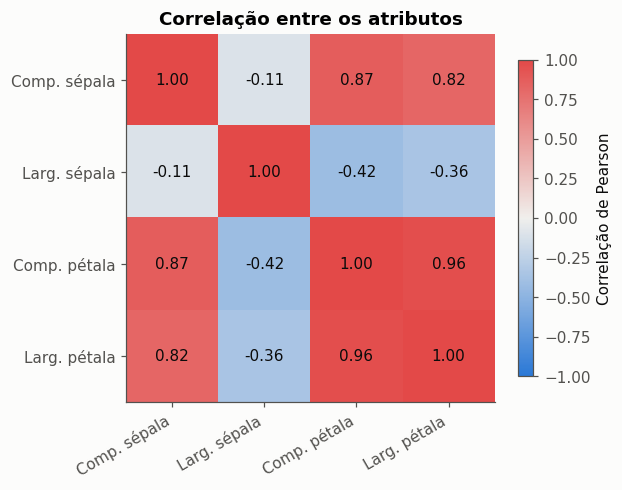

In [ ]:
correlacao = dados.corr().rename(index=NOMES_CURTOS, columns=NOMES_CURTOS)
mapa_divergente = LinearSegmentedColormap.from_list(
    "divergente", [CORES["azul"], CORES["neutro"], CORES["vermelho"]])

fig, ax = plt.subplots(figsize=(5.4, 4.4))
imagem = ax.imshow(correlacao, cmap=mapa_divergente, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(4), correlacao.columns, rotation=30, ha="right")
ax.set_yticks(range(4), correlacao.index)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{correlacao.iat[i, j]:.2f}", ha="center", va="center",
                color=CORES["texto"], fontsize=10)
fig.colorbar(imagem, ax=ax, shrink=0.85, label="Correlação de Pearson")
ax.set_title("Correlação entre os atributos")
salvar_figura(fig, "eda_correlacao")
plt.show()

### 3.4 Distribuições em escala comum

Os quatro atributos estão na mesma unidade (cm), então podem ser comparados no mesmo eixo. A padronização igualaria as dispersões que este gráfico mostra.

Sobre as caixas são desenhadas **todas as 150 observações, sem distinção de espécie**: o boxplot sozinho esconde multimodalidade, e os pontos revelam lacunas como as quantificadas na Seção 3.1. Pontos além dos bigodes são *outliers* pelo critério de 1,5 × IIQ.

A célula seguinte mede, também sem rótulos, quanto da variância de cada atributo se deve à separação definida pela maior lacuna do comprimento da pétala. É uma medida descritiva, usada só na decisão A4, e não um resultado de agrupamento.

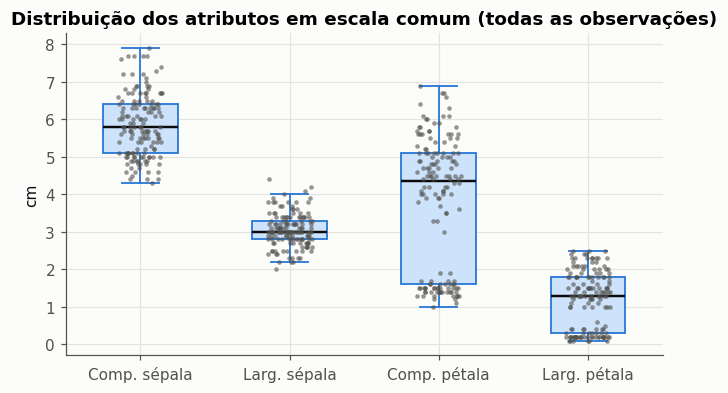

In [ ]:
rng_grafico = np.random.default_rng(CONFIG["semente_global"])   # deslocamento horizontal reprodutível

fig, ax = plt.subplots(figsize=(7, 3.8))
caixas = ax.boxplot([df_iris[a] for a in ATRIBUTOS], widths=0.5, patch_artist=True,
                    showfliers=False,                     # todos os pontos são desenhados abaixo
                    medianprops={"color": CORES["texto"], "linewidth": 1.6})
for caixa in caixas["boxes"]:
    caixa.set(facecolor="#cde2fb", edgecolor=CORES["azul"], linewidth=1.2)
for elemento in ("whiskers", "caps"):
    for linha in caixas[elemento]:
        linha.set(color=CORES["azul"], linewidth=1.2)

# todas as observações, com pequeno deslocamento horizontal aleatório para reduzir a sobreposição
for posicao, atributo in enumerate(ATRIBUTOS, start=1):
    deslocamento = rng_grafico.uniform(-0.15, 0.15, size=len(df_iris))
    ax.scatter(posicao + deslocamento, df_iris[atributo], s=9, color=CORES["texto_sec"],
               alpha=0.6, linewidths=0, zorder=3)

ax.set_xticks(range(1, 5), [NOMES_CURTOS[a] for a in ATRIBUTOS])
ax.set_ylabel("cm")
ax.set_title("Distribuição dos atributos em escala comum (todas as observações)")
salvar_figura(fig, "eda_boxplot_escala_comum")
plt.show()

In [ ]:
# separação sem rótulos: objetos abaixo e acima da maior lacuna do comprimento da pétala
valores = np.sort(df_iris["comprimento_petala"].unique())
i_lacuna = np.diff(valores).argmax()
lim_inf, lim_sup = valores[i_lacuna], valores[i_lacuna + 1]
abaixo = df_iris["comprimento_petala"] <= lim_inf

print(f"Comprimento da pétala: nenhuma observação entre {lim_inf} e {lim_sup} cm "
      f"({abaixo.sum()} objetos abaixo da lacuna, {(~abaixo).sum()} acima).")

valores_lp = np.sort(df_iris["largura_petala"].unique())
i_lp = np.diff(valores_lp).argmax()
mesma_separacao = ((df_iris["largura_petala"] <= valores_lp[i_lp]) == abaixo).all()
print(f"Largura da pétala: nenhuma observação entre {valores_lp[i_lp]} e {valores_lp[i_lp + 1]} cm; "
      f"separa exatamente os mesmos objetos: {mesma_separacao}")


def fracao_entre_lados(coluna, lado):
    """Fração da variância do atributo devida à diferença entre as médias dos dois lados
    (soma de quadrados entre grupos / soma de quadrados total)."""
    total = ((coluna - coluna.mean()) ** 2).sum()
    dentro = ((coluna - coluna.groupby(lado).transform("mean")) ** 2).sum()
    return 1 - dentro / total


(dados.apply(fracao_entre_lados, lado=abaixo)
      .rename(index=NOMES_CURTOS)
      .rename("fração da variância entre os dois lados")
      .round(3).to_frame())

Comprimento da pétala: nenhuma observação entre 1.9 e 3.0 cm (50 objetos abaixo da lacuna, 100 acima).
Largura da pétala: nenhuma observação entre 0.6 e 1.0 cm; separa exatamente os mesmos objetos: True


,fração da variância entre os dois lados
Comp. sépala,0.515
Larg. sépala,0.355
Comp. pétala,0.851
Larg. pétala,0.788


### 3.5 Visão descritiva por espécie

**Uso descritivo:** os rótulos são apresentados apenas para caracterizar a base, sem influenciar as decisões de modelagem.

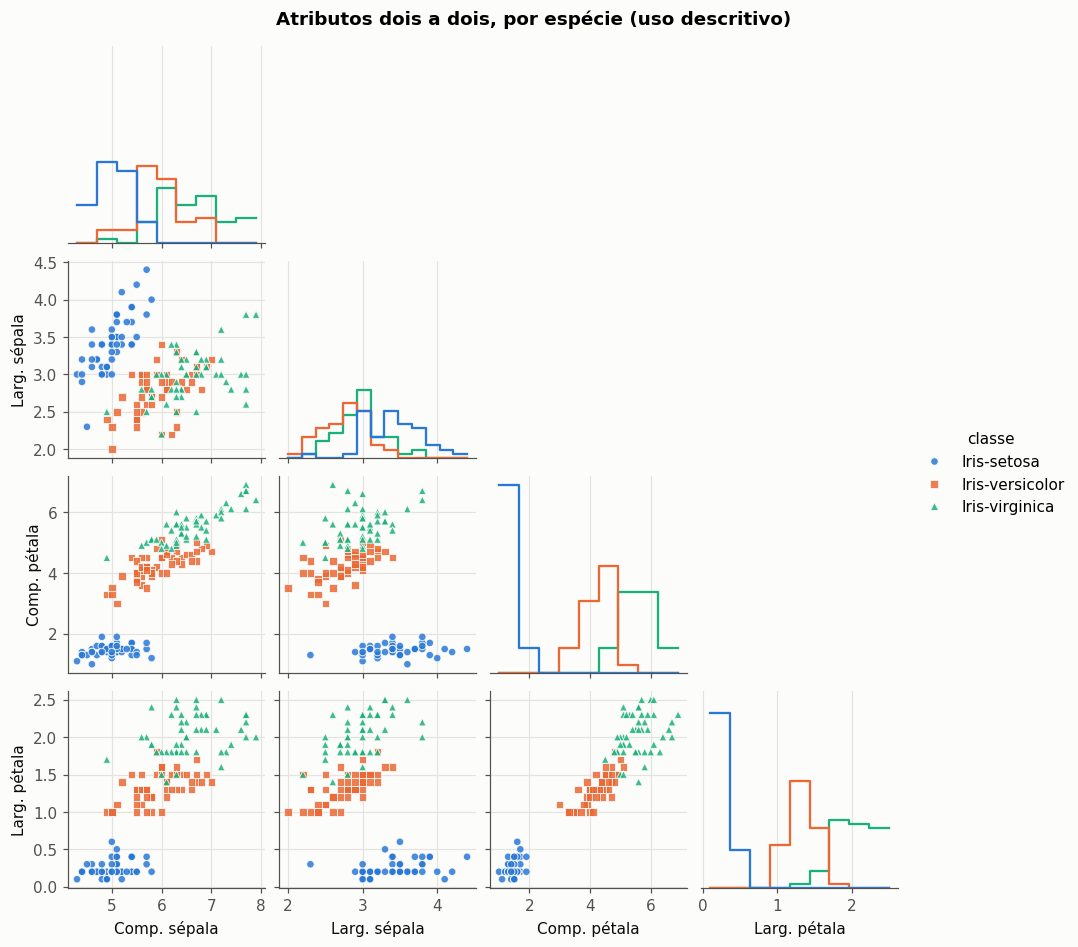

In [ ]:
grade = sns.pairplot(
    df_iris.rename(columns=NOMES_CURTOS), hue="classe", hue_order=CLASSES,
    palette=CORES_CLASSES, markers=MARCADORES, corner=True, height=2.1,
    diag_kind="hist", diag_kws={"element": "step", "fill": False, "linewidth": 1.5},
    plot_kws={"s": 24, "alpha": 0.85, "edgecolor": CORES["fundo"], "linewidth": 0.6},
)
grade.figure.suptitle("Atributos dois a dois, por espécie (uso descritivo)", y=1.02,
                      fontweight="bold")
salvar_figura(grade.figure, "eda_pares_por_especie")
plt.show()

### 3.6 Observações da inspeção

**Duplicatas.** Há cinco objetos formando dois grupos de pontos idênticos: 102/143 (coincidência legítima) e 10/35/38. São quatro pares com distância zero. Isso exige:
- Inicialização com pontos distintos, não apenas índices distintos.
- Consideração das fusões de altura zero no single linkage.
- Atenção ao DBSCAN, pois cada objeto do trio possui três pontos na vizinhança, independentemente de ε.

**Escala e dispersão (A4).**
- As variâncias diferem por um fator de 16,6 entre o comprimento da pétala (3,113) e a largura da sépala (0,188).
- O comprimento da pétala representa 68,1% da Euclidiana² média e 46,2% da city-block. Já a largura da sépala representa apenas 4,1% e 11,3%, respectivamente.
- A dominância das pétalas também aparece na dispersão relativa: seus coeficientes de variação (0,47 e 0,64) são superiores aos das sépalas (0,14).

**Forma das distribuições.**
- O comprimento da pétala apresenta uma lacuna entre 1,9 e 3,0 cm, separando 50 observações das outras 100.
- A largura da pétala também apresenta uma lacuna, entre 0,6 e 1,0 cm, separando os mesmos objetos.
- Essa separação explica 85,1% da variância do comprimento da pétala e 78,8% da largura, indicando um grupo de 50 objetos bem separado nas medidas das pétalas.
- Os outros 100 objetos não apresentam lacunas em atributos isolados, cabendo aos experimentos verificar sua subdivisão.

**Valores atípicos.** Apenas a largura da sépala apresenta observações além dos bigodes do boxplot: quatro objetos, mantidos na análise. Métodos baseados em médias são mais sensíveis a esses valores, enquanto o DBSCAN pode classificá-los como ruído.

**Granularidade.** Cada atributo possui de 22 a 43 valores distintos, e as distâncias city-block são múltiplas de 0,1 cm. Isso favorece empates nas fusões do single linkage e degraus no gráfico de k-distâncias do DBSCAN.

**Correlações.** O comprimento da pétala, a largura da pétala e o comprimento da sépala apresentam correlações elevadas (0,96; 0,87; 0,82). A largura da sépala possui correlações fracas e negativas (−0,11 a −0,42). Essa estrutura será relevante para a PCA (Questão 2). Para o GMM, porém, a correlação global não representa diretamente a covariância dentro dos componentes, analisada na Seção 5.5.1.

**Contexto.** Os gráficos por espécie mostram uma espécie bem separada nas medidas das pétalas e duas com sobreposição parcial. Essa informação será utilizada apenas na interpretação do índice de Rand corrigido, sem influenciar as decisões de pré-processamento ou agrupamento.

### 3.7 Decisão de pré-processamento (A4)

**Decisão:** utilizar os atributos **brutos, em cm, sem padronização**, nos sete algoritmos da Questão 1, na silhueta e na Questão 2.

**Justificativa:**

1. **Unidades comensuráveis:** os quatro atributos são medidas de comprimento, na mesma unidade e precisão. Portanto, as diferenças de dispersão representam variabilidade real, não diferenças de escala entre unidades.

2. **Fidelidade às distâncias:** a padronização altera a contribuição de cada atributo nas distâncias. Os dados brutos preservam as métricas originais do enunciado.

3. **Preservação da estrutura:** entre 79% e 85% da variância das pétalas está associada à separação identificada pelas lacunas. Padronizar reduziria o peso desses atributos e elevaria a contribuição da largura da sépala, de 4,1% para 25% na Euclidiana². Isso poderia obscurecer estruturas relevantes.

4. **Coerência experimental:** manter a mesma escala permite comparar os algoritmos e calcular a silhueta no mesmo espaço, sem alterar a decisão com base nos rótulos.

**Custo assumido:** nos métodos baseados na Euclidiana², o comprimento da pétala terá peso dominante (68,1%). Essa influência será considerada na interpretação dos resultados.

**Dependência da escala por algoritmo:**
- **Dependentes:** k-means, k-medoids, FCM, KFCM, single linkage e DBSCAN.
- **GMM:** com covariância completa, é teoricamente invariante à escala, embora a inicialização e a regularização numérica possam introduzir pequenas diferenças.
- **Questão 2:** PCA, Kernel PCA, t-SNE e UMAP também dependem da escala. A PCA será calculada sobre a matriz de covariâncias.

## `4. Infraestrutura comum dos experimentos`

Os sete algoritmos da Questão 1 compartilham funções e procedimentos de avaliação:

| Tipo | Algoritmos | Execução | Partições avaliadas |
|---|---|---|---|
| Particional | k-means, k-medoids, FCM, KFCM e EM | 10 execuções para cada $k \in \{1,\dots,5\}$ | Melhor execução de cada $k$ |
| Hierárquico | Single linkage (city-block) | Uma execução, com cortes do dendrograma para $k \in \{1,\dots,5\}$ | Um corte por $k$ |
| Densidade | DBSCAN | Uma execução | Uma partição, definida pelo algoritmo |

**Avaliação comum:**

1. Calcular a silhueta de cada partição.
2. Escolher $k^* = \arg\max_k \mathrm{Sil}(k)$.
3. Calcular o ARI e a tabela de contingência em $k^*$.

O DBSCAN não possui curva Sil × $k$, pois gera uma única partição. Nesse caso, calculamos diretamente a silhueta e o ARI. O tratamento dos pontos de ruído segue a decisão A11 (Seção 5.7).

**Busca de hiperparâmetros (Seção 4.9):** antes dos experimentos oficiais, testamos diferentes configurações sem utilizar os rótulos verdadeiros. As execuções oficiais utilizam a configuração escolhida, e os testes ficam registrados separadamente.

**Contrato dos algoritmos particionais:** cada função `algoritmo(X, k, semente)` retorna um dicionário com:

- `"rotulos"`: partição crisp, com $n$ inteiros;
- `"objetivo"`: valor final da função objetivo;
- `"n_iter"` e `"convergiu"`: número de iterações e resultado da convergência;
- `"pertinencias"` (opcional): matriz fuzzy ou probabilística $n \times k$;
- `"prototipos"` (opcional): centróides, medoides ou centros em cm.

**Convenções dos experimentos:**

| Situação | Regra |
|---|---|
| Sementes | Uma por par ($k$, execução), derivada da semente global e igual entre algoritmos. |
| Melhor execução | Menor objetivo para k-means, k-medoids, FCM e KFCM; maior log-verossimilhança para EM. Empates: menor número de execução. |
| Fuzzy/EM → crisp (A10) | Maior pertinência ou probabilidade; empate: menor índice do grupo. |
| Silhueta (A1) | NaN se houver menos de 2 grupos ou um grupo por objeto, como em $k=1$. |
| $k^*$ (A13) | Maior silhueta definida; empate: menor $k$. |
| Rótulos verdadeiros (A12) | Utilizados somente na avaliação, após a escolha de $k^*$. Nunca são usados na seleção de modelos ou hiperparâmetros. |

Nos algoritmos fuzzy e EM, primeiro selecionamos a melhor execução e depois obtemos a partição crisp. Como a conversão é determinística, podemos armazenar as duas representações em cada execução sem alterar o resultado.

### 4.1 Métrica da silhueta (decisão A5)

O enunciado usa a silhueta para escolher $k^*$, mas não especifica a dissimilaridade. Para k-means, FCM e EM, a escolha natural é a Euclidiana; k-medoids e DBSCAN já usam a Euclidiana. A questão real envolve só dois algoritmos: o single linkage (city-block) e o KFCM (distância induzida pelo kernel).

| Opção | A favor | Contra |
|---|---|---|
| **(a) Euclidiana para os 7 algoritmos** | $k^*$ é escolhido com a mesma régua em todos, como o procedimento uniforme do enunciado pressupõe; os valores de Sil($k^*$) são comparáveis entre algoritmos; coerente com o espaço bruto fixado na A4 | avalia o single linkage e o KFCM numa geometria diferente da que eles otimizam |
| **(b) Dissimilaridade de cada algoritmo** | segue a formulação de Rousseeuw (1987), que calcula a silhueta com as dissimilaridades usadas no agrupamento | Sil($k^*$) deixa de ser comparável entre algoritmos; uma diferença de $k^*$ entre algoritmos pode vir da régua, e não das partições |

**Proposta:** (a) como critério de escolha de $k^*$, com `CONFIG["metrica_silhueta"] = "euclidean"`. Para o single linkage e o KFCM, a silhueta na métrica própria será calculada como **complemento**, lado a lado; se ela indicar outro $k^*$, isso será relatado e discutido.

As funções abaixo aceitam qualquer métrica, inclusive uma matriz de distâncias pré-calculada (`"precomputed"`, necessária para o KFCM).

*Referência:* Rousseeuw, P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65, 1987.

### 4.2 Sementes e inicialização

- `semente_execucao`: uma semente por par ($k$, execução), derivada da semente global com `SeedSequence`, o mecanismo recomendado pelo NumPy para gerar fluxos aleatórios independentes. A semente não depende do algoritmo: a execução $r$ com $k$ grupos parte do mesmo sorteio em todos os algoritmos.
- `sortear_pontos_distintos`: sorteia objetos iniciais entre **pontos distintos**, por causa das duplicatas da Seção 3.2.
- `indices_iniciais`: os $k$ objetos iniciais de uma execução, pelo sorteio (A3) ou pela semeadura k-means++, avaliada na busca de hiperparâmetros (Seção 4.9).
- `particao_crisp`: conversão fuzzy/probabilística → crisp (A10).

In [ ]:
def semente_execucao(k, execucao):
    """Semente inteira e reprodutível da execução `execucao` (1, ..., 10) com `k` grupos."""
    return int(np.random.SeedSequence([CONFIG["semente_global"], k, execucao]).generate_state(1)[0])


def sortear_pontos_distintos(X, k, rng):
    """Índices de k objetos com coordenadas distintas, sorteados uniformemente entre os pontos distintos.

    Sortear k índices distintos não basta: a base tem objetos duplicados (Seção 3.2), e dois
    protótipos iniciais idênticos produziriam grupos degenerados."""
    _, representantes = np.unique(X, axis=0, return_index=True)   # um índice por ponto distinto
    if k > len(representantes):
        raise ValueError(f"k = {k} excede o número de pontos distintos ({len(representantes)})")
    return rng.choice(representantes, size=k, replace=False)


def indices_iniciais(X, k, semente, estrategia="sorteio"):
    """Índices dos k objetos iniciais de uma execução.

    "sorteio": k pontos distintos sorteados uniformemente (A3, a configuração a priori);
    "k-means++": semeadura k-means++ (Arthur & Vassilvitskii, 2007), na implementação do scikit-learn,
    avaliada como alternativa na busca de hiperparâmetros (Seção 4.9)."""
    if estrategia == "sorteio":
        return sortear_pontos_distintos(X, k, np.random.default_rng(semente))
    if estrategia == "k-means++":
        return kmeans_plusplus(X, n_clusters=k, random_state=semente)[1]
    raise ValueError(f"estratégia de inicialização desconhecida: {estrategia}")


def particao_crisp(pertinencias):
    """Partição crisp a partir de uma matriz n x k de pertinências (fuzzy) ou probabilidades (EM):
    cada objeto vai para o grupo de maior grau. Empate: menor índice de grupo (regra do argmax)."""
    return np.asarray(pertinencias).argmax(axis=1)

### 4.3 Execuções e seleção da melhor

- `executar_particional`: roda o algoritmo 10 vezes para cada $k$ e devolve **uma linha por execução**, com semente, objetivo, iterações, convergência, número de grupos da partição crisp, a partição e, quando houver, pertinências e protótipos. Os rótulos verdadeiros não entram aqui.
- `marcar_melhores`: marca a melhor execução de cada $k$, minimizando ou maximizando conforme o algoritmo.
- `resumo_por_k`: a execução escolhida e duas formas **distintas** de estabilidade das 10 execuções.
  - *Estabilidade do objetivo:* quantas execuções atingiram o melhor valor da função objetivo.
  - *Estabilidade da partição:* quantas produziram a mesma partição crisp que a escolhida (ARI = 1, isto é, idêntica a menos da numeração dos grupos) e o ARI médio das outras 9 com ela. Esse ARI compara execuções entre si; os rótulos verdadeiros não são usados.
  - As duas medidas podem divergir. Valores de objetivo diferentes podem levar à mesma partição crisp (por exemplo, no FCM, pertinências um pouco diferentes com o mesmo grupo de maior grau). E objetivos quase iguais podem esconder partições diferentes.
- `avisos_execucoes`: avisa quando a execução escolhida não convergiu, quando outras execuções não convergiram e quando o número efetivo de grupos difere de $k$.
- `mostrar_execucoes`: exibe a tabela 10 × 5 da função objetivo, com a escolhida destacada, e o resumo por $k$.
- `salvar_execucoes`: grava tudo em CSV; qualquer partição pode ser reconstruída a partir do arquivo.

In [ ]:
def executar_particional(algoritmo, X):
    """Executa `algoritmo(X, k, semente)` CONFIG["n_execucoes"] vezes para cada k de CONFIG["valores_k"]."""
    linhas = []
    for k in CONFIG["valores_k"]:
        for execucao in range(1, CONFIG["n_execucoes"] + 1):
            semente = semente_execucao(k, execucao)
            saida = algoritmo(X, k, semente)
            rotulos = np.asarray(saida["rotulos"])
            if rotulos.shape != (len(X),) or not np.isfinite(saida["objetivo"]):
                raise ValueError(f"Saída inválida do algoritmo em k = {k}, execução {execucao}")
            linhas.append({"k": k, "execucao": execucao, "semente": semente,
                           "objetivo": float(saida["objetivo"]),
                           "n_iter": int(saida["n_iter"]), "convergiu": bool(saida["convergiu"]),
                           "n_grupos": len(np.unique(rotulos)), "rotulos": rotulos,
                           "pertinencias": saida.get("pertinencias"),
                           "prototipos": saida.get("prototipos")})
    return pd.DataFrame(linhas)


def marcar_melhores(execucoes, sentido):
    """Acrescenta a coluna "melhor": True na melhor execução de cada k segundo a função objetivo.

    sentido = "min" (k-means, k-medoids, FCM, KFCM) ou "max" (log-verossimilhança do EM).
    Empate: vence a execução de menor número (idxmin/idxmax devolvem a primeira ocorrência)."""
    if sentido not in ("min", "max"):
        raise ValueError("sentido deve ser 'min' ou 'max'")
    por_k = execucoes.groupby("k")["objetivo"]
    indices = por_k.idxmin() if sentido == "min" else por_k.idxmax()
    return execucoes.assign(melhor=execucoes.index.isin(indices))


def resumo_por_k(execucoes):
    """Para cada k: a execução escolhida e a estabilidade das 10 execuções (objetivo e partição).

    O ARI desta tabela compara as partições das execuções entre si (não usa os rótulos verdadeiros)."""
    linhas = []
    for k, grupo in execucoes.groupby("k"):
        escolhida = grupo[grupo["melhor"]].iloc[0]
        no_melhor = np.isclose(grupo["objetivo"], escolhida["objetivo"],
                               rtol=CONFIG["rtol_objetivo"], atol=0)
        ari = np.array([adjusted_rand_score(escolhida["rotulos"], r) for r in grupo["rotulos"]])
        outras = (grupo["execucao"] != escolhida["execucao"]).to_numpy()
        linhas.append({"k": k,
                       "melhor objetivo": escolhida["objetivo"],
                       "execução escolhida": escolhida["execucao"],
                       "escolhida convergiu": escolhida["convergiu"],
                       "grupos na escolhida": escolhida["n_grupos"],
                       "objetivo: execuções no melhor valor": int(no_melhor.sum()),
                       "partição: execuções idênticas à escolhida": int(np.isclose(ari, 1.0).sum()),
                       "partição: ARI médio das outras com a escolhida": ari[outras].mean(),
                       "execuções que convergiram": int(grupo["convergiu"].sum())})
    return pd.DataFrame(linhas).set_index("k")


def avisos_execucoes(execucoes):
    """Avisos sobre convergência e número efetivo de grupos, para cada k."""
    avisos = []
    for k, grupo in execucoes.groupby("k"):
        escolhida = grupo[grupo["melhor"]].iloc[0]
        nao_convergiram = int((~grupo["convergiu"]).sum())
        if not escolhida["convergiu"]:
            avisos.append(f"k = {k}: a execução escolhida ({escolhida['execucao']}) NÃO convergiu "
                          f"(parou no limite de iterações)")
        elif nao_convergiram:
            avisos.append(f"k = {k}: {nao_convergiram} das {len(grupo)} execuções não convergiram "
                          f"(a escolhida convergiu)")
        if escolhida["n_grupos"] != k:
            avisos.append(f"k = {k}: a partição escolhida tem {escolhida['n_grupos']} grupo(s) "
                          f"não vazio(s), e não {k}")
    return avisos


def mostrar_execucoes(execucoes):
    """Tabela da função objetivo (linhas: execuções; colunas: k), com a escolhida destacada, e resumo."""
    tabela = execucoes.pivot(index="execucao", columns="k", values="objetivo")
    escolhida = execucoes.pivot(index="execucao", columns="k", values="melhor").to_numpy(dtype=bool)
    destaque = "background-color: #cde2fb; font-weight: bold"
    display(tabela.style.format("{:.4f}")
                  .apply(lambda _: np.where(escolhida, destaque, ""), axis=None))
    display(resumo_por_k(execucoes).style.format(
        {"melhor objetivo": "{:.4f}", "partição: ARI médio das outras com a escolhida": "{:.4f}"}))


def salvar_execucoes(execucoes, codigo, pasta=None):
    """Grava todas as execuções em CSV; os rótulos viram texto ("0 2 1 ...")."""
    pasta = DIRS["resultados"] if pasta is None else pasta
    tabela = execucoes.drop(columns=["pertinencias", "prototipos"])
    tabela = tabela.assign(rotulos=tabela["rotulos"].map(lambda r: " ".join(map(str, r))))
    caminho = Path(pasta) / f"{codigo}_execucoes.csv"
    tabela.to_csv(caminho, index=False)
    return caminho

### 4.4 Métricas

- `silhueta`: silhueta média, ou NaN quando indefinida. Em grupos com um único objeto, o scikit-learn usa $s(i)=0$, como na definição original de Rousseeuw.
- `curva_silhueta`: a silhueta de cada partição de um dicionário `{k: rótulos}`. É a mesma função para os algoritmos particionais (melhor execução de cada $k$) e para o hierárquico (cortes do dendrograma).
- `escolher_k_estrela`: o maior valor definido; em empate, o menor $k$.
- `avaliar_com_classes`: ARI e tabela de contingência grupos × espécies. É o ponto de uso dos rótulos verdadeiros na avaliação dos algoritmos; o outro uso, também só interpretativo, é a referência do ARI da Seção 5.0. O rótulo −1 (ruído do DBSCAN) aparece como "ruído".
- `avaliar_particoes`: encadeia as três etapas na ordem obrigatória.

In [ ]:
def silhueta(X, rotulos, metrica=None):
    """Silhueta média da partição ou NaN se indefinida (menos de 2 grupos, ou um grupo por objeto).

    `metrica`: métrica do scikit-learn (padrão: CONFIG["metrica_silhueta"]) ou "precomputed",
    caso em que X é a matriz de distâncias."""
    metrica = CONFIG["metrica_silhueta"] if metrica is None else metrica
    n_grupos = len(np.unique(rotulos))
    if not 2 <= n_grupos <= len(rotulos) - 1:
        return np.nan
    return float(silhouette_score(X, rotulos, metric=metrica))


def curva_silhueta(particoes, X, metrica=None):
    """Silhueta de cada partição de um dicionário {k: rótulos}, em ordem crescente de k."""
    linhas = [{"k": k, "n_grupos": len(np.unique(r)), "silhueta": silhueta(X, r, metrica)}
              for k, r in sorted(particoes.items())]
    return pd.DataFrame(linhas).set_index("k")


def escolher_k_estrela(curva):
    """k* = argmax_k Sil(k) entre as silhuetas definidas; empate: menor k (parcimônia)."""
    definidas = curva["silhueta"].dropna()
    if definidas.empty:
        raise ValueError("Nenhuma silhueta definida: não é possível escolher k*")
    return int(definidas.idxmax())        # índice crescente: a primeira ocorrência é o menor k


def avaliar_com_classes(rotulos, referencia=None, nomes_classes=None):
    """ARI e tabela de contingência grupos x classes.

    Ponto de uso dos rótulos verdadeiros na avaliação dos algoritmos (padrão: y_verdadeiro e CLASSES)."""
    referencia = y_verdadeiro if referencia is None else referencia
    nomes_classes = CLASSES if nomes_classes is None else nomes_classes
    ari = adjusted_rand_score(referencia, rotulos)
    tabela = pd.crosstab(pd.Series(rotulos, name="grupo"),
                         pd.Series(np.asarray(nomes_classes)[referencia], name="classe"))
    if -1 in tabela.index:                                   # ruído do DBSCAN: última linha
        tabela = pd.concat([tabela.drop(index=-1), tabela.loc[[-1]]]).rename(index={-1: "ruído"})
    return ari, tabela


def avaliar_particoes(particoes, X, metrica=None, referencia=None, nomes_classes=None):
    """Avaliação comum, na ordem obrigatória: (1) silhueta por k; (2) k*; (3) só então ARI em k*."""
    curva = curva_silhueta(particoes, X, metrica)
    k_estrela = escolher_k_estrela(curva)
    ari, contingencia = avaliar_com_classes(particoes[k_estrela], referencia, nomes_classes)
    return {"curva": curva, "k_estrela": k_estrela, "rotulos": particoes[k_estrela],
            "ari": ari, "contingencia": contingencia}

### 4.5 Gráficos padronizados

Os mesmos dois gráficos para todos os algoritmos, com as mesmas escalas, para facilitar a comparação:

- **Sil × k:** eixo $k = 1,\dots,5$ completo, como pede o enunciado. $k=1$ aparece marcado como "indefinida", e $k^*$ é destacado. O eixo vertical vai de 0 a 1 (estendido para baixo se houver silhueta negativa).
- **Contingência:** grupos × espécies em $k^*$, com as contagens em cada célula.

In [ ]:
def grafico_silhueta(curva, titulo, k_estrela, nome_arquivo=None):
    """Plot Sil x k: k = 1, ..., 5 no eixo, silhuetas indefinidas sinalizadas e k* destacado."""
    definidas = curva["silhueta"].dropna()
    s_estrela = curva.loc[k_estrela, "silhueta"]
    y_min = min(0.0, definidas.min() - 0.05)

    fig, ax = plt.subplots(figsize=(5.6, 3.6))
    ax.plot(definidas.index, definidas.values, color=CORES["azul"], linewidth=2,
            marker="o", markersize=7, zorder=3)
    ax.scatter([k_estrela], [s_estrela], s=170, facecolor="none", edgecolor=CORES["texto"],
               linewidth=1.6, zorder=4)
    ax.annotate(f"k* = {k_estrela}\nSil = {s_estrela:.3f}", (k_estrela, s_estrela),
                xytext=(0, 14), textcoords="offset points", ha="center", va="bottom",
                fontsize=9, color=CORES["texto"])
    for k in curva.index[curva["silhueta"].isna()]:
        ax.text(k, y_min + 0.03, "indefinida", ha="center", va="bottom", fontsize=9,
                style="italic", color=CORES["texto_sec"])

    ax.set_xticks(curva.index)
    ax.set_xlim(curva.index.min() - 0.4, curva.index.max() + 0.4)
    ax.set_ylim(y_min, 1.0)
    ax.set_xlabel("k (número de grupos)")
    ax.set_ylabel("Silhueta média")
    ax.set_title(titulo)
    if nome_arquivo:
        salvar_figura(fig, nome_arquivo)
    plt.show()


def grafico_contingencia(tabela, titulo, nome_arquivo=None):
    """Mapa de calor da tabela de contingência grupos x classes, com as contagens nas células."""
    mapa = LinearSegmentedColormap.from_list("sequencial", ["#f4f8fd", "#9ec5f4", "#2a78d6", "#0d366b"])
    valores = tabela.to_numpy()
    fig, ax = plt.subplots(figsize=(1.8 + 1.5 * tabela.shape[1], 1.0 + 0.5 * tabela.shape[0]))
    ax.imshow(valores, cmap=mapa, vmin=0, vmax=max(valores.max(), 1), aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(tabela.shape[1]), tabela.columns)
    ax.set_yticks(range(tabela.shape[0]), tabela.index)
    ax.set_xlabel(tabela.columns.name)
    ax.set_ylabel(tabela.index.name)
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            claro = valores[i, j] > 0.55 * valores.max()
            ax.text(j, i, int(valores[i, j]), ha="center", va="center", fontsize=10,
                    color="white" if claro else CORES["texto"])
    ax.set_title(titulo)
    if nome_arquivo:
        salvar_figura(fig, nome_arquivo)
    plt.show()

### 4.6 Pipeline particional e registro dos resultados

- `experimento_particional`: executa o procedimento completo do enunciado para um algoritmo de tipo k-means, fuzzy k-means ou EM.
- `apresentar_avaliacao`: exibe, salva e registra os resultados de qualquer algoritmo no mesmo formato, incluindo os **avisos**: execuções que não convergiram e partições com número de grupos diferente de $k$ (o que também cobre os cortes do dendrograma).
- `tabela_prototipos`: os protótipos da execução escolhida em cm, com o tamanho de cada grupo.
- `RESUMO_Q1`: acumula uma linha por algoritmo, para a consolidação na Seção 6.

Cada seção de algoritmo terá então a mesma forma: definir a função do algoritmo, chamar o pipeline, apresentar e comentar.

In [ ]:
RESUMO_Q1 = {}   # uma entrada por algoritmo; consolidada na Seção 6


def experimento_particional(algoritmo, sentido, X):
    """10 execuções por k -> melhor execução por k (função objetivo) -> avaliação comum."""
    execucoes = marcar_melhores(executar_particional(algoritmo, X), sentido)
    melhores = execucoes[execucoes["melhor"]].set_index("k")
    particoes = dict(zip(melhores.index, melhores["rotulos"]))
    return execucoes, avaliar_particoes(particoes, X)


def apresentar_avaliacao(codigo, titulo, avaliacao, execucoes=None):
    """Curva de silhueta, k*, ARI, contingência e avisos; salva as figuras e registra em RESUMO_Q1."""
    curva, k_estrela = avaliacao["curva"], avaliacao["k_estrela"]
    if execucoes is not None:      # particionais: convergência e grupos da execução escolhida
        avisos = avisos_execucoes(execucoes)
    else:                          # hierárquico: grupos de cada corte do dendrograma
        avisos = [f"k = {k}: a partição avaliada tem {n} grupo(s), e não {k}"
                  for k, n in curva["n_grupos"].items() if n != k]

    display(curva.style.format({"silhueta": "{:.4f}"}, na_rep="indefinida"))
    grafico_silhueta(curva, f"{titulo}: silhueta por k", k_estrela, f"{codigo}_silhueta")
    print(f"k* = {k_estrela} | grupos = {curva.loc[k_estrela, 'n_grupos']} | "
          f"Sil(k*) = {curva.loc[k_estrela, 'silhueta']:.4f} | ARI(k*) = {avaliacao['ari']:.4f}")
    print("\n".join(f"AVISO: {a}" for a in avisos) if avisos else
          "Sem avisos: as partições avaliadas convergiram e têm exatamente k grupos.")
    grafico_contingencia(avaliacao["contingencia"],
                         f"{titulo}: grupos (k* = {k_estrela}) x espécies", f"{codigo}_contingencia")
    RESUMO_Q1[titulo] = {"k*": k_estrela, "grupos em k*": int(curva.loc[k_estrela, "n_grupos"]),
                         "Sil(k*)": float(curva.loc[k_estrela, "silhueta"]),
                         "ARI(k*)": float(avaliacao["ari"]), "avisos": len(avisos)}


def tabela_prototipos(execucoes, k):
    """Protótipos (em cm) da execução escolhida para k e número de objetos de cada grupo crisp."""
    escolhida = execucoes[execucoes["melhor"] & (execucoes["k"] == k)].iloc[0]
    tabela = pd.DataFrame(escolhida["prototipos"], columns=[NOMES_CURTOS[a] for a in ATRIBUTOS])
    tabela.index.name = "grupo"
    tabela["objetos"] = np.bincount(escolhida["rotulos"], minlength=len(tabela))
    return tabela.round(3)

### 4.7 Testes da infraestrutura

Verificações automáticas de cada convenção, com **dados sintéticos** e um **algoritmo fictício** (atribui cada objeto ao mais próximo de $k$ pontos sorteados, sem iterar). Nada aqui é experimento sobre a Iris; os rótulos verdadeiros da Iris não são usados. A célula interrompe a execução se alguma verificação falhar.

In [ ]:
import tempfile
from sklearn.datasets import make_blobs

# dados sintéticos: 150 objetos em 4 dimensões, 3 grupos (rótulos sintéticos, só para os testes)
X_sint, y_sint = make_blobs(n_samples=150, n_features=4, centers=3, random_state=0)
NOMES_SINT = ["A", "B", "C"]


def algoritmo_ficticio(X, k, semente):
    """Só para testes: protótipos sorteados e uma única atribuição ao mais próximo (não é k-means)."""
    rng = np.random.default_rng(semente)
    prototipos = X[sortear_pontos_distintos(X, k, rng)]
    d2 = ((X[:, None, :] - prototipos[None, :, :]) ** 2).sum(axis=2)
    return {"rotulos": d2.argmin(axis=1), "objetivo": d2.min(axis=1).sum(), "n_iter": 1, "convergiu": True}


# sementes: reprodutíveis e distintas para os 50 pares (k, execução)
sementes = [semente_execucao(k, r) for k in CONFIG["valores_k"] for r in range(1, CONFIG["n_execucoes"] + 1)]
assert sementes == [semente_execucao(k, r) for k in CONFIG["valores_k"] for r in range(1, CONFIG["n_execucoes"] + 1)]
assert len(set(sementes)) == len(sementes)
print("1. sementes reprodutíveis e distintas: OK")

# sorteio entre pontos distintos, na própria Iris (tem duplicatas); erro se k > nº de pontos distintos
rng = np.random.default_rng(0)
assert all(len(np.unique(X[sortear_pontos_distintos(X, 5, rng)], axis=0)) == 5 for _ in range(1000))
try:
    sortear_pontos_distintos(X[[9, 34, 37]], 2, rng)     # o trio 10/35/38: um único ponto distinto
    raise AssertionError("deveria ter recusado k = 2")
except ValueError:
    pass
print("2. sorteio entre pontos distintos: OK")

# conversão crisp: maior grau; empate -> menor índice de grupo
assert particao_crisp([[0.2, 0.5, 0.3], [0.4, 0.4, 0.2]]).tolist() == [1, 0]
print("3. conversão crisp: OK")

# silhueta: indefinida com 1 grupo e com um grupo por objeto; igual à do scikit-learn nos demais casos
assert np.isnan(silhueta(X_sint, np.zeros(150, dtype=int)))
assert np.isnan(silhueta(X_sint, np.arange(150)))
assert silhueta(X_sint, y_sint) == silhouette_score(X_sint, y_sint)
assert silhueta(X_sint, y_sint, "cityblock") == silhouette_score(X_sint, y_sint, metric="cityblock")
print("4. silhueta (incluindo k = 1 indefinida): OK")

# k*: ignora silhuetas indefinidas; empate -> menor k; erro se nenhuma for definida
curva_t = pd.DataFrame({"silhueta": [np.nan, 0.5, 0.7, 0.7, 0.2]}, index=pd.Index([1, 2, 3, 4, 5], name="k"))
assert escolher_k_estrela(curva_t) == 3
try:
    escolher_k_estrela(curva_t.assign(silhueta=np.nan))
    raise AssertionError("deveria ter recusado uma curva sem silhuetas definidas")
except ValueError:
    pass
print("5. escolha de k*: OK")

# seleção pela função objetivo: mínimo, máximo e empate -> menor número de execução
exec_t = pd.DataFrame({"k": [2] * 4, "execucao": [1, 2, 3, 4], "objetivo": [5.0, 3.0, 3.0, 7.0]})
assert marcar_melhores(exec_t, "min").query("melhor")["execucao"].tolist() == [2]
assert marcar_melhores(exec_t, "max").query("melhor")["execucao"].tolist() == [4]
print("6. seleção da melhor execução (min/max/empate): OK")

# ARI e contingência: invariância à numeração dos grupos; ruído (-1) como última linha
ari_t, tab_t = avaliar_com_classes((y_sint + 1) % 3, y_sint, NOMES_SINT)
assert np.isclose(ari_t, 1.0) and tab_t.to_numpy().sum() == 150
rot_ruido = y_sint.copy(); rot_ruido[:5] = -1
_, tab_r = avaliar_com_classes(rot_ruido, y_sint, NOMES_SINT)
assert tab_r.index[-1] == "ruído" and tab_r.loc["ruído"].sum() == 5
print("7. ARI e contingência (com ruído): OK")

# pipeline completo: 50 execuções, reprodutível, melhor = mínimo de cada k, k = 1 indefinido
exec_a = marcar_melhores(executar_particional(algoritmo_ficticio, X_sint), "min")
exec_b = marcar_melhores(executar_particional(algoritmo_ficticio, X_sint), "min")
assert len(exec_a) == len(CONFIG["valores_k"]) * CONFIG["n_execucoes"]
assert exec_a.drop(columns=["rotulos", "pertinencias"]).equals(exec_b.drop(columns=["rotulos", "pertinencias"]))
assert all((a == b).all() for a, b in zip(exec_a["rotulos"], exec_b["rotulos"]))
melhores_a = exec_a[exec_a["melhor"]].set_index("k")
assert (melhores_a["objetivo"] == exec_a.groupby("k")["objetivo"].min()).all()
aval_a = avaliar_particoes(dict(zip(melhores_a.index, melhores_a["rotulos"])), X_sint,
                           referencia=y_sint, nomes_classes=NOMES_SINT)
assert np.isnan(aval_a["curva"].loc[1, "silhueta"]) and aval_a["k_estrela"] in (2, 3, 4, 5)
print("8. pipeline completo e reprodutível: OK")

# CSV: gravação e reconstrução exata das partições
with tempfile.TemporaryDirectory() as pasta_tmp:
    lido = pd.read_csv(salvar_execucoes(exec_a, "teste", pasta_tmp))
assert all((np.array(t.split(), dtype=int) == r).all() for t, r in zip(lido["rotulos"], exec_a["rotulos"]))
print("9. gravação em CSV e reconstrução das partições: OK")

# estabilidade e avisos: partição renumerada conta como idêntica; não convergência e grupos != k avisados
exec_t = pd.DataFrame({"k": [3, 3, 3], "execucao": [1, 2, 3], "objetivo": [1.0, 1.0 + 1e-3, 2.0],
                       "convergiu": [False, True, True], "n_grupos": [2, 3, 3],
                       "rotulos": [np.array([0, 0, 1, 1]), np.array([1, 1, 0, 0]), np.array([0, 1, 0, 1])]})
resumo_t = resumo_por_k(marcar_melhores(exec_t, "min"))
assert resumo_t.loc[3, "objetivo: execuções no melhor valor"] == 1           # 1.001 não é o melhor valor...
assert resumo_t.loc[3, "partição: execuções idênticas à escolhida"] == 2     # ...mas tem a mesma partição
avisos_t = avisos_execucoes(marcar_melhores(exec_t, "min"))
assert any("NÃO convergiu" in a for a in avisos_t) and any("2 grupo(s)" in a for a in avisos_t)
print("10. estabilidade (objetivo x partição) e avisos: OK")

print("\nTodos os testes da infraestrutura passaram.")

1. sementes reprodutíveis e distintas: OK
2. sorteio entre pontos distintos: OK
3. conversão crisp: OK
4. silhueta (incluindo k = 1 indefinida): OK
5. escolha de k*: OK
6. seleção da melhor execução (min/max/empate): OK


7. ARI e contingência (com ruído): OK
8. pipeline completo e reprodutível: OK
9. gravação em CSV e reconstrução das partições: OK
10. estabilidade (objetivo x partição) e avisos: OK

Todos os testes da infraestrutura passaram.


### 4.8 Demonstração visual (dados sintéticos)

Mostra as saídas padronizadas que cada algoritmo terá: tabela da função objetivo, resumo por $k$, curva de silhueta e contingência. Usa o algoritmo fictício e os dados sintéticos do teste 8; nada é salvo nem registrado.

k,1,2,3,4,5
execucao,,,,,
1,10278.6149,7232.9074,4608.7272,997.9141,888.2552
2,12507.3496,4817.6642,869.4725,1149.2425,1054.5396
3,16519.5682,9321.1955,794.3898,922.4873,862.5278
4,11616.5705,21262.7622,6830.2200,4582.9054,4696.5731
5,26202.3762,5856.2219,8045.9832,3899.4422,974.1747
6,19260.1134,4353.0318,4620.3631,3693.6451,938.2627
7,19630.8759,15191.7278,11522.0051,7987.5861,1068.6583
8,18506.4975,10059.2932,10081.6429,3637.6698,897.3783
9,22196.1093,4775.9187,14912.2304,1285.5369,3379.7751


,melhor objetivo,execução escolhida,escolhida convergiu,grupos na escolhida,objetivo: execuções no melhor valor,partição: execuções idênticas à escolhida,partição: ARI médio das outras com a escolhida,execuções que convergiram
k,,,,,,,,
1,9233.1902,10,True,1,1,10,1.0000,10
2,4353.0318,6,True,2,1,3,0.4039,10
3,794.3898,3,True,3,1,3,0.5186,10
4,886.2323,10,True,4,1,1,0.5451,10
5,862.5278,3,True,5,1,1,0.6498,10


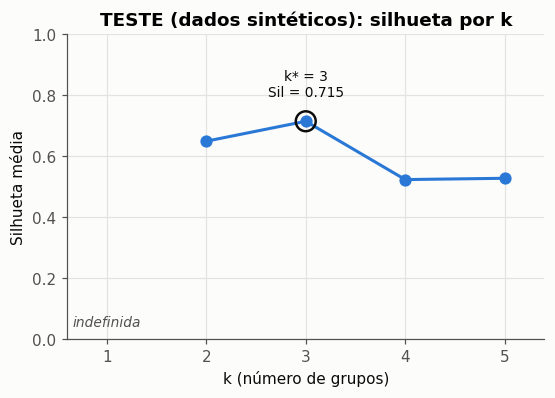

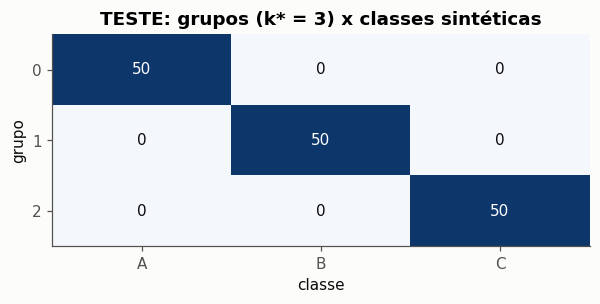

In [ ]:
mostrar_execucoes(exec_a)
grafico_silhueta(aval_a["curva"], "TESTE (dados sintéticos): silhueta por k", aval_a["k_estrela"])
grafico_contingencia(aval_a["contingencia"], f"TESTE: grupos (k* = {aval_a['k_estrela']}) x classes sintéticas")

### 4.9 Busca de hiperparâmetros (experimentos adicionais)

Nas versões anteriores, os hiperparâmetros foram fixados *a priori*, com justificativas da literatura. A busca verifica, para cada algoritmo, se outra configuração seria preferível, e mostra como os resultados variam com esses parâmetros. Ela vem **antes** das execuções oficiais de cada algoritmo, **não usa rótulos** e fica separada delas:

- as configurações da busca são **experimentos adicionais**: ficam em `BUSCAS` e nos arquivos `busca_<algoritmo>.csv`, e não entram no `RESUMO_Q1`;
- as **execuções oficiais** exigidas pelo enunciado são feitas depois, com a configuração escolhida, e são as únicas usadas nos resultados das Seções 5 e 6. Uma célula confere que elas reproduzem exatamente as da configuração escolhida.

**O que é buscado.** Só os hiperparâmetros que o enunciado não fixa e que mudam o modelo ou o resultado. Ficam de fora:

- as distâncias e os métodos exigidos para a nossa dupla 6: Euclidiana no k-medoids; single linkage com city-block;
- o protocolo: $k = 1, \dots, 5$; 10 execuções por $k$; melhor execução pela função objetivo; $k^*$ pela silhueta;
- os controles de parada (tolerâncias e limites de iterações), cuja adequação é verificada pela convergência.

| Algoritmo | Hiperparâmetro | A priori | Grade | Por que esta grade |
|---|---|---|---|---|
| K-means | inicialização | sorteio de $k$ objetos distintos (A3) | sorteio; k-means++ | k-means++ (Arthur & Vassilvitskii, 2007) é a alternativa usual |
| K-medoids | inicialização | sorteio (A3) | sorteio; k-means++; BUILD | BUILD é a inicialização do PAM (Kaufman & Rousseeuw, 1990) |
| FCM | $m$ | 2 | 1,5; 2; 2,5; 3 | faixa recomendada [1,5; 2,5] (Pal & Bezdek, 1995), mais 3 para mostrar a tendência |
| KFCM | largura do kernel ($2\sigma^2$ = quantil $q$ de $\lVert\mathbf x_i-\mathbf x_j\rVert^2$) e $m$ | $q = 0{,}5$ (A7); $m = 2$ (A8) | $q \in$ {0,10; 0,25; 0,50; 0,75; 0,90} × $m \in$ {1,5; 2; 2,5} | a faixa de $q$ da heurística de Caputo et al. (2002) e a de $m$ de Pal & Bezdek (1995) |
| EM | tipo de covariância e regularização | completa (A9); $h^2/12$ | {completa, comum, diagonal, esférica} × {$10^{-6}$; $h^2/12$; $10^{-2}$} | os quatro tipos do scikit-learn; o padrão da biblioteca, o valor adotado e um valor 12 vezes maior |
| Single linkage | nenhum | — | — | método e distância exigidos; as partições são os cortes do protocolo (Seção 5.6) |
| DBSCAN | $\varepsilon$ e `min_samples` | joelho da curva de $k$-distâncias; $2d = 8$ | `min_samples` $\in$ {4, 6, 8, 10, 12, 16} × $\varepsilon \in$ {0,30; 0,35; …; 1,20} cm, mais o joelho de cada `min_samples` | `min_samples` de $d$ a $4d$; $\varepsilon$ do regime fragmentado até o de um único grupo |

**Protocolo de cada configuração.** Nos cinco algoritmos particionais, cada configuração passa pelo procedimento completo do enunciado: 10 execuções por $k$, com as mesmas sementes das execuções oficiais; a melhor execução de cada $k$ pela função objetivo; a silhueta por $k$; e $k^*$. A busca compara, portanto, configurações do **protocolo inteiro**, e não execuções isoladas. O DBSCAN é determinístico: uma execução por configuração.

**Critérios de escolha**, fixados antes de rodar a busca e iguais para todos os algoritmos:

1. **Admissibilidade.** A configuração é descartada se, em algum $k$:
   - a execução escolhida não convergiu; ou
   - a partição escolhida tem menos de $k$ grupos não vazios. Nesse caso, a curva Sil × k compararia partições com menos grupos do que os pedidos.
   - No EM, também se a execução escolhida tem um componente **degenerado**: tamanho efetivo $\sum_i \tau_{ig} < d + 1 = 5$ (com menos objetos, uma covariância completa é singular) ou variância própria, sem a regularização, menor que $h^2/12$ em alguma direção, isto é, abaixo da resolução das medidas (Seção 5.5.1).
   - No DBSCAN, se não houver pelo menos 2 grupos (silhueta indefinida).
2. **Escore.** A silhueta Euclidiana em $k^*$, a mesma régua que escolhe $k^*$ (A5).
   - No DBSCAN, a silhueta média sobre os **150 objetos**, com $s(i) = 0$ para o ruído, igual a (fração de objetos agrupados) × (silhueta sem o ruído).
   - A silhueta sem o ruído aumenta quando o algoritmo descarta como ruído os objetos de fronteira. Contar o ruído com $s(i)=0$ impede que uma configuração seja favorecida só por isso. É o mesmo princípio do fator de cobertura do índice DBCV (Moulavi et al., 2014).
3. **Faixa de tolerância (heurística de um erro-padrão).** O escore é uma média de $n = 150$ valores $s(i)$, e $\mathrm{EP} = \mathrm{dp}(s_i)/\sqrt{n}$ é usado como **escala de tolerância**: as configurações cujo escore fica a menos de um EP do maior escore admissível são tratadas como praticamente indistinguíveis **para fins de escolha**. A regra adapta a regra de um erro-padrão de Hastie, Tibshirani & Friedman (2009, Seção 7.10).
   - É uma **heurística de tolerância e parcimônia**, e **não** um teste nem uma comprovação de equivalência estatística entre configurações.
   - Os valores $s(i)$ não são observações independentes: vêm dos mesmos 150 objetos, a silhueta de cada objeto depende das distâncias a todos os outros, e todas as configurações são avaliadas sobre a mesma base. O EP não tem, portanto, a interpretação de erro-padrão amostral; serve só para fixar, antes da busca, o que conta como uma diferença pequena.
4. **Desempate (parcimônia).** Dentro da faixa de tolerância, fica a configuração *a priori*, que tem justificativa independente dos resultados. Se ela não estiver na faixa, fica a configuração da faixa **mais próxima** dela. A proximidade é comparada hiperparâmetro a hiperparâmetro, na ordem da grade, do mais importante para o menos importante; cada seção declara essa ordem.

Por isso, **a configuração escolhida não é necessariamente a de maior escore numérico da grade**: é a escolhida pelo critério acima, definido antes da busca. Uma configuração *a priori* só é trocada quando a busca mostra uma diferença maior que a tolerância.

**Comportamento.** Além do escore, as tabelas mostram, para cada configuração: a silhueta em cada $k$; o número efetivo de grupos; a função objetivo da melhor execução; a estabilidade (execuções que atingem o melhor valor); e a convergência. Nas tabelas, a configuração escolhida aparece em negrito, as da faixa de tolerância em azul claro e as inadmissíveis em cinza.

**Rótulos (A12).** As funções da busca recebem apenas `X`. O ARI de cada configuração é calculado **depois** da escolha, numa célula separada, só para descrição.

*Referências desta seção:*
- Arthur, D.; Vassilvitskii, S. k-means++: the advantages of careful seeding. *Proceedings of the 18th ACM-SIAM Symposium on Discrete Algorithms (SODA)*, 1027–1035, 2007.
- Hastie, T.; Tibshirani, R.; Friedman, J. *The Elements of Statistical Learning*, 2ª ed. Springer, 2009, Seção 7.10.
- Kaufman, L.; Rousseeuw, P. J. *Finding Groups in Data: An Introduction to Cluster Analysis*. Wiley, 1990.
- Moulavi, D.; Jaskowiak, P. A.; Campello, R. J. G. B.; Zimek, A.; Sander, J. Density-based clustering validation. *Proceedings of the SIAM International Conference on Data Mining (SDM)*, 839–847, 2014.
- Pal, N. R.; Bezdek, J. C. On cluster validity for the fuzzy c-means model. *IEEE Transactions on Fuzzy Systems*, 3(3), 370–379, 1995.

In [ ]:
BUSCAS = {}   # uma entrada por algoritmo: tabela da busca, escolha, partições em k* e execuções
A_PRIORI = {nome: dict(CONFIG[nome]) for nome in ("kmeans", "kmedoids", "fcm", "kfcm", "gmm", "dbscan")}


def silhueta_por_objeto(X, rotulos, ruido=None):
    """Valores s(i) da silhueta, na métrica do critério (A5).

    Com `ruido` (máscara booleana), a silhueta é calculada só entre os objetos agrupados e o ruído
    recebe s(i) = 0: a média sobre todos os objetos é o escore do DBSCAN na busca."""
    agrupados = np.ones(len(X), dtype=bool) if ruido is None else ~np.asarray(ruido)
    s = np.zeros(len(X))
    s[agrupados] = silhouette_samples(X[agrupados], rotulos[agrupados], metric=CONFIG["metrica_silhueta"])
    return s


def erro_padrao(valores):
    """Erro-padrão da média: dp(valores) / √n."""
    return float(np.std(valores, ddof=1) / np.sqrt(len(valores)))


def avaliar_configuracao(algoritmo, sentido, X):
    """Uma configuração pelo protocolo oficial completo, sem rótulos: 10 execuções por k, melhor
    execução pela função objetivo, Sil x k e k*. Devolve o resumo, a partição em k* e as execuções."""
    execucoes = marcar_melhores(executar_particional(algoritmo, X), sentido)
    melhores = execucoes[execucoes["melhor"]].set_index("k")
    curva = curva_silhueta(dict(zip(melhores.index, melhores["rotulos"])), X)
    k_estrela = escolher_k_estrela(curva)
    rotulos = melhores.loc[k_estrela, "rotulos"]
    s = silhueta_por_objeto(X, rotulos)
    assert np.isclose(s.mean(), curva.loc[k_estrela, "silhueta"], rtol=1e-12)
    resumo = {"admissível": bool(melhores["convergiu"].all() and (melhores["n_grupos"] == melhores.index).all()),
              "k*": k_estrela, "Sil(k*)": float(s.mean()), "EP": erro_padrao(s),
              **{f"Sil({k})": curva.loc[k, "silhueta"] for k in CONFIG["valores_k"] if k > 1},
              "grupos efetivos (k=1..5)": melhores["n_grupos"].tolist(),
              "tamanhos em k*": sorted(np.bincount(rotulos).tolist(), reverse=True),
              **{f"objetivo (k={k})": melhores.loc[k, "objetivo"] for k in CONFIG["valores_k"]},
              "no melhor objetivo (k=1..5)": resumo_por_k(execucoes)["objetivo: execuções no melhor valor"].tolist(),
              "convergiram": int(execucoes["convergiu"].sum())}
    pertinencias = melhores.loc[k_estrela, "pertinencias"]
    if pertinencias is not None:
        resumo["pertinência máx. média (k*)"] = float(pertinencias.max(axis=1).mean())
        resumo["pertinência máx. mínima (k*)"] = float(pertinencias.max(axis=1).min())
    return resumo, rotulos, execucoes


def registrar_busca(codigo, titulo, tabela, hiperparametros, particoes, execucoes=None):
    """Guarda uma busca em BUSCAS (experimento adicional: não entra no RESUMO_Q1)."""
    BUSCAS[codigo] = {"titulo": titulo, "tabela": tabela, "hiperparametros": list(hiperparametros),
                      "particoes": particoes, "execucoes": execucoes or {}}


def buscar(codigo, titulo, algoritmo, sentido, configuracoes, X, criterio_extra=None):
    """Aplica avaliar_configuracao a cada configuração (dicionário de hiperparâmetros do algoritmo).

    `criterio_extra(hp, execucoes)`, opcional, devolve (admissível, informações): critérios de
    admissibilidade próprios do algoritmo. Nenhuma etapa usa rótulos."""
    linhas, particoes, execucoes_por_configuracao = [], {}, {}
    for i, hp in enumerate(configuracoes):
        resumo, rotulos, execucoes = avaliar_configuracao(partial(algoritmo, **hp), sentido, X)
        if criterio_extra is not None:
            admissivel, informacoes = criterio_extra(hp, execucoes)
            resumo = {**resumo, **informacoes, "admissível": resumo["admissível"] and admissivel}
        linhas.append({**hp, **resumo})
        particoes[i], execucoes_por_configuracao[i] = rotulos, execucoes
    registrar_busca(codigo, titulo, pd.DataFrame(linhas), configuracoes[0], particoes, execucoes_por_configuracao)


def distancia_a_priori(linha, a_priori, hiperparametros):
    """Proximidade de uma configuração à a priori, comparada em ordem lexicográfica dos hiperparâmetros
    (o primeiro é o mais importante): |diferença| nos numéricos; 0 ou 1 nos categóricos."""
    return tuple(float(abs(linha[h] - a_priori[h])) if isinstance(a_priori[h], (int, float))
                 else float(linha[h] != a_priori[h]) for h in hiperparametros)


def mesma_configuracao(linha, a_priori, hiperparametros):
    return all(d < 1e-12 for d in distancia_a_priori(linha, a_priori, hiperparametros))


def escolher_configuracao(codigo, a_priori, escore="Sil(k*)"):
    """Regra de seleção da Seção 4.9, sem rótulos:
    1. só configurações admissíveis;
    2. a de maior escore e o erro-padrão (EP) desse escore;
    3. faixa de tolerância: escore >= melhor - EP (heurística de um erro-padrão; não é teste estatístico);
    4. dentro da faixa, a a priori (parcimônia); se ela não estiver na faixa, a mais próxima dela.
    A escolhida não é, portanto, necessariamente a de maior escore.
    Empates na etapa 2 ou 4: a primeira configuração na ordem da grade."""
    busca = BUSCAS[codigo]
    tabela = busca["tabela"]
    admissiveis = tabela[tabela["admissível"]]
    if admissiveis.empty:
        raise ValueError(f"{codigo}: nenhuma configuração admissível")
    i_melhor = admissiveis[escore].idxmax()
    limiar = admissiveis.loc[i_melhor, escore] - admissiveis.loc[i_melhor, "EP"]
    na_faixa = admissiveis.index[admissiveis[escore] >= limiar]
    i_escolhida = min(na_faixa, key=lambda i: distancia_a_priori(tabela.loc[i], a_priori, busca["hiperparametros"]))
    busca["tabela"] = tabela.assign(**{"na tolerância (1 EP)": tabela.index.isin(na_faixa),
                                       "escolhida": tabela.index == i_escolhida})
    busca.update(melhor=i_melhor, escolhida=i_escolhida, limiar=float(limiar), escore=escore, a_priori=dict(a_priori))
    return busca["tabela"].loc[i_escolhida]


def indice_a_priori(codigo):
    """Linha da busca que corresponde à configuração a priori."""
    busca = BUSCAS[codigo]
    return next(i for i, linha in busca["tabela"].iterrows()
                if mesma_configuracao(linha, busca["a_priori"], busca["hiperparametros"]))


def descrever(configuracao, hiperparametros):
    formatar = lambda v: f"{v:.4g}" if isinstance(v, (float, np.floating)) else str(v)
    return ", ".join(f"{h} = {formatar(configuracao[h])}" for h in hiperparametros)


def estilo_busca(tabela, codigo, formatos=None):
    """Tabela de uma busca: escolhida em destaque, as da faixa de tolerância em azul claro, inadmissíveis em cinza."""
    marcas = BUSCAS[codigo]["tabela"]

    def estilo(linha):
        m = marcas.loc[linha.name]
        if m["escolhida"]:
            css = "background-color: #cde2fb; font-weight: bold"
        elif m["na tolerância (1 EP)"]:
            css = "background-color: #eef4fb"
        elif not m["admissível"]:
            css = "color: #8a8985"
        else:
            css = ""
        return [css] * len(linha)

    sim_nao = {c: (lambda b: "sim" if b else "não") for c in tabela.columns if tabela[c].dtype == bool}
    return (tabela.style.apply(estilo, axis=1)
            .format({**sim_nao, **(formatos or {})}, precision=4, na_rep="—").hide(axis="index"))


def resumir_escolha(codigo):
    """Imprime o resultado da regra de seleção e grava a tabela completa da busca em CSV."""
    busca = BUSCAS[codigo]
    tabela, hp, escore = busca["tabela"], busca["hiperparametros"], busca["escore"]
    melhor, escolhida = tabela.loc[busca["melhor"]], tabela.loc[busca["escolhida"]]
    a_priori = tabela.loc[indice_a_priori(codigo)]
    print(f"Configurações: {len(tabela)} | admissíveis: {int(tabela['admissível'].sum())} | "
          f"na faixa de tolerância (1 EP): {int(tabela['na tolerância (1 EP)'].sum())}")
    empatadas = int(np.isclose(tabela.loc[tabela["admissível"], escore], melhor[escore], rtol=0, atol=1e-12).sum())
    print(f"Maior escore ({escore}): {melhor[escore]:.4f}, EP = {melhor['EP']:.4f}, em {descrever(melhor, hp)}"
          + (f" (mesmo valor em {empatadas} configurações)" if empatadas > 1 else "")
          + f" -> limiar de tolerância = {busca['limiar']:.4f}")
    print(f"A priori: {descrever(a_priori, hp)} | escore = {a_priori[escore]:.4f} | "
          f"admissível: {'sim' if a_priori['admissível'] else 'não'} | "
          f"na faixa de tolerância: {'sim' if a_priori['na tolerância (1 EP)'] else 'não'}")
    mantida = mesma_configuracao(escolhida, busca["a_priori"], hp)
    print(f"ESCOLHIDA: {descrever(escolhida, hp)} | escore = {escolhida[escore]:.4f} | "
          + ("configuração a priori mantida" if mantida else "a configuração a priori foi SUBSTITUÍDA"))
    if escolhida[escore] < melhor[escore] - 1e-12:
        print(f"Obs.: a escolhida não é a de maior escore numérico ({melhor[escore]:.4f}); foi escolhida pelo critério "
              f"definido antes da busca (faixa de tolerância de 1 EP + preferência pela configuração a priori).")
    tabela.to_csv(DIRS["resultados"] / f"busca_{codigo}.csv", index=False)


def mostrar_busca(codigo, antes=(), extras=(), formatos=None):
    """Tabela da busca de um algoritmo particional e o resultado da regra de seleção."""
    busca = BUSCAS[codigo]
    colunas = [*busca["hiperparametros"], *antes, "admissível", "k*", "Sil(k*)", "EP",
               *[f"Sil({k})" for k in CONFIG["valores_k"] if k > 1],
               "grupos efetivos (k=1..5)", "no melhor objetivo (k=1..5)", "convergiram", *extras]
    display(estilo_busca(busca["tabela"][colunas], codigo, formatos))
    resumir_escolha(codigo)


def fixar_configuracao(codigo, chave):
    """Grava em CONFIG[chave] os hiperparâmetros escolhidos; as execuções oficiais leem estes valores."""
    busca = BUSCAS[codigo]
    escolhida = busca["tabela"].loc[busca["escolhida"]]
    for h in busca["hiperparametros"]:
        valor, antes = escolhida[h], busca["a_priori"][h]
        valor = valor.item() if hasattr(valor, "item") else valor
        CONFIG[chave][h] = valor
        mudou = not mesma_configuracao({h: valor}, {h: antes}, [h])
        print(f"CONFIG['{chave}']['{h}'] = {valor!r}" + (f"   (a priori: {antes!r})" if mudou else "   (a priori, mantido)"))


def mostrar_ari_descritivo(codigo):
    """ARI em k* de cada configuração da busca, calculado DEPOIS da escolha: só descreve, não escolhe."""
    busca = BUSCAS[codigo]
    tabela = busca["tabela"]
    ari = [avaliar_com_classes(busca["particoes"][i])[0] for i in tabela.index]
    descritiva = tabela[busca["hiperparametros"] + ["admissível", "k*", "Sil(k*)", "tamanhos em k*"]].assign(
        **{"ARI(k*) (descritivo)": ari})
    print("ARI em k* de cada configuração, calculado depois da escolha (não participa dela):")
    display(estilo_busca(descritiva, codigo, {"reg_covar": "{:.2e}"} if "reg_covar" in descritiva else None))


def conferir_com_busca(codigo, execucoes):
    """Confere que as execuções oficiais reproduzem exatamente as da configuração escolhida na busca."""
    busca = BUSCAS[codigo]
    da_busca = busca["execucoes"][busca["escolhida"]]
    assert np.array_equal(da_busca["objetivo"].to_numpy(), execucoes["objetivo"].to_numpy())
    assert all(np.array_equal(a, b) for a, b in zip(da_busca["rotulos"], execucoes["rotulos"]))
    print(f"As {len(execucoes)} execuções oficiais reproduzem exatamente as da configuração escolhida na busca.")


Testes das funções da busca, com os dados sintéticos e o algoritmo fictício da Seção 4.7: avaliação de uma configuração, regra de seleção numa tabela fictícia e silhueta com ruído = 0.

In [ ]:
# testes das funções da busca com dados fictícios (nada aqui é experimento sobre a Iris)

# 1. avaliação de uma configuração: protocolo completo, escore = Sil(k*), EP > 0
resumo_t, rotulos_t, _ = avaliar_configuracao(algoritmo_ficticio, "min", X_sint)
assert np.isclose(resumo_t["Sil(k*)"], silhueta(X_sint, rotulos_t)) and resumo_t["EP"] > 0
assert resumo_t["admissível"] and resumo_t["convergiram"] == len(CONFIG["valores_k"]) * CONFIG["n_execucoes"]
print("1. avaliação de uma configuração pelo protocolo completo: OK")

# 2. regra de seleção numa tabela fictícia
registrar_busca("_teste", "teste", pd.DataFrame({"p": [1.0, 2.0, 3.0, 4.0],
                                                 "admissível": [True, True, True, False],
                                                 "Sil(k*)": [0.60, 0.70, 0.69, 0.90], "EP": [0.02] * 4}),
                ["p"], {})
#    a inadmissível (0,90) é ignorada; limiar = 0,70 - 0,02; a priori (p = 3) está na faixa -> mantida
assert escolher_configuracao("_teste", {"p": 3.0})["p"] == 3.0 and np.isclose(BUSCAS["_teste"]["limiar"], 0.68)
assert BUSCAS["_teste"]["tabela"]["na tolerância (1 EP)"].tolist() == [False, True, True, False]
#    a priori (p = 1) fora da faixa de tolerância -> a configuração da faixa mais próxima dela (p = 2)
assert escolher_configuracao("_teste", {"p": 1.0})["p"] == 2.0
#    proximidade lexicográfica, com hiperparâmetro categórico
assert distancia_a_priori(pd.Series({"a": "x", "b": 2.5}), {"a": "x", "b": 2.0}, ["a", "b"]) == (0.0, 0.5)
del BUSCAS["_teste"]
print("2. regra de seleção (admissibilidade, tolerância de 1 EP, preferência pela a priori): OK")

# 3. silhueta com ruído = 0: média sobre todos = (fração agrupada) x (silhueta só dos agrupados)
rotulos_t = y_sint.copy()
rotulos_t[:15] = -1
s_t = silhueta_por_objeto(X_sint, rotulos_t, rotulos_t == -1)
assert (s_t[:15] == 0).all() and np.isclose(s_t.mean(), silhueta(X_sint[15:], rotulos_t[15:]) * 135 / 150)
print("3. silhueta com ruído = 0: OK")


1. avaliação de uma configuração pelo protocolo completo: OK
2. regra de seleção (admissibilidade, tolerância de 1 EP, preferência pela a priori): OK
3. silhueta com ruído = 0: OK


## **5. Questão 1 — Agrupamento**

Todos os algoritmos utilizam a matriz `X` com os atributos brutos (decisão A4) e a infraestrutura da Seção 4. Cada subseção apresenta:

1. Algoritmo e função objetivo;
2. Decisões de implementação;
3. Execuções: 10 por $k$, seleção pela função objetivo e tabelas;
4. Avaliação: Sil × $k$, $k^*$, ARI e tabela de contingência;
5. Verificações da implementação;
6. Comentários baseados nos resultados obtidos.

**Inicialização (decisão A3):**

- **K-means e k-medoids:** começam com $k$ objetos distintos sorteados. Com a mesma semente, utilizam os mesmos objetos em cada execução.
- **FCM:** começa com uma matriz aleatória de pertinências, conforme o método clássico de Bezdek.
- **K-means++:** utilizado apenas como referência nas verificações (Seção 5.1).

o sorteio simples foi escolhido porque segue o protocolo clássico de múltiplas inicializações aleatórias, com seleção pela função objetivo, conforme o enunciado. Além disso, permite comparar k-means e k-medoids a partir dos mesmos objetos iniciais.

### 5.0 Referência para interpretar o ARI

O ARI compara a partição com as **três** espécies. Se $k^* \ne 3$, o ARI não pode chegar a 1, mesmo para uma partição "perfeita" dentro do possível. Para interpretar os valores com justiça, a célula calcula o **maior ARI que qualquer partição em 2 grupos pode atingir** nesta base.

O ARI depende apenas da tabela de contingência. Por isso, basta enumerar quantos objetos de cada espécie vão para o primeiro grupo, $51^3$ combinações, e tomar o máximo. O cálculo usa só os tamanhos das classes e serve apenas para interpretação; não participa de nenhuma escolha.

In [ ]:
def teto_ari_dois_grupos(tamanhos_classes):
    """Maior ARI possível para uma partição em 2 grupos, dados os tamanhos das classes.

    Enumera todas as composições do grupo 1 (quantos objetos de cada classe ele recebe) e calcula
    o ARI pela fórmula de Hubert & Arabie a partir da tabela de contingência."""
    tamanhos = np.asarray(tamanhos_classes)
    grades = np.meshgrid(*[np.arange(t + 1) for t in tamanhos], indexing="ij")
    g1 = np.stack([g.ravel() for g in grades], axis=1)                # composições do grupo 1
    g2 = tamanhos - g1
    validas = (g1.sum(axis=1) > 0) & (g2.sum(axis=1) > 0)             # os dois grupos não vazios
    g1, g2 = g1[validas], g2[validas]
    pares_classes = comb(tamanhos, 2).sum()
    pares_grupos = comb(g1.sum(axis=1), 2) + comb(g2.sum(axis=1), 2)
    pares_juntos = comb(g1, 2).sum(axis=1) + comb(g2, 2).sum(axis=1)
    esperado = pares_grupos * pares_classes / comb(tamanhos.sum(), 2)
    ari = (pares_juntos - esperado) / ((pares_grupos + pares_classes) / 2 - esperado)
    melhor = ari.argmax()
    return ari[melhor], g1[melhor]


TETO_ARI_2, composicao = teto_ari_dois_grupos(np.bincount(y_verdadeiro))
# conferência com o scikit-learn: a partição que separa a classe isolada pela composição ótima
classe_isolada = int(np.flatnonzero(composicao)[0]) if (composicao > 0).sum() == 1 else None
assert classe_isolada is not None and np.isclose(
    avaliar_com_classes((y_verdadeiro == classe_isolada).astype(int))[0], TETO_ARI_2)
print(f"Maior ARI possível com 2 grupos: {TETO_ARI_2:.4f}, obtido ao isolar uma espécie inteira "
      f"(por simetria, qualquer uma das três, já que as classes têm 50 objetos cada).")

Maior ARI possível com 2 grupos: 0.5681, obtido ao isolar uma espécie inteira (por simetria, qualquer uma das três, já que as classes têm 50 objetos cada).


### 5.1 K-means

**Função objetivo (minimizada):** a soma dos quadrados intragrupo

$$J = \sum_{i=1}^{n} \lVert \mathbf{x}_i - \mathbf{c}_{g(i)} \rVert^2 ,$$

em que $g(i)$ é o grupo do objeto $i$ e $\mathbf{c}_g$ é o centróide (média) do grupo $g$.

O algoritmo de Lloyd alterna duas etapas, e nenhuma delas aumenta $J$:

1. atribuir cada objeto ao centróide mais próximo;
2. recalcular cada centróide como a média do seu grupo.

O resultado é um ótimo **local**, que depende da inicialização. Daí as 10 execuções.

**Decisões de implementação** (`sklearn.cluster.KMeans`):

| Parâmetro | Valor | Motivo |
|---|---|---|
| `init` | $k$ objetos distintos sorteados | decisão A3 (a priori); a alternativa k-means++ é avaliada na Seção 5.1.1 |
| `n_init` | 1 | cada execução é exatamente uma inicialização; sem reinícios internos (A2) |
| `algorithm` | `"lloyd"` | o algoritmo clássico descrito acima |
| `tol` | 0 | só para quando a partição deixa de mudar (convergência estrita) |
| `max_iter` | 300 | `CONFIG["kmeans"]`; atingir o limite é registrado como não convergência |

A função objetivo é o `inertia_` do scikit-learn, conferido de forma independente na Seção 5.1.4. Se um grupo esvaziar, o scikit-learn o realoca; isso apareceria no número de grupos e nos avisos.

In [ ]:
def algoritmo_kmeans(X, k, semente, inicializacao=None):
    """K-means (Lloyd) a partir de k objetos iniciais (padrão: CONFIG["kmeans"]["inicializacao"])."""
    inicializacao = CONFIG["kmeans"]["inicializacao"] if inicializacao is None else inicializacao
    iniciais = X[indices_iniciais(X, k, semente, inicializacao)]
    modelo = KMeans(n_clusters=k, init=iniciais, n_init=1, algorithm="lloyd", tol=0.0,
                    max_iter=CONFIG["kmeans"]["max_iter"], random_state=semente).fit(X)
    return {"rotulos": modelo.labels_, "objetivo": modelo.inertia_, "n_iter": modelo.n_iter_,
            "convergiu": modelo.n_iter_ < CONFIG["kmeans"]["max_iter"],
            "prototipos": modelo.cluster_centers_}

#### 5.1.1 Busca de hiperparâmetros: inicialização (experimento adicional)

O número de grupos é fixado pelo protocolo, e a parada (`tol = 0`; `max_iter = 300`) só controla a convergência, verificada em todas as execuções. O único hiperparâmetro livre do k-means de Lloyd é, portanto, a **inicialização**:

| Estratégia | Descrição |
|---|---|
| sorteio (a priori, A3) | $k$ objetos distintos sorteados uniformemente |
| k-means++ | o primeiro centro é sorteado uniformemente; cada novo centro é sorteado com probabilidade proporcional ao quadrado da distância ao centro mais próximo já escolhido (Arthur & Vassilvitskii, 2007). Implementação `sklearn.cluster.kmeans_plusplus`, que testa $2 + \lfloor \ln k \rfloor$ candidatos por centro |

As duas estratégias passam pelo protocolo completo, com as mesmas 50 sementes, e a escolha segue a regra da Seção 4.9. A inicialização não muda o modelo, só o caminho da otimização. Por isso, a tabela mostra também o melhor $J$ de cada $k$ e quantas execuções o atingem, que é o que a inicialização afeta diretamente.

In [ ]:
buscar("kmeans", "K-means", algoritmo_kmeans, "min",
       [{"inicializacao": e} for e in CONFIG["busca"]["kmeans_inicializacao"]], X)
escolher_configuracao("kmeans", A_PRIORI["kmeans"])
mostrar_busca("kmeans", extras=[f"objetivo (k={k})" for k in CONFIG["valores_k"]])
fixar_configuracao("kmeans", "kmeans")

inicializacao,admissível,k*,Sil(k*),EP,Sil(2),Sil(3),Sil(4),Sil(5),grupos efetivos (k=1..5),no melhor objetivo (k=1..5),convergiram,objetivo (k=1),objetivo (k=2),objetivo (k=3),objetivo (k=4),objetivo (k=5)
sorteio,sim,2,0.6808,0.0128,0.6808,0.5526,0.4972,0.4885,"[1, 2, 3, 4, 5]","[10, 10, 4, 2, 1]",50,680.8244,152.3687,78.9408,57.3454,46.5356
k-means++,sim,2,0.6808,0.0128,0.6808,0.5526,0.4972,0.4885,"[1, 2, 3, 4, 5]","[10, 10, 7, 2, 4]",50,680.8244,152.3687,78.9408,57.3454,46.5356


Configurações: 2 | admissíveis: 2 | na faixa de tolerância (1 EP): 2
Maior escore (Sil(k*)): 0.6808, EP = 0.0128, em inicializacao = sorteio (mesmo valor em 2 configurações) -> limiar de tolerância = 0.6680
A priori: inicializacao = sorteio | escore = 0.6808 | admissível: sim | na faixa de tolerância: sim
ESCOLHIDA: inicializacao = sorteio | escore = 0.6808 | configuração a priori mantida
CONFIG['kmeans']['inicializacao'] = 'sorteio'   (a priori, mantido)


In [ ]:
mostrar_ari_descritivo("kmeans")

ARI em k* de cada configuração, calculado depois da escolha (não participa dela):


inicializacao,admissível,k*,Sil(k*),tamanhos em k*,ARI(k*) (descritivo)
sorteio,sim,2,0.6808,"[97, 53]",0.5399
k-means++,sim,2,0.6808,"[97, 53]",0.5399


#### 5.1.2 Execuções oficiais e seleção pela função objetivo

Com a configuração escolhida na Seção 5.1.1. São as execuções exigidas pelo enunciado e as únicas usadas nos resultados.

In [ ]:
exec_kmeans, aval_kmeans = experimento_particional(algoritmo_kmeans, "min", X)
conferir_com_busca("kmeans", exec_kmeans)
mostrar_execucoes(exec_kmeans)
salvar_execucoes(exec_kmeans, "kmeans")

As 50 execuções oficiais reproduzem exatamente as da configuração escolhida na busca.


k,1,2,3,4,5
execucao,,,,,
1,680.8244,152.3687,78.9408,71.3482,49.9171
2,680.8244,152.3687,78.9451,71.3404,49.7486
3,680.8244,152.3687,78.9408,71.6613,46.5356
4,680.8244,152.3687,142.8593,71.3362,49.8764
5,680.8244,152.3687,78.9451,71.3362,49.9171
6,680.8244,152.3687,78.9408,57.4733,53.8582
7,680.8244,152.3687,78.9451,57.3454,46.5616
8,680.8244,152.3687,142.8593,57.3454,69.5334
9,680.8244,152.3687,145.2793,71.6613,53.4760


,melhor objetivo,execução escolhida,escolhida convergiu,grupos na escolhida,objetivo: execuções no melhor valor,partição: execuções idênticas à escolhida,partição: ARI médio das outras com a escolhida,execuções que convergiram
k,,,,,,,,
1,680.8244,1,True,1,10,10,1.0000,10
2,152.3687,1,True,2,10,10,1.0000,10
3,78.9408,1,True,3,4,4,0.8044,10
4,57.3454,7,True,4,2,2,0.6658,10
5,46.5356,3,True,5,1,1,0.6984,10


PosixPath('/tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/etapa9/run/AMNS_Equipe6/resultados/kmeans_execucoes.csv')

#### 5.1.3 Silhueta, $k^*$ e índice de Rand corrigido

,n_grupos,silhueta
k,,
1,1,indefinida
2,2,0.6808
3,3,0.5526
4,4,0.4972
5,5,0.4885


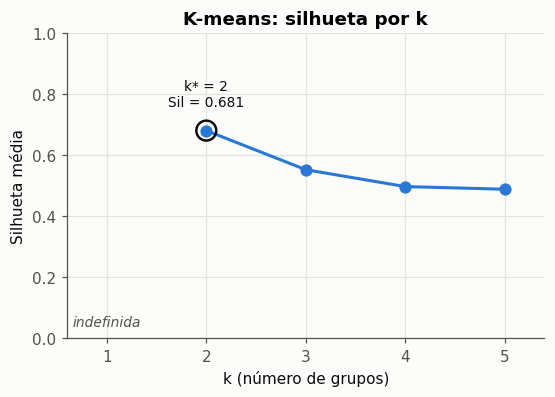

k* = 2 | grupos = 2 | Sil(k*) = 0.6808 | ARI(k*) = 0.5399
Sem avisos: as partições avaliadas convergiram e têm exatamente k grupos.


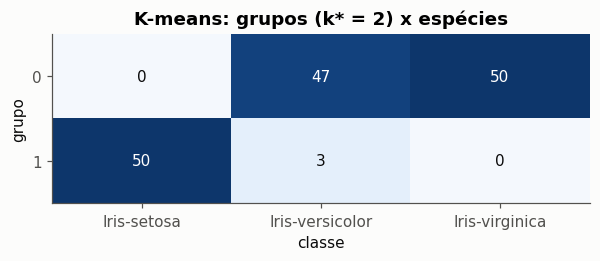

Centróides da partição escolhida em k* = 2 (cm):


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala,objetos
grupo,,,,,
0,6.301,2.887,4.959,1.696,97
1,5.006,3.360,1.562,0.289,53


In [ ]:
apresentar_avaliacao("kmeans", "K-means", aval_kmeans, exec_kmeans)
print(f"Centróides da partição escolhida em k* = {aval_kmeans['k_estrela']} (cm):")
display(tabela_prototipos(exec_kmeans, aval_kmeans["k_estrela"]))

#### 5.1.4 Verificações

Para a melhor execução de cada, são feitas três verificações independentes:

- **Objetivo:** a soma dos quadrados recalculada com os rótulos e centróides deve ser igual ao `inertia_`.
- **Ponto fixo de Lloyd:** cada objeto pertence ao centróide mais próximo, e cada centróide corresponde à média do seu grupo.
- **Caso k=1:** o centróide deve ser a média geral, e o objetivo deve corresponder à soma total dos quadrados.

Como referência, comparamos o melhor objetivo e sua silhueta com os resultados do k-means++ do scikit-learn, usando 10 inicializações internas. Essa comparação não participa da seleção; serve apenas para verificar se o sorteio simples encontrou soluções piores por ficar preso em ótimos locais.

In [ ]:
def verificar_kmeans(execucoes, X):
    """Verificações da execução escolhida em cada k (ver texto acima)."""
    linhas = []
    for _, e in execucoes[execucoes["melhor"]].iterrows():
        c, r = e["prototipos"], e["rotulos"]
        d2 = ((X[:, None, :] - c[None, :, :]) ** 2).sum(axis=2)          # n x k
        d2_proprio = d2[np.arange(len(X)), r]
        referencia = KMeans(n_clusters=e["k"], n_init=10, tol=0.0, random_state=CONFIG["semente_global"]).fit(X)
        linhas.append({"k": e["k"],
                       "J (inertia_)": e["objetivo"],
                       "J recalculado": d2_proprio.sum(),
                       "objetivo confere": np.isclose(d2_proprio.sum(), e["objetivo"], rtol=1e-9),
                       "objeto no centróide mais próximo": bool((d2_proprio <= d2.min(axis=1) + 1e-12).all()),
                       "centróide = média do grupo": all(np.allclose(c[g], X[r == g].mean(axis=0))
                                                         for g in np.unique(r)),
                       "J referência (k-means++)": referencia.inertia_,
                       "Sil escolhida": silhueta(X, r), "Sil referência": silhueta(X, referencia.labels_)})
    tabela = pd.DataFrame(linhas).set_index("k")
    tabela["diferença relativa p/ referência"] = tabela["J recalculado"] / tabela["J referência (k-means++)"] - 1
    return tabela


verif_kmeans = verificar_kmeans(exec_kmeans, X)
display(verif_kmeans)

soma_total = ((X - X.mean(axis=0)) ** 2).sum()
print(f"k = 1: J = {verif_kmeans.loc[1, 'J recalculado']:.6f} | soma total dos quadrados = {soma_total:.6f} "
      f"| (n-1) x soma das variâncias = {(len(X) - 1) * X.var(axis=0, ddof=1).sum():.6f}")
assert verif_kmeans[["objetivo confere", "objeto no centróide mais próximo", "centróide = média do grupo"]].all().all()
assert np.isclose(verif_kmeans.loc[1, "J recalculado"], soma_total)
print("Verificações do k-means: OK")

,J (inertia_),J recalculado,objetivo confere,objeto no centróide mais próximo,centróide = média do grupo,J referência (k-means++),Sil escolhida,Sil referência,diferença relativa p/ referência
k,,,,,,,,,
1,680.824400,680.824400,True,True,True,680.824400,NaN,NaN,0.000000e+00
2,152.368706,152.368706,True,True,True,152.368706,0.680814,0.680814,-2.220446e-16
3,78.940841,78.940841,True,True,True,78.940841,0.552592,0.552592,0.000000e+00
4,57.345409,57.345409,True,True,True,57.317873,0.497228,0.497826,4.804104e-04
5,46.535582,46.535582,True,True,True,46.535582,0.488518,0.488518,0.000000e+00


k = 1: J = 680.824400 | soma total dos quadrados = 680.824400 | (n-1) x soma das variâncias = 680.824400
Verificações do k-means: OK


#### 5.1.5 Comentários

**Busca de hiperparâmetros (Seção 5.1.1).**

- As duas inicializações encontram os mesmos melhores valores de $J$, partições e silhuetas para todos os $k$, resultando em $k^*=2$. Assim, o sorteio (A3) é mantido.
- O k-means++ apresenta maior estabilidade em $k=3$ e $k=5$, mas isso não altera os resultados, pois ambas as inicializações encontram as mesmas melhores soluções.

**Escolha de $k$.**

A maior silhueta ocorre em $k^*=2$ (0,681), diminuindo para 0,553, 0,497 e 0,489 em $k=3,4,5$, respectivamente.

O resultado é coerente com a análise exploratória: os 50 objetos com pétalas pequenas formam o grupo mais separado. Dividir os outros 100 objetos gera grupos menos distintos. A silhueta mede coesão e separação, não o número de espécies.

**ARI e interpretação.**

O ARI obtido é 0,540, próximo do máximo possível para dois grupos e três espécies (0,568).

A contingência mostra que um grupo reúne as 50 setosas e 3 versicolor, enquanto o outro contém as 47 versicolor restantes e as 50 virginica. A principal diferença ocorre porque $k^*=2$ reúne versicolor e virginica.

Os 3 objetos versicolor são agrupados com as setosas porque o k-means considera os quatro atributos simultaneamente, e não apenas o comprimento da pétala. Por isso, a divisão não coincide exatamente com a lacuna identificada na análise exploratória.

**Estabilidade.**

- Para $k=1$ e $k=2$, as 10 execuções encontram a mesma solução.
- A estabilidade diminui com o aumento de $k$: apenas 4 execuções atingem o melhor objetivo em $k=3$, 2 em $k=4$ e 1 em $k=5$.
- Isso reforça a importância das múltiplas inicializações. Neste caso, objetivo e partição apresentam a mesma estabilidade.

**Convergência e verificações.**

- As 50 execuções convergiram em 2 a 16 iterações.
- O objetivo confere com `inertia_`, e as soluções escolhidas satisfazem o ponto fixo de Lloyd.
- Na comparação com o k-means++ do scikit-learn, os melhores objetivos coincidem em quatro dos cinco valores de $k$. Em $k=4$, a diferença é de apenas 0,05%, com silhuetas praticamente iguais.
- Essa diferença é uma limitação das 10 execuções, mas não altera $k^*=2$.

### 5.2 K-medoids (distância Euclidiana)

**Função objetivo (minimizada):** a soma das distâncias Euclidianas, **sem o quadrado**, de cada objeto ao seu medoide

$$J = \sum_{i=1}^{n} d_E\big(\mathbf{x}_i, \mathbf{m}_{g(i)}\big), \qquad \mathbf{m}_g \in \{\mathbf{x}_1,\dots,\mathbf{x}_n\}.$$

Diferenças em relação ao k-means:

- os protótipos (medoides) são **objetos da base**, e não médias;
- a distância não é elevada ao quadrado, o que reduz a influência de objetos distantes.

**Algoritmo.** O PAM clássico (Kaufman & Rousseeuw, 1990) busca uma solução em que **nenhuma troca** de um medoide por um não medoide reduz $J$. Usamos o **FasterPAM** (Schubert & Rousseeuw, 2021), pacote `kmedoids`: ele tem a mesma função objetivo e o mesmo critério de parada do PAM, mas aplica as trocas assim que as encontra e calcula o efeito de cada troca mais rapidamente.

**Decisões de implementação:**

| Parâmetro | Valor | Motivo |
|---|---|---|
| distância | matriz de distâncias Euclidianas, calculada explicitamente | exigência do enunciado para a nossa dupla 6 |
| medoides iniciais | os mesmos $k$ objetos distintos do k-means (mesma semente) | A3 (a priori); a fase BUILD do PAM, determinística, e o k-means++ são avaliados na Seção 5.2.1 |
| `max_iter` | 100 | `CONFIG["kmedoids"]`; atingir o limite é registrado como não convergência |

In [ ]:
def algoritmo_kmedoids(X, k, semente, inicializacao=None):
    """K-medoids (FasterPAM) com distância Euclidiana. Medoides iniciais (padrão: CONFIG["kmedoids"]):
    sorteio de pontos distintos (A3), k-means++ ou a fase BUILD do PAM, que é determinística."""
    inicializacao = CONFIG["kmedoids"]["inicializacao"] if inicializacao is None else inicializacao
    D = squareform(pdist(X, metric="euclidean"))
    if inicializacao == "build":
        iniciais = kmedoids.pam_build(D, k).medoids
    else:
        iniciais = indices_iniciais(X, k, semente, inicializacao)
    resultado = kmedoids.fasterpam(D, np.asarray(iniciais), max_iter=CONFIG["kmedoids"]["max_iter"])
    medoides = resultado.medoids.astype(int)
    return {"rotulos": resultado.labels.astype(int), "objetivo": resultado.loss,
            "n_iter": resultado.n_iter, "convergiu": resultado.n_iter < CONFIG["kmedoids"]["max_iter"],
            "prototipos": X[medoides]}

#### 5.2.1 Busca de hiperparâmetros: inicialização (experimento adicional)

A distância (Euclidiana) é exigida pelo enunciado, e o FasterPAM para quando nenhuma troca reduz $J$. O hiperparâmetro livre é a escolha dos **medoides iniciais**:

| Estratégia | Descrição |
|---|---|
| sorteio (a priori, A3) | os mesmos $k$ objetos distintos do k-means |
| k-means++ | os objetos escolhidos pela semeadura k-means++ (Seção 5.1.1) |
| BUILD | a fase de construção do PAM (Kaufman & Rousseeuw, 1990): escolhe, um a um, o medoide que mais reduz $J$. É **determinística**: as 10 execuções de cada $k$ são idênticas |

Mesma regra de seleção da Seção 4.9.

In [ ]:
buscar("kmedoids", "K-medoids", algoritmo_kmedoids, "min",
       [{"inicializacao": e} for e in CONFIG["busca"]["kmedoids_inicializacao"]], X)
escolher_configuracao("kmedoids", A_PRIORI["kmedoids"])
mostrar_busca("kmedoids", extras=[f"objetivo (k={k})" for k in CONFIG["valores_k"]])
fixar_configuracao("kmedoids", "kmedoids")

inicializacao,admissível,k*,Sil(k*),EP,Sil(2),Sil(3),Sil(4),Sil(5),grupos efetivos (k=1..5),no melhor objetivo (k=1..5),convergiram,objetivo (k=1),objetivo (k=2),objetivo (k=3),objetivo (k=4),objetivo (k=5)
sorteio,sim,2,0.6855,0.0132,0.6855,0.5526,0.4895,0.4865,"[1, 2, 3, 4, 5]","[10, 10, 5, 2, 3]",50,284.7536,129.4129,98.2137,85.7454,79.1750
k-means++,sim,2,0.6855,0.0132,0.6855,0.5526,0.4895,0.4865,"[1, 2, 3, 4, 5]","[10, 10, 6, 4, 7]",50,284.7536,129.4129,98.2137,85.7454,79.1750
build,sim,2,0.6855,0.0132,0.6855,0.5526,0.4913,0.3674,"[1, 2, 3, 4, 5]","[10, 10, 10, 10, 10]",50,284.7536,129.4129,98.2137,85.9578,80.1265


Configurações: 3 | admissíveis: 3 | na faixa de tolerância (1 EP): 3
Maior escore (Sil(k*)): 0.6855, EP = 0.0132, em inicializacao = sorteio (mesmo valor em 3 configurações) -> limiar de tolerância = 0.6722
A priori: inicializacao = sorteio | escore = 0.6855 | admissível: sim | na faixa de tolerância: sim
ESCOLHIDA: inicializacao = sorteio | escore = 0.6855 | configuração a priori mantida
CONFIG['kmedoids']['inicializacao'] = 'sorteio'   (a priori, mantido)


In [ ]:
mostrar_ari_descritivo("kmedoids")

ARI em k* de cada configuração, calculado depois da escolha (não participa dela):


inicializacao,admissível,k*,Sil(k*),tamanhos em k*,ARI(k*) (descritivo)
sorteio,sim,2,0.6855,"[99, 51]",0.5584
k-means++,sim,2,0.6855,"[99, 51]",0.5584
build,sim,2,0.6855,"[99, 51]",0.5584


#### 5.2.2 Execuções oficiais e seleção pela função objetivo

Com a configuração escolhida na Seção 5.2.1.

In [ ]:
exec_kmedoids, aval_kmedoids = experimento_particional(algoritmo_kmedoids, "min", X)
conferir_com_busca("kmedoids", exec_kmedoids)
mostrar_execucoes(exec_kmedoids)
salvar_execucoes(exec_kmedoids, "kmedoids")

As 50 execuções oficiais reproduzem exatamente as da configuração escolhida na busca.


k,1,2,3,4,5
execucao,,,,,
1,284.7536,129.4129,98.2137,85.9578,80.1265
2,284.7536,129.4129,98.2137,85.9578,79.1750
3,284.7536,129.4129,98.2137,85.9578,79.1750
4,284.7536,129.4129,98.9511,85.9578,80.2003
5,284.7536,129.4129,98.9511,85.7454,80.1265
6,284.7536,129.4129,98.2137,85.9578,80.1265
7,284.7536,129.4129,98.9511,85.9578,80.1265
8,284.7536,129.4129,98.9511,85.9578,79.1750
9,284.7536,129.4129,98.9511,85.9578,80.1265


,melhor objetivo,execução escolhida,escolhida convergiu,grupos na escolhida,objetivo: execuções no melhor valor,partição: execuções idênticas à escolhida,partição: ARI médio das outras com a escolhida,execuções que convergiram
k,,,,,,,,
1,284.7536,1,True,1,10,10,1.0000,10
2,129.4129,1,True,2,10,10,1.0000,10
3,98.2137,1,True,3,5,5,0.7985,10
4,85.7454,5,True,4,2,2,0.8604,10
5,79.1750,2,True,5,3,3,0.8113,10


PosixPath('/tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/etapa9/run/AMNS_Equipe6/resultados/kmedoids_execucoes.csv')

#### 5.2.3 Silhueta, $k^*$ e índice de Rand corrigido

,n_grupos,silhueta
k,,
1,1,indefinida
2,2,0.6855
3,3,0.5526
4,4,0.4895
5,5,0.4865


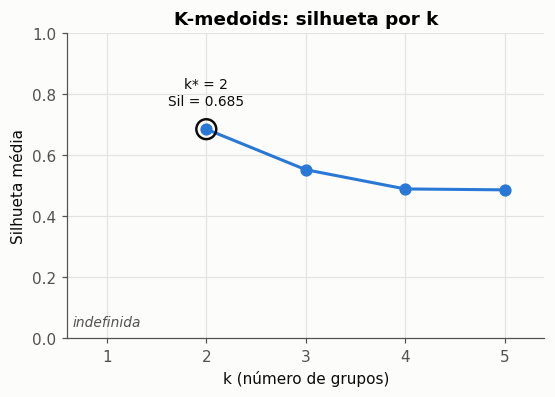

k* = 2 | grupos = 2 | Sil(k*) = 0.6855 | ARI(k*) = 0.5584
Sem avisos: as partições avaliadas convergiram e têm exatamente k grupos.


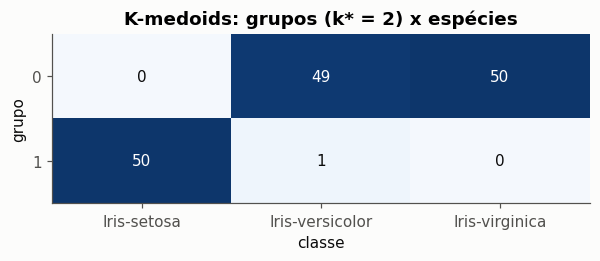

Medoides da partição escolhida em k* = 2 (cm):


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala,objetos
grupo,,,,,
0,6.2,2.8,4.8,1.8,99
1,5.0,3.4,1.5,0.2,51


In [ ]:
apresentar_avaliacao("kmedoids", "K-medoids", aval_kmedoids, exec_kmedoids)
print(f"Medoides da partição escolhida em k* = {aval_kmedoids['k_estrela']} (cm):")
display(tabela_prototipos(exec_kmedoids, aval_kmedoids["k_estrela"]))

#### 5.2.4 Verificações

Para a execução escolhida em cada $k$:

- **objetivo:** a soma das distâncias recalculada é igual ao custo informado pela biblioteca;
- **atribuição:** cada objeto está no medoide mais próximo;
- **medoides são objetos da base;**
- **ótimo local do PAM:** testando **todas** as $k \times (n-k)$ trocas possíveis, nenhuma reduz $J$. É a garantia que o algoritmo oferece;
- **ótimo global, para $k \le 3$:** busca exaustiva entre todos os conjuntos de $k$ pontos distintos. É uma verificação mais forte do que a garantia do algoritmo; para $k \ge 4$, a enumeração fica cara demais.

In [ ]:
def custo_medoides(D, indices):
    """J = soma das distâncias de cada objeto ao medoide mais próximo."""
    return D[:, list(indices)].min(axis=1).sum()


def otimo_global_kmedoids(D, k, candidatos):
    """Menor J possível, por busca exaustiva entre os pontos distintos `candidatos` (viável para k <= 3)."""
    Dc = D[:, candidatos]
    if k == 1:
        return Dc.sum(axis=0).min()
    melhor = np.inf
    for combo in combinations(range(len(candidatos)), k - 1):       # os k-1 primeiros medoides...
        base = Dc[:, list(combo)].min(axis=1)
        resto = Dc[:, combo[-1] + 1:]                                 # ...e todos os possíveis últimos
        if resto.shape[1]:
            melhor = min(melhor, np.minimum(base[:, None], resto).sum(axis=0).min())
    return melhor


def verificar_kmedoids(execucoes, X):
    """Verificações da execução escolhida em cada k (ver texto acima)."""
    D = squareform(pdist(X, metric="euclidean"))
    _, distintos = np.unique(X, axis=0, return_index=True)
    linhas = []
    for _, e in execucoes[execucoes["melhor"]].iterrows():
        k, r = e["k"], e["rotulos"]
        indices = [int(np.flatnonzero((X == p).all(axis=1))[0]) for p in e["prototipos"]]
        J = custo_medoides(D, indices)
        trocas = [custo_medoides(D, indices[:j] + [o] + indices[j + 1:])
                  for j in range(k) for o in range(len(X)) if o not in indices]
        linha = {"k": k, "J (biblioteca)": e["objetivo"], "J recalculado": J,
                 "objetivo confere": np.isclose(J, e["objetivo"], rtol=1e-9),
                 "objeto no medoide mais próximo": bool(np.allclose(D[np.arange(len(X)), np.array(indices)[r]],
                                                                    D[:, indices].min(axis=1))),
                 "nenhuma troca melhora (ótimo local)": bool(min(trocas, default=np.inf) >= J - 1e-9)}
        if k <= 3:
            otimo = otimo_global_kmedoids(D, k, distintos)
            linha["J ótimo global"] = otimo
            linha["atinge o ótimo global"] = bool(np.isclose(J, otimo, rtol=1e-9))
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("k")


verif_kmedoids = verificar_kmedoids(exec_kmedoids, X)
display(verif_kmedoids)
assert verif_kmedoids[["objetivo confere", "objeto no medoide mais próximo",
                       "nenhuma troca melhora (ótimo local)"]].all().all()
print("Verificações do k-medoids: OK")

,J (biblioteca),J recalculado,objetivo confere,objeto no medoide mais próximo,nenhuma troca melhora (ótimo local),J ótimo global,atinge o ótimo global
k,,,,,,,
1,284.753610,284.753610,True,True,True,284.753610,True
2,129.412911,129.412911,True,True,True,129.412911,True
3,98.213677,98.213677,True,True,True,98.213677,True
4,85.745432,85.745432,True,True,True,NaN,NaN
5,79.175049,79.175049,True,True,True,NaN,NaN


Verificações do k-medoids: OK


#### 5.2.5 Comentários


**Busca de hiperparâmetros (Seção 5.2.1).**
- Sorteio e k-means++ chegam ao mesmo melhor $J$ em todos os $k$. O k-means++ é mais estável: 6, 4 e 7 das 10 execuções no melhor valor em $k = 3, 4$ e 5, contra 5, 2 e 3.
- A fase BUILD, determinística, dá 10 execuções idênticas e um $J$ pior em $k = 4$ (85,958 contra 85,745) e em $k = 5$ (80,127 contra 79,175), com silhuetas 0,491 e 0,367. Como todas as execuções partem do mesmo ponto, ela não aproveita as 10 execuções do protocolo.
- Em $k^* = 2$, as três dão a mesma partição (Sil = 0,685). Pela regra da Seção 4.9, ficam na faixa de tolerância, e o sorteio (A3) é mantido.

**Escolha de $k$.** O perfil é o mesmo do k-means. A silhueta é máxima em $k^*=2$ (0,685) e cai para 0,553, 0,489 e 0,487 em $k = 3, 4$ e 5. O motivo é o mesmo: a separação dominante dos dados é a do grupo de pétalas pequenas.

**Índice de Rand corrigido.** ARI($k^*$) = 0,558, ainda mais perto do teto de 0,568 para 2 grupos. Só **1** objeto de versicolor fica no grupo das setosas (51 contra 99), contra 3 no k-means.

A diferença está nos protótipos:
- Os medoides são flores reais: (5,0; 3,4; 1,5; 0,2) e (6,2; 2,8; 4,8; 1,8) cm. O medoide do grupo pequeno tem valores típicos de pétala pequena (comprimento 1,5; largura 0,2).
- O centróide correspondente do k-means (1,56; 0,29) é uma média que inclui os objetos de fronteira do grupo, e por isso está mais perto deles.
- O k-medoids usa distâncias sem o quadrado e protótipos restritos a objetos da base. Assim, objetos de fronteira pesam menos na posição do protótipo, e a fronteira entre os grupos se desloca levemente.

**Qualidade da otimização.**
- Para todos os $k$, a solução escolhida é um ótimo local do PAM: nenhuma das $k(n-k)$ trocas possíveis reduz $J$.
- Para $k = 1, 2$ e 3, a busca exaustiva mostra que a melhor das 10 execuções atinge o **ótimo global**. Para $k \ge 4$, a enumeração é cara demais, e a garantia é a do ótimo local.

**Estabilidade e convergência.**
- As 10 execuções coincidem em $k = 1$ e 2. Atingem o melhor valor 5 de 10 em $k=3$, 2 de 10 em $k=4$ e 3 de 10 em $k=5$. Também aqui, objetivo e partição dão a mesma leitura.
- Todas as execuções convergiram, em 1 a 4 iterações do FasterPAM.

**Observação.** Os valores de $J$ (por exemplo, 129,41 em $k=2$) **não são comparáveis** aos do k-means: aqui se somam distâncias, lá, distâncias ao quadrado. As comparações entre algoritmos usam a silhueta e o ARI.

### 5.3 Fuzzy k-means (FCM)

**Função objetivo (minimizada):**

$$J_m(U, V) = \sum_{i=1}^{n} \sum_{g=1}^{k} u_{ig}^{\,m} \, \lVert \mathbf{x}_i - \mathbf{v}_g \rVert^2, \qquad u_{ig} \in [0,1], \quad \sum_{g=1}^{k} u_{ig} = 1 .$$

Cada objeto tem um grau de pertinência $u_{ig}$ a cada grupo. O expoente $m > 1$ controla o grau de "fuzzificação": com $m \to 1$, a partição se aproxima de uma partição crisp; com $m \to \infty$, as pertinências tendem a $1/k$.

**Algoritmo (Bezdek, 1981).** Otimização alternada, em que nenhuma etapa aumenta $J_m$:

$$\mathbf{v}_g = \frac{\sum_i u_{ig}^{\,m}\,\mathbf{x}_i}{\sum_i u_{ig}^{\,m}}, \qquad
u_{ig} = \left[\sum_{h=1}^{k} \left(\frac{\lVert \mathbf{x}_i - \mathbf{v}_g\rVert}{\lVert \mathbf{x}_i - \mathbf{v}_h\rVert}\right)^{2/(m-1)}\right]^{-1}.$$

O resultado é um ponto estacionário local. Daí as 10 execuções.

**Decisões de implementação** (`skfuzzy.cluster.cmeans`):

| Parâmetro | Valor | Motivo |
|---|---|---|
| $m$ | 2 (a priori) | valor convencional (Bezdek, 1981), centro da faixa recomendada por Pal & Bezdek (1995); busca na Seção 5.3.1 |
| inicialização | matriz $U$ aleatória, com colunas normalizadas, gerada com a semente da execução | A3. Não usamos o `seed` do scikit-fuzzy porque ele altera o gerador global do NumPy |
| parada | $\lVert U_t - U_{t-1}\rVert_F < 10^{-6}$ ou 1000 iterações | atingir o limite é registrado como não convergência |
| função objetivo | $J_m$ calculado para o par $(U, V)$ devolvido | o histórico do scikit-fuzzy registra $J_m(U_{t-1}, V_t)$, um passo atrás; recalculamos para a solução final |
| partição crisp | maior pertinência (A10) | conforme o enunciado, obtida da partição fuzzy |

In [ ]:
def algoritmo_fcm(X, k, semente, m=None):
    """Fuzzy c-means (Bezdek) via scikit-fuzzy, a partir de uma matriz de pertinências aleatória (A3).
    `m`: expoente de fuzzificação (padrão: CONFIG["fcm"]["m"])."""
    p = CONFIG["fcm"]
    m = p["m"] if m is None else m
    rng = np.random.default_rng(semente)
    u0 = rng.random((k, len(X)))
    u0 /= u0.sum(axis=0)                                   # cada objeto: pertinências somam 1
    centros, u, _, _, _, n_iter, _ = skfuzzy.cluster.cmeans(
        X.T, c=k, m=m, error=p["tol"], maxiter=p["max_iter"], init=u0)
    U = u.T                                                # n x k
    d2 = ((X[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2)
    return {"rotulos": particao_crisp(U), "objetivo": ((U ** m) * d2).sum(),
            "n_iter": n_iter, "convergiu": n_iter < p["max_iter"],
            "pertinencias": U, "prototipos": centros}

#### 5.3.1 Busca de hiperparâmetros: expoente $m$ (experimento adicional)

O expoente $m$ controla o grau de sobreposição entre os grupos e não é fixado pelo enunciado. A grade cobre a faixa $[1{,}5;\ 2{,}5]$ recomendada por Pal & Bezdek (1995), cujo centro, $m = 2$, é o valor *a priori*, e acrescenta $m = 3$ para mostrar a tendência fora dela. A tolerância e o limite de iterações não são buscados: são controles de parada, e a convergência é verificada.

Além da regra da Seção 4.9, a tabela mostra a pertinência máxima média e mínima em $k^*$. Quanto maior $m$, menos nítidas as atribuições.

In [ ]:
buscar("fcm", "FCM", algoritmo_fcm, "min", [{"m": m} for m in CONFIG["busca"]["fcm_m"]], X)
escolher_configuracao("fcm", A_PRIORI["fcm"])
mostrar_busca("fcm", extras=["tamanhos em k*", "pertinência máx. média (k*)", "pertinência máx. mínima (k*)"])
fixar_configuracao("fcm", "fcm")

m,admissível,k*,Sil(k*),EP,Sil(2),Sil(3),Sil(4),Sil(5),grupos efetivos (k=1..5),no melhor objetivo (k=1..5),convergiram,tamanhos em k*,pertinência máx. média (k*),pertinência máx. mínima (k*)
1.5000,sim,2,0.6808,0.0128,0.6808,0.5510,0.4960,0.4885,"[1, 2, 3, 4, 5]","[10, 10, 10, 9, 6]",50,"[97, 53]",0.9786,0.5618
2.0000,sim,2,0.6808,0.0128,0.6808,0.5493,0.4925,0.4872,"[1, 2, 3, 4, 5]","[10, 10, 10, 9, 5]",50,"[97, 53]",0.9327,0.5288
2.5000,sim,2,0.6808,0.0128,0.6808,0.5463,0.4914,0.3572,"[1, 2, 3, 4, 5]","[10, 10, 10, 8, 4]",50,"[97, 53]",0.8757,0.5130
3.0000,sim,2,0.6808,0.0128,0.6808,0.5463,0.4917,0.3579,"[1, 2, 3, 4, 5]","[10, 10, 10, 8, 3]",50,"[97, 53]",0.8233,0.5073


Configurações: 4 | admissíveis: 4 | na faixa de tolerância (1 EP): 4
Maior escore (Sil(k*)): 0.6808, EP = 0.0128, em m = 1.5 (mesmo valor em 4 configurações) -> limiar de tolerância = 0.6680
A priori: m = 2 | escore = 0.6808 | admissível: sim | na faixa de tolerância: sim
ESCOLHIDA: m = 2 | escore = 0.6808 | configuração a priori mantida
CONFIG['fcm']['m'] = 2.0   (a priori, mantido)


In [ ]:
mostrar_ari_descritivo("fcm")

ARI em k* de cada configuração, calculado depois da escolha (não participa dela):


m,admissível,k*,Sil(k*),tamanhos em k*,ARI(k*) (descritivo)
1.5000,sim,2,0.6808,"[97, 53]",0.5399
2.0000,sim,2,0.6808,"[97, 53]",0.5399
2.5000,sim,2,0.6808,"[97, 53]",0.5399
3.0000,sim,2,0.6808,"[97, 53]",0.5399


#### 5.3.2 Execuções oficiais e seleção pela função objetivo

Com a configuração escolhida na Seção 5.3.1.

In [ ]:
exec_fcm, aval_fcm = experimento_particional(algoritmo_fcm, "min", X)
conferir_com_busca("fcm", exec_fcm)
mostrar_execucoes(exec_fcm)
salvar_execucoes(exec_fcm, "fcm")

As 50 execuções oficiais reproduzem exatamente as da configuração escolhida na busca.


k,1,2,3,4,5
execucao,,,,,
1,680.8244,128.9233,60.5760,41.6887,32.8058
2,680.8244,128.9233,60.5760,41.6887,32.8799
3,680.8244,128.9233,60.5760,41.6887,32.8058
4,680.8244,128.9233,60.5760,41.6887,32.8058
5,680.8244,128.9233,60.5760,49.5058,32.8799
6,680.8244,128.9233,60.5760,41.6887,32.8799
7,680.8244,128.9233,60.5760,41.6887,32.8058
8,680.8244,128.9233,60.5760,41.6887,32.8058
9,680.8244,128.9233,60.5760,41.6887,32.8799


,melhor objetivo,execução escolhida,escolhida convergiu,grupos na escolhida,objetivo: execuções no melhor valor,partição: execuções idênticas à escolhida,partição: ARI médio das outras com a escolhida,execuções que convergiram
k,,,,,,,,
1,680.8244,1,True,1,10,10,1.0000,10
2,128.9233,6,True,2,10,10,1.0000,10
3,60.5760,9,True,3,10,10,1.0000,10
4,41.6887,2,True,4,9,9,0.9442,10
5,32.8058,8,True,5,5,5,0.7681,10


PosixPath('/tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/etapa9/run/AMNS_Equipe6/resultados/fcm_execucoes.csv')

#### 5.3.3 Silhueta (da partição crisp), $k^*$ e índice de Rand corrigido

Além das saídas padronizadas, a célula resume o grau de pertinência máximo de cada objeto em $k^*$, por grupo crisp, e lista os 5 objetos mais divididos (sem informação de espécie). Quanto mais próximo de 1, mais nítida a atribuição; valores próximos de $1/k^*$ indicam objetos divididos entre grupos. É a informação que a partição crisp descarta.

,n_grupos,silhueta
k,,
1,1,indefinida
2,2,0.6808
3,3,0.5493
4,4,0.4925
5,5,0.4872


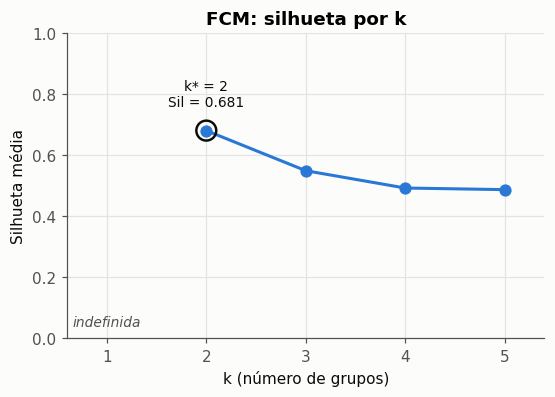

k* = 2 | grupos = 2 | Sil(k*) = 0.6808 | ARI(k*) = 0.5399
Sem avisos: as partições avaliadas convergiram e têm exatamente k grupos.


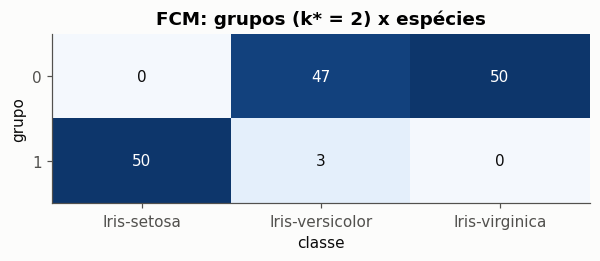

Centros da partição escolhida em k* = 2 (cm):


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala,objetos
grupo,,,,,
0,6.337,2.906,5.014,1.728,97
1,5.023,3.370,1.574,0.289,53


Pertinência máxima por grupo crisp em k* = 2:


,count,mean,min,25%,50%
grupo,,,,,
0,97.0,0.918,0.529,0.885,0.955
1,53.0,0.960,0.548,0.972,0.989


Os 5 objetos mais divididos entre os grupos (atributos em cm e pertinências):


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala,u (grupo 0),u (grupo 1)
objeto,,,,,,
61,5.0,2.0,3.5,1.0,0.529,0.471
94,5.0,2.3,3.3,1.0,0.452,0.548
58,4.9,2.4,3.3,1.0,0.434,0.566
80,5.7,2.6,3.5,1.0,0.613,0.387
99,5.1,2.5,3.0,1.1,0.360,0.640


In [ ]:
apresentar_avaliacao("fcm", "FCM", aval_fcm, exec_fcm)
k_fcm = aval_fcm["k_estrela"]
print(f"Centros da partição escolhida em k* = {k_fcm} (cm):")
display(tabela_prototipos(exec_fcm, k_fcm))

U_fcm = exec_fcm[exec_fcm["melhor"] & (exec_fcm["k"] == k_fcm)].iloc[0]["pertinencias"]
grau_max = pd.Series(U_fcm.max(axis=1), name="pertinência máxima")
print(f"Pertinência máxima por grupo crisp em k* = {k_fcm}:")
display(grau_max.groupby(particao_crisp(U_fcm)).describe()[["count", "mean", "min", "25%", "50%"]]
        .rename_axis("grupo").round(3))

mais_divididos = np.argsort(U_fcm.max(axis=1))[:5]               # 5 menores pertinências máximas
print("Os 5 objetos mais divididos entre os grupos (atributos em cm e pertinências):")
display(df_iris.loc[mais_divididos, ATRIBUTOS].rename(columns=NOMES_CURTOS)
        .assign(**{f"u (grupo {g})": U_fcm[mais_divididos, g].round(3) for g in range(k_fcm)})
        .set_axis(mais_divididos + 1).rename_axis("objeto"))

#### 5.3.4 Verificações

Para a execução escolhida em cada $k$:

- **restrições:** pertinências em $[0,1]$, somando 1 para cada objeto;
- **condições de otimalidade:** $V$ é a média ponderada por $U^m$, e $U$ é a atualização ótima dada $V$, ambas dentro da tolerância de parada. Ou seja, a solução é um ponto estacionário de $J_m$;
- **monotonicidade:** a execução escolhida é repetida a partir da sua semente registrada. A célula confere que $J_m$ nunca cresce ao longo das iterações e que a repetição reproduz o mesmo objetivo;
- **caso $k=1$:** todas as pertinências valem 1, e $J_m$ é a soma total dos quadrados.

In [ ]:
def atualizar_pertinencias(X, V, m):
    """Atualização ótima de U dado V (fórmula de Bezdek), com proteção para distância nula."""
    d = np.sqrt(((X[:, None, :] - V[None, :, :]) ** 2).sum(axis=2))
    d = np.fmax(d, np.finfo(float).eps)
    return 1.0 / ((d[:, :, None] / d[:, None, :]) ** (2 / (m - 1))).sum(axis=2)


def verificar_fcm(execucoes, X):
    """Verificações da execução escolhida em cada k (ver texto acima)."""
    m, linhas = CONFIG["fcm"]["m"], []
    for _, e in execucoes[execucoes["melhor"]].iterrows():
        U, V = e["pertinencias"], e["prototipos"]
        Um = U ** m
        V_de_U = (Um.T @ X) / Um.sum(axis=0)[:, None]
        # Repetição da execução escolhida, agora guardando o histórico do objetivo
        rng = np.random.default_rng(e["semente"])
        u0 = rng.random((e["k"], len(X)))
        u0 /= u0.sum(axis=0)
        *_, historico, _, _ = skfuzzy.cluster.cmeans(X.T, c=e["k"], m=m, error=CONFIG["fcm"]["tol"],
                                                     maxiter=CONFIG["fcm"]["max_iter"], init=u0)
        linhas.append({"k": e["k"], "iterações": e["n_iter"],
                       "pertinências válidas": bool(((U >= 0) & (U <= 1)).all() and np.allclose(U.sum(axis=1), 1)),
                       "max |V - média ponderada(U)| (cm)": np.abs(V - V_de_U).max(),
                       "max |U - atualização(V)|": np.abs(U - atualizar_pertinencias(X, V, m)).max(),
                       "J_m nunca cresce": bool((np.diff(historico) <= 1e-9 * historico[0]).all()),
                       "repetição reproduz o objetivo": bool(np.isclose(
                           algoritmo_fcm(X, e["k"], e["semente"])["objetivo"], e["objetivo"], rtol=1e-12))})
    return pd.DataFrame(linhas).set_index("k")


verif_fcm = verificar_fcm(exec_fcm, X)
display(verif_fcm)
soma_total = ((X - X.mean(axis=0)) ** 2).sum()
J1 = exec_fcm[exec_fcm["melhor"] & (exec_fcm["k"] == 1)]["objetivo"].iloc[0]
print(f"k = 1: J_m = {J1:.6f} | soma total dos quadrados = {soma_total:.6f}")
assert verif_fcm[["pertinências válidas", "J_m nunca cresce", "repetição reproduz o objetivo"]].all().all()
assert (verif_fcm["max |V - média ponderada(U)| (cm)"] < 1e-4).all()
assert (verif_fcm["max |U - atualização(V)|"] < 1e-9).all()
assert np.isclose(J1, soma_total)
print("Verificações do FCM: OK")

,iterações,pertinências válidas,max |V - média ponderada(U)| (cm),max |U - atualização(V)|,J_m nunca cresce,repetição reproduz o objetivo
k,,,,,,
1,1,True,0.000000e+00,0.000000e+00,True,True
2,15,True,2.900005e-08,2.220446e-16,True,True
3,40,True,5.025198e-08,2.220446e-16,True,True
4,63,True,7.839304e-08,2.220446e-16,True,True
5,57,True,4.988683e-08,2.220446e-16,True,True


k = 1: J_m = 680.824400 | soma total dos quadrados = 680.824400
Verificações do FCM: OK


#### 5.3.5 Comentários

**Busca de hiperparâmetros (Seção 5.3.1).**

- Todos os valores de $m$ produzem a mesma partição e $k^*=2$, com silhueta 0,681. Por isso, $m=2$ é mantido.
- O aumento de $m$ torna as pertinências mais distribuídas entre os grupos, mas não altera a escolha de $k^*$.

**Escolha de $k$.**

A maior silhueta ocorre em $k^*=2$ (0,681), diminuindo para 0,549, 0,492 e 0,487 em $k=3,4,5$. O resultado é semelhante ao dos algoritmos anteriores.

**Partição e ARI.**

- O ARI é 0,540, com a mesma divisão do k-means: 50 setosas e 3 versicolor em um grupo; 47 versicolor e 50 virginica no outro.
- Os centros fuzzy são próximos dos centróides do k-means. A silhueta e o ARI também coincidem. A comparação das partições objeto a objeto será feita na Seção 6.

**Informações das pertinências.**

- A pertinência máxima média é alta, mas alguns objetos apresentam valores próximos de 0,5, indicando dúvida entre os grupos.
- Os objetos mais divididos estão próximos da lacuna no comprimento da pétala (Seção 3.4).
- Assim, o FCM identifica objetos na fronteira entre os grupos, informação que se perde na conversão para a partição crisp.

**Estabilidade.**

- As 10 execuções encontram a mesma solução em $k=1,2,3$. Em $k=4$, são 9 de 10; em $k=5$, 5 de 10.
- O FCM apresenta maior estabilidade que o k-means, possivelmente pela função objetivo mais suave.
- Em $k=2$, as 10 partições são idênticas, apesar de pequenas diferenças numéricas no objetivo.

**Convergência e verificações.**

- Todas as execuções convergiram, entre 13 e 73 iterações.
- Os centros e as pertinências satisfazem as condições de otimalidade, e a função objetivo nunca aumenta durante as iterações.
- Para $k=1$, $J_m=680,82$, correspondente à soma total dos quadrados.

**Observação:** o objetivo do FCM (128,92 em $k=2$) é menor que o do k-means (152,37), mas os valores não são diretamente comparáveis, pois utilizam funções objetivo diferentes.

### 5.4 Kernel fuzzy k-means (KFCM)

#### 5.4.1 Formulação adotada: KFCM no espaço de características (KFCM-F)

Um kernel $\mathcal K(\mathbf x,\mathbf y)=\langle\varphi(\mathbf x),\varphi(\mathbf y)\rangle$ permite representar os dados em um espaço de características $\mathcal H$, sem precisar calcular essa transformação explicitamente. O KFCM aplica o FCM nesse espaço.

Existem duas formulações principais (Graves & Pedrycz, 2010; Ferreira & de Carvalho, 2014):

| | **KFCM-F** | **KFCM-K** |
|---|---|---|
| Protótipos | Implícitos em $\mathcal H$ | No espaço original |
| Atualização | Solução exata em forma fechada | Iteração de ponto fixo |
| Monotonicidade de $J$ | Garantida | Não garantida em geral |
| Kernel linear | Equivale exatamente ao FCM | A regra de atualização não se aplica |
| Interpretação em cm | Não permite | Permite |

**Escolha: KFCM-F.** Ambas são formulações válidas, mas o KFCM-F foi escolhido por garantir que a função objetivo não aumente e por coincidir com o FCM quando utilizado o kernel linear. Isso permite validar a implementação com o scikit-fuzzy (Seção 5.3).

A limitação é não possuir protótipos interpretáveis em cm. Por isso, os grupos serão interpretados pelo perfil médio dos seus objetos.

**Função objetivo:**

$$
J_m(U,V)=\sum_{i=1}^{n}\sum_{g=1}^{k}
u_{ig}^{m}\|\varphi(\mathbf x_i)-\mathbf v_g\|^2
$$

com $u_{ig}\in[0,1]$ e $\sum_g u_{ig}=1$.

**Etapa 1: atualização dos protótipos.**

Com as pertinências fixas, os protótipos são calculados por:

$$
\mathbf v_g=
\sum_j w_{jg}\varphi(\mathbf x_j),
\qquad
w_{jg}=\frac{u_{jg}^{m}}{\sum_l u_{lg}^{m}}
$$

Como os protótipos não são calculados diretamente, suas distâncias são obtidas pelo truque do kernel:

$$
d_{ig}^2=K_{ii}-2\sum_j w_{jg}K_{ij}
+\sum_j\sum_l w_{jg}w_{lg}K_{jl}
$$

em que $K_{ij}=\mathcal K(\mathbf x_i,\mathbf x_j)$.

**Etapa 2: atualização das pertinências.**

Com os protótipos fixos, aplica-se a mesma fórmula do FCM, usando as distâncias no espaço de características:

$$
u_{ig}=
\left[
\sum_{h=1}^{k}
\left(\frac{d_{ig}^2}{d_{ih}^2}\right)^{1/(m-1)}
\right]^{-1}
$$

**Propriedades utilizadas na validação:**

- **Monotonicidade:** cada etapa minimiza a função objetivo em relação às variáveis atualizadas. Portanto, $J$ não aumenta durante as iterações (Bezdek, 1981).
- **Objetivo:** como os protótipos são determinados pelas pertinências, usamos $J(U)=J(U,V(U))$ na seleção.
- **Kernel linear:** com $K=XX^\top$, o KFCM-F equivale exatamente ao FCM.
- **Limite $\sigma\to\infty$:** o kernel gaussiano se aproxima do comportamento linear, fazendo as pertinências do KFCM tenderem às do FCM.

**Referências:** Graves & Pedrycz (2010); Ferreira & de Carvalho (2014); Girolami (2002); Bezdek (1981).

#### 5.4.2 Kernel e largura, escolhidos sem rótulos

**Kernel gaussiano**, $\mathcal K(\mathbf x, \mathbf y) = \exp\!\left(-\lVert \mathbf x - \mathbf y\rVert^2 / (2\sigma^2)\right)$:

- é o kernel usual em kernel fuzzy clustering (Graves & Pedrycz, 2010; Ferreira & de Carvalho, 2014);
- é positivo definido (kernel de Mercer);
- depende só da distância Euclidiana, o que é coerente com o espaço bruto adotado na A4;
- tem um único hiperparâmetro.

Nele, $\lVert\varphi(\mathbf x)-\varphi(\mathbf y)\rVert^2 = 2 - 2\mathcal K(\mathbf x,\mathbf y)$: uma função crescente e limitada da distância Euclidiana. Pares distantes ficam todos "igualmente distantes".

**Largura (decisão A7): $2\sigma^2$ = mediana de $\lVert \mathbf x_i - \mathbf x_j \rVert^2$** sobre os pares de objetos não coincidentes.

- A heurística de Caputo et al. (2002), implementada na função `sigest` do pacote R *kernlab*, recomenda que $2\sigma^2$ fique entre os quantis 0,1 e 0,9 das distâncias quadráticas. A mediana é o valor central dessa faixa, e é também a conhecida **heurística da mediana** (Gretton et al., 2012; Garreau et al., 2017).
- A justificativa é uma propriedade da matriz de kernel, e **não** do agrupamento. No par de distância mediana, $\mathcal K = e^{-1} \approx 0{,}37$: o kernel distingue bem pares próximos de pares distantes.
- Nas pontas da faixa isso se perde:
  - com $2\sigma^2$ no quantil 0,1, a maioria dos valores de $\mathcal K$ é quase 0, e o kernel satura: quase todos os pares parecem igualmente distantes;
  - com $2\sigma^2$ no quantil 0,9, a maioria fica próxima de 1, e o KFCM se aproxima do FCM (limite $\sigma\to\infty$ acima), o que tornaria o kernel quase irrelevante.
- A célula abaixo mostra essas propriedades para cada regra.
- Esta é a largura *a priori*. A busca da Seção 5.4.5 avalia outros quantis, em conjunto com $m$.

*Nota de transparência:* no planejamento inicial, propusemos $\sigma^2$ = média dos quantis 0,1 e 0,9. Ao conferir a fonte, vimos que a heurística define uma faixa, e não um ponto, e que aquela regra coloca $2\sigma^2$ acima do quantil 0,9, no regime quase linear. Ela põe $2\sigma^2$ acima do quantil 0,9; a busca da Seção 5.4.5, que não usa rótulos, cobre esse regime com o quantil 0,9.

**Demais parâmetros:**

| Parâmetro | Valor | Motivo |
|---|---|---|
| $m$, tolerância, limite de iterações | os mesmos do FCM (2; $10^{-6}$; 1000) | comparação justa (A8); $m$ é a configuração a priori, buscada com a largura na Seção 5.4.5 |
| inicialização | $U_0$ aleatória, gerada **exatamente como no FCM** | com a mesma semente, a execução $r$ do KFCM parte da mesma $U_0$ que a do FCM (A3) |
| partição crisp | maior pertinência | A10 |
| silhueta | Euclidiana como critério (A5) | a métrica induzida pelo kernel, $\sqrt{2-2\mathcal K}$, como complemento |

In [ ]:
def largura_por_quantil(X, q):
    """σ² tal que 2σ² é o quantil q de ||xi - xj||² entre pares de objetos não coincidentes."""
    d2 = pdist(X, metric="sqeuclidean")
    return float(np.quantile(d2[d2 > 0], q) / 2)


q01, q05, q09 = (2 * largura_por_quantil(X, q) for q in (0.1, 0.5, 0.9))       # valores de 2σ²
REGRAS_LARGURA = {"2σ² = quantil 0,1": q01 / 2, "2σ² = mediana (oficial)": q05 / 2,
                  "2σ² = quantil 0,9": q09 / 2, "σ² = média dos quantis 0,1 e 0,9": (q01 + q09) / 2}

d2_pares = pdist(X, metric="sqeuclidean")
linhas = []
for nome, s2 in REGRAS_LARGURA.items():
    valores_K = np.exp(-d2_pares / (2 * s2))                     # K para todos os pares distintos
    linhas.append({"regra": nome, "2σ² (cm²)": 2 * s2, "σ (cm)": np.sqrt(s2),
                   "mediana de K": np.median(valores_K),
                   "pares com K > 0,9": np.mean(valores_K > 0.9), "pares com K < 0,1": np.mean(valores_K < 0.1)})
display(pd.DataFrame(linhas).set_index("regra").style.format("{:.3f}"))

SIGMA2_KFCM = largura_por_quantil(X, CONFIG["kfcm"]["quantil_largura"])
print(f"Largura oficial: σ² = {SIGMA2_KFCM:.4f} cm² (σ = {np.sqrt(SIGMA2_KFCM):.4f} cm)")

,2σ² (cm²),σ (cm),mediana de K,"pares com K > 0,9","pares com K < 0,1"
regra,,,,,
"2σ² = quantil 0,1",0.360,0.424,0.000,0.005,0.793
2σ² = mediana (oficial),5.570,1.669,0.368,0.157,0.302
"2σ² = quantil 0,9",23.370,3.418,0.788,0.388,0.000
"σ² = média dos quantis 0,1 e 0,9",23.730,3.445,0.791,0.390,0.000


Largura oficial: σ² = 2.7850 cm² (σ = 1.6688 cm)


#### 5.4.3 Implementação

A implementação é própria: nenhuma biblioteca confiável e mantida oferece o KFCM-F. Cada função corresponde a uma equação da Seção 5.4.1.

**Proteções numéricas:**

1. **$d^2$ negativo.** Pela fórmula do truque do kernel, $d^2$ é diferença de números da ordem de 1, e o arredondamento pode produzir valores negativos minúsculos quando o valor verdadeiro é ~0. Eles são truncados em 0.
2. **$d^2 = 0$.** Quando um objeto coincide com o protótipo, a atualização de $U$ dividiria por zero. Aplica-se um piso de $\varepsilon^2 \approx 5\times10^{-32}$, em que $\varepsilon$ é o épsilon de máquina. É o mesmo piso efetivo do scikit-fuzzy, que limita $d$ em $\varepsilon$, e ele faz a pertinência ir para ~1 nesse grupo, como manda o limite da fórmula.
3. **Diagnóstico.** O algoritmo conta quantas vezes cada proteção atuou e registra o menor $d^2$ bruto, para documentar se houve instabilidade (Seção 5.4.8).

In [ ]:
PISO_D2 = np.finfo(float).eps ** 2          # piso para d² (o scikit-fuzzy limita d em eps)


def matriz_kernel(X, kernel, sigma2=None):
    """Matriz de Gram K_ij = <φ(x_i), φ(x_j)> para o kernel linear ou gaussiano."""
    if kernel == "linear":
        return X @ X.T
    if kernel == "gaussiano":
        return np.exp(-squareform(pdist(X, metric="sqeuclidean")) / (2 * sigma2))
    raise ValueError(f"kernel desconhecido: {kernel}")


def distancias_espaco_caracteristicas(K, U, m):
    """d²_ig = ||φ(x_i) - v_g||² pelo truque do kernel, com v_g = Σ_j w_jg φ(x_j) e w_jg = u_jg^m / Σ_l u_lg^m."""
    W = U ** m
    W = W / W.sum(axis=0)                                      # pesos de cada grupo, somando 1
    termo_cruzado = K @ W                                      # Σ_j w_jg K_ij
    norma_prototipo = np.einsum("jg,jl,lg->g", W, K, W)        # Σ_j Σ_l w_jg w_lg K_jl = ||v_g||²
    return np.diag(K)[:, None] - 2 * termo_cruzado + norma_prototipo[None, :]


def atualizar_pertinencias_kernel(D2, m):
    """u_ig = 1 / Σ_h (d²_ig / d²_ih)^(1/(m-1)), com o piso numérico em d²."""
    inverso = np.maximum(D2, PISO_D2) ** (-1.0 / (m - 1))
    return inverso / inverso.sum(axis=1, keepdims=True)


def objetivo_kfcm(K, U, m):
    """J_m(U) = Σ_i Σ_g u_ig^m d²_ig, com os protótipos implícitos determinados por U."""
    return float(((U ** m) * np.maximum(distancias_espaco_caracteristicas(K, U, m), 0.0)).sum())


def kfcm_f(K, U0, m, tol, max_iter, registrar=False):
    """Otimização alternada do KFCM-F a partir de U0 (n x k).

    Para quando ||U_t - U_(t-1)||_F < tol (o mesmo critério do FCM) ou ao atingir max_iter.
    Com registrar=True, guarda J(U_t) a cada iteração."""
    U = U0.copy()
    historico, menor_d2_bruto, n_negativos, n_piso = [], np.inf, 0, 0
    for n_iter in range(1, max_iter + 1):
        D2 = distancias_espaco_caracteristicas(K, U, m)         # etapa 1 (protótipos implícitos)
        menor_d2_bruto = min(menor_d2_bruto, float(D2.min()))
        n_negativos += int((D2 < 0).sum())
        D2 = np.maximum(D2, 0.0)                                # proteção 1
        n_piso += int((D2 < PISO_D2).sum())                     # proteção 2 (aplicada na atualização)
        if registrar:
            historico.append(float(((U ** m) * D2).sum()))       # J(U_t)
        U_novo = atualizar_pertinencias_kernel(D2, m)           # etapa 2
        variacao = float(np.linalg.norm(U_novo - U))
        U = U_novo
        if variacao < tol:
            break
    J = objetivo_kfcm(K, U, m)
    if registrar:
        historico.append(J)
    return {"U": U, "objetivo": J, "n_iter": n_iter, "convergiu": variacao < tol, "historico": historico,
            "menor_d2_bruto": menor_d2_bruto, "d2_negativos": n_negativos, "d2_no_piso": n_piso}


def pertinencias_iniciais(k, n, semente):
    """U0 aleatória com linhas somando 1, gerada exatamente como no FCM (mesma semente -> mesma U0)."""
    rng = np.random.default_rng(semente)
    u0 = rng.random((k, n))
    return (u0 / u0.sum(axis=0)).T


def algoritmo_kfcm(X, k, semente, kernel=None, sigma2=None, quantil_largura=None, m=None, registrar=False):
    """KFCM-F no formato da infraestrutura. Padrões (CONFIG["kfcm"]): kernel gaussiano com 2σ² no
    quantil `quantil_largura` das distâncias quadráticas, e o expoente m; `sigma2` fixa a largura diretamente."""
    p = CONFIG["kfcm"]
    kernel = p["kernel"] if kernel is None else kernel
    m = p["m"] if m is None else m
    if kernel == "gaussiano" and sigma2 is None:
        sigma2 = largura_por_quantil(X, p["quantil_largura"] if quantil_largura is None else quantil_largura)
    resultado = kfcm_f(matriz_kernel(X, kernel, sigma2), pertinencias_iniciais(k, len(X), semente),
                       m, p["tol"], p["max_iter"], registrar)
    saida = {"rotulos": particao_crisp(resultado["U"]), "objetivo": resultado["objetivo"],
             "n_iter": resultado["n_iter"], "convergiu": resultado["convergiu"],
             "pertinencias": resultado["U"]}
    if registrar:
        saida["detalhes"] = resultado
    return saida

#### 5.4.4 Validação da implementação (antes do experimento)

Três testes independentes da álgebra, feitos antes de usar o algoritmo nos dados com o kernel oficial:

1. **Equivalência com o FCM (kernel linear).** Para as **50** sementes do protocolo, o KFCM-F com $K = XX^\top$ é comparado com o FCM do scikit-fuzzy (Seção 5.3) partindo da mesma $U_0$. Devem coincidir as pertinências finais, o número de iterações e a partição crisp.
2. **Limite $\sigma \to \infty$.** Com o kernel gaussiano cada vez mais largo, as pertinências devem se aproximar das do FCM, com diferença proporcional a $1/\sigma^2$ (Seção 5.4.1).
3. **Truque do kernel × coordenadas explícitas.** A matriz de kernel gaussiano é decomposta como $K = \Phi\Phi^\top$ (autovalores e autovetores). As linhas de $\Phi$ são coordenadas explícitas de $\varphi(\mathbf x_i)$ no subespaço gerado pelos dados. Os protótipos e as distâncias são então calculados diretamente nessas coordenadas e comparados com o truque do kernel.

In [ ]:
# Teste 1: kernel linear x FCM do scikit-fuzzy, nas 50 sementes do protocolo
linhas = []
for k in CONFIG["valores_k"]:
    dif_U, mesmas_iter, mesmas_part = 0.0, True, True
    for r in range(1, CONFIG["n_execucoes"] + 1):
        s = semente_execucao(k, r)
        kf, fc = algoritmo_kfcm(X, k, s, kernel="linear", m=CONFIG["fcm"]["m"]), algoritmo_fcm(X, k, s)
        dif_U = max(dif_U, np.abs(kf["pertinencias"] - fc["pertinencias"]).max())
        mesmas_iter &= kf["n_iter"] == fc["n_iter"]
        mesmas_part &= bool((kf["rotulos"] == fc["rotulos"]).all())
    linhas.append({"k": k, "max |U_KFCM - U_FCM|": dif_U, "mesmas iterações (10/10)": mesmas_iter,
                   "mesma partição crisp (10/10)": mesmas_part})
teste_linear = pd.DataFrame(linhas).set_index("k")
display(teste_linear)

# Teste 2: kernel gaussiano cada vez mais largo -> FCM (execução 1 de cada k)
linhas = []
for fator in (1e2, 1e4, 1e6):
    s2 = fator * SIGMA2_KFCM
    dif = max(np.abs(algoritmo_kfcm(X, k, semente_execucao(k, 1), sigma2=s2, m=CONFIG["fcm"]["m"])["pertinencias"]
                     - algoritmo_fcm(X, k, semente_execucao(k, 1))["pertinencias"]).max()
              for k in CONFIG["valores_k"])
    linhas.append({"σ² / σ² oficial": fator, "max |U_KFCM - U_FCM|": dif})
teste_limite = pd.DataFrame(linhas).set_index("σ² / σ² oficial")
display(teste_limite)

# Teste 3: truque do kernel x coordenadas explícitas (kernel oficial, U aleatória, k = 3)
K_oficial = matriz_kernel(X, "gaussiano", SIGMA2_KFCM)
autovalores, autovetores = np.linalg.eigh(K_oficial)
Phi = autovetores * np.sqrt(np.clip(autovalores, 0, None))       # K = Phi Phi^T
U_teste = pertinencias_iniciais(3, len(X), semente_execucao(3, 1))
W_teste = U_teste ** 2 / (U_teste ** 2).sum(axis=0)
prototipos_explicitos = W_teste.T @ Phi
D2_explicito = ((Phi[:, None, :] - prototipos_explicitos[None, :, :]) ** 2).sum(axis=2)
dif_truque = np.abs(distancias_espaco_caracteristicas(K_oficial, U_teste, 2.0) - D2_explicito).max()
print(f"Teste 3: max |d² (truque do kernel) - d² (coordenadas explícitas)| = {dif_truque:.2e}")

assert (teste_linear["max |U_KFCM - U_FCM|"] < 1e-9).all()
assert teste_linear[["mesmas iterações (10/10)", "mesma partição crisp (10/10)"]].all().all()
razoes = teste_limite["max |U_KFCM - U_FCM|"].to_numpy()
assert (razoes[1:] < razoes[:-1] / 50).all()                   # cai ~100x a cada fator 100 em σ²
assert dif_truque < 1e-10
print("Validação da implementação do KFCM-F: OK")

,max |U_KFCM - U_FCM|,mesmas iterações (10/10),mesma partição crisp (10/10)
k,,,
1,0.000000e+00,True,True
2,5.090373e-14,True,True
3,3.166356e-13,True,True
4,1.922684e-12,True,True
5,1.627920e-12,True,True


,max |U_KFCM - U_FCM|
σ² / σ² oficial,
100.0,3.315440e-03
10000.0,3.302652e-05
1000000.0,3.302563e-07


Teste 3: max |d² (truque do kernel) - d² (coordenadas explícitas)| = 2.71e-14
Validação da implementação do KFCM-F: OK


#### 5.4.5 Busca de hiperparâmetros: largura do kernel e $m$ (experimento adicional)

O kernel gaussiano é mantido (Seção 5.4.2). Seus dois hiperparâmetros livres são buscados **em conjunto**, porque interagem: com o kernel limitado, o efeito de $m$ sobre as pertinências depende da largura.

- **Largura:** $2\sigma^2$ = quantil $q$ das distâncias quadráticas entre pares, com $q \in \{0{,}10;\ 0{,}25;\ 0{,}50;\ 0{,}75;\ 0{,}90\}$. É a faixa da heurística de Caputo et al. (2002); $q = 0{,}5$ é a regra *a priori* (A7).
- **Expoente:** $m \in \{1{,}5;\ 2;\ 2{,}5\}$, a faixa de Pal & Bezdek (1995); $m = 2$ é o valor *a priori*, o mesmo do FCM (A8).

A regra de seleção é a da Seção 4.9; no desempate, compara-se primeiro a largura e depois $m$. Esta busca substitui a análise de sensibilidade à largura das versões anteriores e a amplia com $m$.

In [ ]:
buscar("kfcm", "KFCM", algoritmo_kfcm, "min",
       [{"quantil_largura": q, "m": m} for q in CONFIG["busca"]["kfcm_quantil_largura"]
        for m in CONFIG["busca"]["kfcm_m"]], X)
BUSCAS["kfcm"]["tabela"].insert(2, "σ² (cm²)", [largura_por_quantil(X, q)
                                                for q in BUSCAS["kfcm"]["tabela"]["quantil_largura"]])
escolher_configuracao("kfcm", A_PRIORI["kfcm"])
mostrar_busca("kfcm", antes=["σ² (cm²)"],
              extras=["tamanhos em k*", "pertinência máx. média (k*)", "pertinência máx. mínima (k*)"])
fixar_configuracao("kfcm", "kfcm")

# Largura e matriz de kernel finais (a largura é usada também no Kernel PCA, Seção 7.2)
SIGMA2_KFCM = largura_por_quantil(X, CONFIG["kfcm"]["quantil_largura"])
K_oficial = matriz_kernel(X, "gaussiano", SIGMA2_KFCM)
print(f"Largura final: σ² = {SIGMA2_KFCM:.4f} cm² (σ = {np.sqrt(SIGMA2_KFCM):.4f} cm)")

quantil_largura,m,σ² (cm²),admissível,k*,Sil(k*),EP,Sil(2),Sil(3),Sil(4),Sil(5),grupos efetivos (k=1..5),no melhor objetivo (k=1..5),convergiram,tamanhos em k*,pertinência máx. média (k*),pertinência máx. mínima (k*)
0.1000,1.5000,0.1800,não,2,0.6601,0.0191,0.6601,0.6601,0.6601,0.6601,"[1, 2, 2, 2, 2]","[10, 10, 10, 10, 10]",50,"[102, 48]",0.5000,0.5000
0.1000,2.0000,0.1800,não,2,0.6601,0.0191,0.6601,0.6601,0.6601,0.6601,"[1, 2, 2, 2, 2]","[10, 10, 10, 10, 10]",50,"[102, 48]",0.5000,0.5000
0.1000,2.5000,0.1800,não,2,0.6601,0.0191,0.6601,0.6601,0.6601,0.6601,"[1, 2, 2, 2, 2]","[10, 10, 10, 10, 10]",50,"[102, 48]",0.5000,0.5000
0.2500,1.5000,0.5450,sim,2,0.6864,0.0138,0.6864,0.5245,0.4942,0.4579,"[1, 2, 3, 4, 5]","[10, 10, 10, 10, 1]",50,"[100, 50]",0.8300,0.5604
0.2500,2.0000,0.5450,não,2,0.6864,0.0138,0.6864,0.5245,0.5071,0.4900,"[1, 2, 3, 3, 3]","[10, 10, 10, 10, 10]",50,"[100, 50]",0.6601,0.5113
0.2500,2.5000,0.5450,não,2,0.6864,0.0138,0.6864,0.5252,0.5303,0.5141,"[1, 2, 3, 3, 3]","[10, 10, 10, 10, 10]",50,"[100, 50]",0.5466,0.5009
0.5000,1.5000,2.7850,sim,2,0.6855,0.0132,0.6855,0.5493,0.4978,0.4910,"[1, 2, 3, 4, 5]","[10, 10, 10, 8, 8]",50,"[99, 51]",0.9584,0.5129
0.5000,2.0000,2.7850,sim,2,0.6855,0.0132,0.6855,0.5352,0.4946,0.3659,"[1, 2, 3, 4, 5]","[10, 10, 10, 8, 3]",50,"[99, 51]",0.8696,0.5223
0.5000,2.5000,2.7850,sim,2,0.6855,0.0132,0.6855,0.5292,0.4902,0.3662,"[1, 2, 3, 4, 5]","[10, 10, 10, 8, 1]",50,"[99, 51]",0.7921,0.5088
0.7500,1.5000,7.5125,sim,2,0.6855,0.0132,0.6855,0.5493,0.4963,0.4897,"[1, 2, 3, 4, 5]","[10, 10, 10, 9, 6]",50,"[99, 51]",0.9728,0.5015


Configurações: 15 | admissíveis: 10 | na faixa de tolerância (1 EP): 10
Maior escore (Sil(k*)): 0.6864, EP = 0.0138, em quantil_largura = 0.25, m = 1.5 -> limiar de tolerância = 0.6726
A priori: quantil_largura = 0.5, m = 2 | escore = 0.6855 | admissível: sim | na faixa de tolerância: sim
ESCOLHIDA: quantil_largura = 0.5, m = 2 | escore = 0.6855 | configuração a priori mantida
Obs.: a escolhida não é a de maior escore numérico (0.6864); foi escolhida pelo critério definido antes da busca (faixa de tolerância de 1 EP + preferência pela configuração a priori).
CONFIG['kfcm']['quantil_largura'] = 0.5   (a priori, mantido)
CONFIG['kfcm']['m'] = 2.0   (a priori, mantido)
Largura final: σ² = 2.7850 cm² (σ = 1.6688 cm)


In [ ]:
mostrar_ari_descritivo("kfcm")

ARI em k* de cada configuração, calculado depois da escolha (não participa dela):


quantil_largura,m,admissível,k*,Sil(k*),tamanhos em k*,ARI(k*) (descritivo)
0.1000,1.5000,não,2,0.6601,"[102, 48]",0.5199
0.1000,2.0000,não,2,0.6601,"[102, 48]",0.5199
0.1000,2.5000,não,2,0.6601,"[102, 48]",0.5199
0.2500,1.5000,sim,2,0.6864,"[100, 50]",0.5681
0.2500,2.0000,não,2,0.6864,"[100, 50]",0.5681
0.2500,2.5000,não,2,0.6864,"[100, 50]",0.5681
0.5000,1.5000,sim,2,0.6855,"[99, 51]",0.5584
0.5000,2.0000,sim,2,0.6855,"[99, 51]",0.5584
0.5000,2.5000,sim,2,0.6855,"[99, 51]",0.5584
0.7500,1.5000,sim,2,0.6855,"[99, 51]",0.5584


#### 5.4.6 Execuções oficiais e seleção pela função objetivo

Kernel gaussiano, com a largura e o $m$ escolhidos na Seção 5.4.5.

In [ ]:
exec_kfcm, aval_kfcm = experimento_particional(algoritmo_kfcm, "min", X)
conferir_com_busca("kfcm", exec_kfcm)
mostrar_execucoes(exec_kfcm)
salvar_execucoes(exec_kfcm, "kfcm")

As 50 execuções oficiais reproduzem exatamente as da configuração escolhida na busca.


k,1,2,3,4,5
execucao,,,,,
1,83.4199,29.2068,16.2193,11.5961,9.1095
2,83.4199,29.2068,16.2193,12.8577,9.1095
3,83.4199,29.2068,16.2193,11.5961,9.3129
4,83.4199,29.2068,16.2193,11.5961,9.3129
5,83.4199,29.2068,16.2193,11.5961,9.3129
6,83.4199,29.2068,16.2193,11.5961,9.1095
7,83.4199,29.2068,16.2193,11.5961,9.3129
8,83.4199,29.2068,16.2193,11.5961,9.3129
9,83.4199,29.2068,16.2193,12.8577,9.3129


,melhor objetivo,execução escolhida,escolhida convergiu,grupos na escolhida,objetivo: execuções no melhor valor,partição: execuções idênticas à escolhida,partição: ARI médio das outras com a escolhida,execuções que convergiram
k,,,,,,,,
1,83.4199,1,True,1,10,10,1.0000,10
2,29.2068,4,True,2,10,10,1.0000,10
3,16.2193,4,True,3,10,10,1.0000,10
4,11.5961,5,True,4,8,8,0.8915,10
5,9.1095,6,True,5,3,3,0.7380,10


PosixPath('/tmp/claude-0/-home-claude/5edbf354-5571-5aeb-a687-a6d6cdbbb7c1/scratchpad/etapa9/run/AMNS_Equipe6/resultados/kfcm_execucoes.csv')

#### 5.4.7 Silhueta (da partição crisp), $k^*$ e índice de Rand corrigido

Além das saídas padronizadas, a célula mostra:

- a silhueta na métrica induzida pelo kernel, $\sqrt{2 - 2\mathcal K}$, como complemento (A5);
- o perfil dos grupos em $k^*$. O KFCM-F não tem protótipos no espaço original, então o perfil usa as médias dos objetos de cada grupo crisp;
- o resumo das pertinências máximas e os 5 objetos mais divididos entre os grupos.

,n_grupos,silhueta
k,,
1,1,indefinida
2,2,0.6855
3,3,0.5352
4,4,0.4946
5,5,0.3659


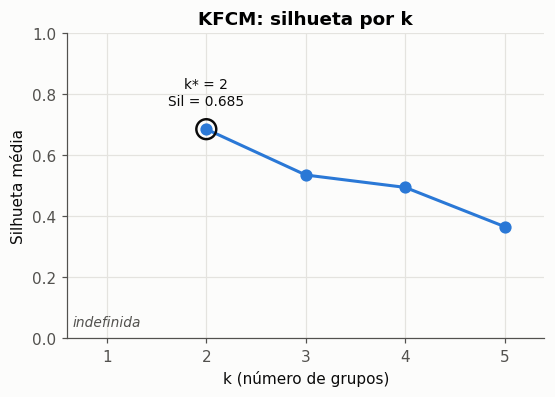

k* = 2 | grupos = 2 | Sil(k*) = 0.6855 | ARI(k*) = 0.5584
Sem avisos: as partições avaliadas convergiram e têm exatamente k grupos.


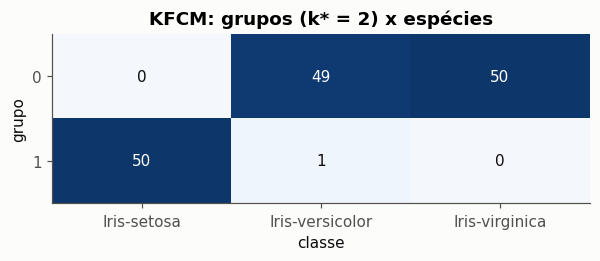

,Sil Euclidiana (critério),Sil métrica do kernel (complemento)
k,,
1,indefinida,indefinida
2,0.6855,0.5263
3,0.5352,0.4602
4,0.4946,0.4452
5,0.3659,0.3410


Complemento (A5): com a silhueta na métrica do kernel, k* seria 2 (igual do critério Euclidiano).

Perfil dos grupos crisp em k* = 2 (médias dos objetos, em cm):


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala,objetos
grupo,,,,,
0,6.274,2.876,4.925,1.682,99
1,5.008,3.400,1.494,0.261,51


Pertinência máxima por grupo crisp em k* = 2:


,count,mean,min,25%,50%
grupo,,,,,
0,99.0,0.838,0.522,0.788,0.868
1,51.0,0.932,0.528,0.915,0.956


Os 5 objetos mais divididos entre os grupos (atributos em cm e pertinências):


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala,u (grupo 0),u (grupo 1)
objeto,,,,,,
58,4.9,2.4,3.3,1.0,0.522,0.478
99,5.1,2.5,3.0,1.1,0.472,0.528
94,5.0,2.3,3.3,1.0,0.533,0.467
61,5.0,2.0,3.5,1.0,0.575,0.425
119,7.7,2.6,6.9,2.3,0.622,0.378


In [ ]:
apresentar_avaliacao("kfcm", "KFCM", aval_kfcm, exec_kfcm)

melhores_kfcm = exec_kfcm[exec_kfcm["melhor"]].set_index("k")
D_kernel = np.sqrt(np.maximum(2 - 2 * K_oficial, 0))             # métrica induzida pelo kernel
curva_kernel = curva_silhueta(dict(zip(melhores_kfcm.index, melhores_kfcm["rotulos"])), D_kernel, "precomputed")
display(pd.DataFrame({"Sil Euclidiana (critério)": aval_kfcm["curva"]["silhueta"],
                      "Sil métrica do kernel (complemento)": curva_kernel["silhueta"]})
        .style.format("{:.4f}", na_rep="indefinida"))
k_kernel = escolher_k_estrela(curva_kernel)
print(f"Complemento (A5): com a silhueta na métrica do kernel, k* seria {k_kernel} "
      f"({'igual' if k_kernel == aval_kfcm['k_estrela'] else 'DIFERENTE'} do critério Euclidiano).")

k_kf = aval_kfcm["k_estrela"]
U_kf, rot_kf = melhores_kfcm.loc[k_kf, "pertinencias"], melhores_kfcm.loc[k_kf, "rotulos"]
print(f"\nPerfil dos grupos crisp em k* = {k_kf} (médias dos objetos, em cm):")
display(df_iris[ATRIBUTOS].rename(columns=NOMES_CURTOS).groupby(rot_kf).mean().round(3)
        .assign(objetos=np.bincount(rot_kf)).rename_axis("grupo"))

print(f"Pertinência máxima por grupo crisp em k* = {k_kf}:")
display(pd.Series(U_kf.max(axis=1), name="pertinência máxima").groupby(rot_kf).describe()
        [["count", "mean", "min", "25%", "50%"]].rename_axis("grupo").round(3))
mais_divididos = np.argsort(U_kf.max(axis=1))[:5]
print("Os 5 objetos mais divididos entre os grupos (atributos em cm e pertinências):")
display(df_iris.loc[mais_divididos, ATRIBUTOS].rename(columns=NOMES_CURTOS)
        .assign(**{f"u (grupo {g})": U_kf[mais_divididos, g].round(3) for g in range(k_kf)})
        .set_axis(mais_divididos + 1).rename_axis("objeto"))

#### 5.4.8 Verificações das soluções e diagnóstico numérico

Cada execução é repetida a partir da sua semente registrada, agora guardando o histórico. A célula confere:

- **reprodutibilidade:** a repetição dá o mesmo $J$;
- **restrições:** pertinências em $[0,1]$, somando 1 para cada objeto;
- **monotonicidade:** $J(U_t)$ nunca cresce, em **todas** as 50 execuções e não só nas escolhidas;
- **convergência:** todas as execuções atingiram $\lVert\Delta U\rVert_F < 10^{-6}$;
- **condição de ponto fixo:** $U$ coincide com a sua própria atualização, ou seja, $U$ é ótima dados os protótipos que ela define;
- **caso $k=1$:** $U \equiv 1$ e $J = \sum_i K_{ii} - \frac{1}{n}\sum_{i,j} K_{ij}$, a dispersão total no espaço de características;
- **diagnóstico numérico:** menor autovalor de $K$ (deve ser $\ge 0$ a menos de arredondamento, pois o kernel gaussiano é positivo definido), menor $d^2$ bruto e quantas vezes cada proteção numérica atuou.

In [ ]:
m_kf = CONFIG["kfcm"]["m"]
linhas = []
for _, e in exec_kfcm.iterrows():
    det = algoritmo_kfcm(X, e["k"], e["semente"], registrar=True)["detalhes"]
    hist = np.array(det["historico"])
    U = det["U"]
    D2 = np.maximum(distancias_espaco_caracteristicas(K_oficial, U, m_kf), 0)
    linhas.append({"k": e["k"], "execucao": e["execucao"], "melhor": e["melhor"],
                   "reproduz J": np.isclose(det["objetivo"], e["objetivo"], rtol=1e-12),
                   "restrições": bool(((U >= 0) & (U <= 1)).all() and np.allclose(U.sum(axis=1), 1)),
                   "J nunca cresce": bool((np.diff(hist) <= 1e-12 * hist[0]).all()),
                   "maior variação de J (≤ 0)": float(np.diff(hist).max()) if len(hist) > 1 else 0.0,
                   "convergiu": det["convergiu"],
                   "max |U - atualização(U)|": float(np.abs(U - atualizar_pertinencias_kernel(D2, m_kf)).max()),
                   "menor d² bruto": det["menor_d2_bruto"], "d² < 0 truncados": det["d2_negativos"],
                   "d² no piso": det["d2_no_piso"]})
verif_kfcm = pd.DataFrame(linhas)

print("Execuções escolhidas:")
display(verif_kfcm[verif_kfcm["melhor"]].drop(columns=["execucao", "melhor"]).set_index("k"))
print("Todas as 50 execuções:")
display(pd.Series({
    "reproduzem J": int(verif_kfcm["reproduz J"].sum()),
    "respeitam as restrições": int(verif_kfcm["restrições"].sum()),
    "J nunca cresce": int(verif_kfcm["J nunca cresce"].sum()),
    "convergiram": int(verif_kfcm["convergiu"].sum()),
    "maior max |U - atualização(U)|": verif_kfcm["max |U - atualização(U)|"].max(),
    "menor d² bruto": verif_kfcm["menor d² bruto"].min(),
    "d² < 0 truncados (total)": int(verif_kfcm["d² < 0 truncados"].sum()),
    "d² no piso (total)": int(verif_kfcm["d² no piso"].sum()),
    "menor autovalor de K": float(np.linalg.eigvalsh(K_oficial).min())}, name="valor").to_frame())

J1_formula = np.trace(K_oficial) - K_oficial.sum() / len(X)
J1_exec = exec_kfcm[exec_kfcm["melhor"] & (exec_kfcm["k"] == 1)]["objetivo"].iloc[0]
print(f"k = 1: J = {J1_exec:.6f} | dispersão total no espaço de características = {J1_formula:.6f}")

assert verif_kfcm[["reproduz J", "restrições", "J nunca cresce", "convergiu"]].all().all()
assert (verif_kfcm["max |U - atualização(U)|"] < 1e-5).all()
assert np.isclose(J1_exec, J1_formula, rtol=1e-12)
print("Verificações do KFCM: OK")

Execuções escolhidas:


,reproduz J,restrições,J nunca cresce,maior variação de J (≤ 0),convergiu,max |U - atualização(U)|,menor d² bruto,d² < 0 truncados,d² no piso
k,,,,,,,,,
1,True,True,True,0.000000e+00,True,0.000000e+00,0.327866,0,0
2,True,True,True,-1.076472e-12,True,3.438327e-08,0.018053,0,0
3,True,True,True,-7.212009e-13,True,8.556734e-08,0.006392,0,0
4,True,True,True,-4.689582e-13,True,1.195097e-07,0.004720,0,0
5,True,True,True,-2.806644e-13,True,1.086393e-07,0.006680,0,0


Todas as 50 execuções:


,valor
reproduzem J,5.000000e+01
respeitam as restrições,5.000000e+01
J nunca cresce,5.000000e+01
convergiram,5.000000e+01
maior max |U - atualização(U)|,1.674886e-07
menor d² bruto,3.921704e-03
d² < 0 truncados (total),0.000000e+00
d² no piso (total),0.000000e+00
menor autovalor de K,-5.620745e-17


k = 1: J = 83.419861 | dispersão total no espaço de características = 83.419861
Verificações do KFCM: OK


#### 5.4.9 Comentários

**Validação da implementação.** Os testes da Seção 5.4.4 confirmam a implementação:
- **Kernel linear:** as pertinências coincidem com as do FCM do scikit-fuzzy nas 50 sementes, com diferença máxima de \(2\times10^{-12}\).
- **Limite \(\sigma\to\infty\):** a diferença em relação ao FCM diminui conforme previsto (\(1/\sigma^2\)).
- **Truque do kernel:** as distâncias coincidem com as calculadas diretamente, com diferença máxima de \(3\times10^{-14}\).

**Largura do kernel.** A regra oficial resulta em \(\sigma^2=2{,}785\) cm². A mediana do kernel é 0,368, indicando boa distinção entre pares próximos e distantes. Já o quantil 0,1 causa saturação, enquanto o quantil 0,9 e a média dos quantis aproximam o KFCM do FCM.

**Escolha de \(k\).** As duas métricas indicam \(k^*=2\): silhueta Euclidiana de 0,685 e silhueta na métrica do kernel de 0,526.

**ARI e distribuição dos grupos.**: O ARI foi 0,558. A partição é igual à do k-medoids: um grupo reúne 50 setosas e 1 versicolor; o outro, 49 versicolor e 50 virginicas. Em relação ao FCM, o KFCM desloca a fronteira entre os grupos. O objeto 99 fica no grupo menor, com pertinência 0,528.

**Efeito do kernel nas pertinências.**: As pertinências são menos definidas que no FCM, pois as distâncias no espaço do kernel são limitadas. Assim, objetos distantes dos dois protótipos podem apresentar pertinências próximas de \(1/k\). Isso ocorre especialmente com o objeto 119, que está entre os cinco mais divididos (0,622 e 0,378), apesar de estar distante da fronteira entre os grupos.

**Estabilidade e verificações.**: Todas as 50 execuções convergiram. As 10 execuções encontraram a mesma partição em \(k=1,2,3\); em \(k=4\), isso ocorreu em 8, e em \(k=5\), em 3. O objetivo não aumentou, as restrições foram respeitadas e as verificações numéricas foram satisfeitas. As proteções contra valores inválidos não precisaram atuar.

**Busca de largura e \(m\) (Seção 5.4.5).**: Todas as 15 configurações indicaram \(k^*=2\). A busca mostrou que:
- Kernels estreitos podem causar saturação e colapso dos grupos.
- Kernels largos aproximam o resultado do FCM.
- A maior silhueta foi 0,686 (\(q=0{,}25\), \(m=1{,}5\)). A configuração *a priori* (\(q=0{,}5\), \(m=2\)) obteve 0,685, diferença menor que a tolerância de 1 EP (0,014). Por isso, foi mantida.
- Aumentar \(m\) reduz a nitidez das pertinências.

Portanto, a busca não encontrou alternativa admissível que superasse a configuração *a priori* além da tolerância definida.

Referências desta seção:
- Bezdek, J. C. *Pattern Recognition with Fuzzy Objective Function Algorithms*. Plenum, 1981.
- Caputo, B.; Sim, K.; Furesjo, F.; Smola, A. Appearance-based object recognition using SVMs: which kernel should I use? *NIPS Workshop on Statistical Methods for Computational Experiments in Visual Processing and Computer Vision*, 2002 (heurística implementada em `kernlab::sigest`).
- Ferreira, M. R. P.; de Carvalho, F. A. T. Kernel fuzzy c-means with automatic variable weighting. *Fuzzy Sets and Systems*, 237, 1–46, 2014.
- Garreau, D.; Jitkrittum, W.; Kanagawa, M. Large sample analysis of the median heuristic. arXiv:1707.07269, 2017.
- Girolami, M. Mercer kernel-based clustering in feature space. *IEEE Transactions on Neural Networks*, 13(3), 780–784, 2002.
- Graves, D.; Pedrycz, W. Kernel-based fuzzy clustering and fuzzy clustering: a comparative experimental study. *Fuzzy Sets and Systems*, 161(4), 522–543, 2010.
- Gretton, A.; Borgwardt, K. M.; Rasch, M. J.; Schölkopf, B.; Smola, A. A kernel two-sample test. *Journal of Machine Learning Research*, 13, 723–773, 2012.
- Pal, N. R.; Bezdek, J. C. On cluster validity for the fuzzy c-means model. *IEEE Transactions on Fuzzy Systems*, 3(3), 370–379, 1995.

### 5.5 Mistura de gaussianas (EM)

**Modelo.** Os objetos são tratados como amostras de uma mistura de $k$ distribuições normais:

$$p(\mathbf{x}) = \sum_{g=1}^{k} \pi_g \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_g, \boldsymbol{\Sigma}_g), \qquad \pi_g \ge 0, \quad \sum_g \pi_g = 1 .$$

**Função objetivo (maximizada):** a log-verossimilhança

$$\ell = \sum_{i=1}^{n} \log \sum_{g=1}^{k} \pi_g \, \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_g, \boldsymbol{\Sigma}_g).$$

**Algoritmo EM** (Dempster, Laird & Rubin, 1977). Alterna duas etapas:

- **E:** calcula as probabilidades a posteriori $\tau_{ig} = P(g \mid \mathbf{x}_i)$ de cada objeto pertencer a cada componente.
- **M:** reestima $\pi_g$, $\boldsymbol{\mu}_g$ e $\boldsymbol{\Sigma}_g$ como médias ponderadas por $\tau_{ig}$.

O resultado é um máximo **local**. A partição crisp atribui cada objeto ao componente de maior $\tau_{ig}$ (regra MAP, decisão A10), como pede o enunciado.

**Decisões de implementação** (`sklearn.mixture.GaussianMixture`):

| Parâmetro | Valor | Motivo |
|---|---|---|
| covariância | completa (`"full"`): cada componente tem a sua matriz | a priori (A9); evidência sem rótulos e busca na Seção 5.5.1 |
| regularização | $h^2/12 = 0{,}00083$ cm² somado à diagonal de cada $\boldsymbol{\Sigma}_g$ | decisão metodológica para evitar soluções degeneradas; justificativa, alternativas e busca na Seção 5.5.1 |
| inicialização | médias = os mesmos $k$ objetos distintos do k-means (A3); pesos iguais; covariâncias = a covariância global | sem a inicialização interna do scikit-learn, que executaria um k-means oculto |
| parada | variação da log-verossimilhança média $< 10^{-6}$, ou 1000 iterações | `CONFIG["gmm"]` |
| função objetivo | $\ell$ calculada com os parâmetros finais ($n \times$ `score`) | o `lower_bound_` do scikit-learn é calculado antes da última etapa M |

#### 5.5.1 Tipo de covariância e regularização: evidência a priori e busca

**Tipo de covariância (A9).** Avaliamos as correlações dentro dos dois lados da lacuna no comprimento da pétala, evitando misturar diferenças entre grupos. Correlações fortes ou diferentes entre os lados podem indicar que modelos diagonais, esféricos ou com covariância compartilhada não são adequados.

**Regularização.** Como a mistura gaussiana pode gerar componentes com variância próxima de zero, adotamos \(h^2/12\), com \(h=0{,}1\) cm, correspondente à variância do erro de arredondamento das medidas. Essa escolha considera a precisão dos dados, embora outras formas de regularização também sejam possíveis.

**Busca adicional, sem rótulos.** Testamos 12 configurações, combinando quatro tipos de covariância (`full`, `tied`, `diag` e `spherical`) com três regularizações: \(10^{-6}\), \(h^2/12\) e \(10^{-2}\) cm².

Cada configuração segue o protocolo da Seção 4.9, com 10 execuções por \(k\) e a mesma inicialização. São descartadas soluções com componentes degenerados, identificados pelo tamanho efetivo menor que 5 ou por variância abaixo de \(h^2/12\).

O BIC é apresentado apenas como comparação complementar, sem participar da escolha. Ao final, também verificamos o risco de degeneração usando a regularização padrão do scikit-learn.

In [ ]:
# Correlações dentro de cada lado da lacuna do comprimento da pétala (separação sem rótulos, Seção 3.4)
correl_lados = pd.concat({f"{nome} ({lado.sum()} objetos)": df_iris.loc[lado, ATRIBUTOS].corr()
                          .rename(index=NOMES_CURTOS, columns=NOMES_CURTOS)
                          for nome, lado in (("abaixo da lacuna", abaixo), ("acima da lacuna", ~abaixo))}, axis=1)
display(correl_lados.round(2))

abaixo da lacuna (50 objetos)                            \
                              Comp. sépala Larg. sépala Comp. pétala   
Comp. sépala                          1.00         0.75         0.26   
Larg. sépala                          0.75         1.00         0.18   
Comp. pétala                          0.26         0.18         1.00   
Larg. pétala                          0.28         0.28         0.31   

                          acima da lacuna (100 objetos)               \
             Larg. pétala                  Comp. sépala Larg. sépala   
Comp. sépala         0.28                          1.00         0.55   
Larg. sépala         0.28                          0.55         1.00   
Comp. pétala         0.31                          0.83         0.52   
Larg. pétala         1.00                          0.59         0.57   

                                        
             Comp. pétala Larg. pétala  
Comp. sépala         0.83         0.59  
Larg. sépala         0.52         0.57  
Comp. pétala         1.00         0.82  
Larg. pétala         0.82         1.00

In [ ]:
NOMES_COVARIANCIA = {"full": "completa", "tied": "comum", "diag": "diagonal", "spherical": "esférica"}


def precisoes_iniciais(X, k, reg_covar, tipo):
    """Inversa da covariância global (+ regularização), na forma exigida por cada tipo de covariância."""
    cov = np.cov(X, rowvar=False, ddof=0) + reg_covar * np.eye(X.shape[1])
    if tipo == "full":
        return np.repeat(np.linalg.inv(cov)[None], k, axis=0)
    if tipo == "tied":
        return np.linalg.inv(cov)
    if tipo == "diag":
        return np.repeat(1 / np.diag(cov)[None], k, axis=0)
    if tipo == "spherical":
        return np.full(k, 1 / np.diag(cov).mean())
    raise ValueError(f"tipo de covariância desconhecido: {tipo}")


def ajustar_gmm(X, k, semente, reg_covar=None, covariance_type=None):
    """Ajusta a mistura gaussiana a partir da inicialização A3 e devolve o modelo do scikit-learn.
    Padrões: CONFIG["gmm"] (a configuração escolhida na busca)."""
    p = CONFIG["gmm"]
    reg = p["reg_covar"] if reg_covar is None else reg_covar
    tipo = p["covariance_type"] if covariance_type is None else covariance_type
    rng = np.random.default_rng(semente)
    return GaussianMixture(n_components=k, covariance_type=tipo, reg_covar=reg,
                           tol=p["tol"], max_iter=p["max_iter"],
                           weights_init=np.full(k, 1 / k),
                           means_init=X[sortear_pontos_distintos(X, k, rng)],
                           precisions_init=precisoes_iniciais(X, k, reg, tipo)).fit(X)


def algoritmo_gmm(X, k, semente, reg_covar=None, covariance_type=None):
    """Mistura gaussiana via EM, no formato da infraestrutura; partição crisp pela regra MAP (A10)."""
    modelo = ajustar_gmm(X, k, semente, reg_covar, covariance_type)
    probabilidades = modelo.predict_proba(X)
    return {"rotulos": particao_crisp(probabilidades), "objetivo": modelo.score(X) * len(X),
            "n_iter": modelo.n_iter_, "convergiu": modelo.converged_,
            "pertinencias": probabilidades, "prototipos": modelo.means_}


def matrizes_covariancia(modelo, d):
    """A covariância de cada componente como matriz d x d, qualquer que seja o tipo."""
    c, tipo = modelo.covariances_, modelo.covariance_type
    if tipo == "full":
        return list(c)
    if tipo == "tied":
        return [c] * modelo.n_components
    if tipo == "diag":
        return [np.diag(v) for v in c]
    return [v * np.eye(d) for v in c]


def diagnostico_gmm(execucoes, X, reg_covar=None, covariance_type=None):
    """Para a melhor execução de cada k: log-verossimilhança, BIC, menor grupo crisp, menor tamanho
    efetivo (soma das probabilidades a posteriori), menor peso, menor autovalor de Σ e menor variância
    própria (o mesmo autovalor sem a regularização). Não usa rótulos."""
    reg = CONFIG["gmm"]["reg_covar"] if reg_covar is None else reg_covar
    linhas = []
    for _, e in execucoes[execucoes["melhor"]].iterrows():
        modelo = ajustar_gmm(X, e["k"], e["semente"], reg_covar, covariance_type)
        menor_autovalor = min(np.linalg.eigvalsh(c).min() for c in matrizes_covariancia(modelo, X.shape[1]))
        linhas.append({"k": e["k"], "log-verossimilhança": e["objetivo"], "BIC": modelo.bic(X),
                       "menor grupo (objetos)": int(np.bincount(e["rotulos"], minlength=e["k"]).min()),
                       "menor tamanho efetivo": modelo.predict_proba(X).sum(axis=0).min(),
                       "menor peso π": modelo.weights_.min(),
                       "menor autovalor de Σ (cm²)": menor_autovalor,
                       "menor variância própria (cm²)": menor_autovalor - reg})
    return pd.DataFrame(linhas).set_index("k")


FORMATO_DIAGNOSTICO_GMM = {"log-verossimilhança": "{:.3f}", "BIC": "{:.1f}", "menor tamanho efetivo": "{:.1f}",
                           "menor peso π": "{:.3f}", "menor autovalor de Σ (cm²)": "{:.2e}",
                           "menor variância própria (cm²)": "{:.2e}"}

In [ ]:
def criterio_gmm(hp, execucoes):
    """Admissibilidade própria do EM (Seção 4.9): nenhum componente degenerado, em nenhum k."""
    diagnostico = diagnostico_gmm(execucoes, X, **hp)
    admissivel = bool((diagnostico["menor tamanho efetivo"] >= X.shape[1] + 1).all()
                      and (diagnostico["menor variância própria (cm²)"] >= CONFIG["precisao_cm"] ** 2 / 12).all())
    return admissivel, {"menor tamanho efetivo": diagnostico["menor tamanho efetivo"].min(),
                        "menor variância própria (cm²)": diagnostico["menor variância própria (cm²)"].min(),
                        "BIC (k=1..5)": diagnostico["BIC"].round(1).tolist()}


buscar("gmm", "EM (mistura gaussiana)", algoritmo_gmm, "max",
       [{"covariance_type": tipo, "reg_covar": reg} for tipo in CONFIG["busca"]["gmm_covariance_type"]
        for reg in CONFIG["busca"]["gmm_reg_covar"]], X, criterio_gmm)
tabela_gmm = BUSCAS["gmm"]["tabela"]
tabela_gmm["BIC(k*)"] = [bic[k - 1] for bic, k in zip(tabela_gmm["BIC (k=1..5)"], tabela_gmm["k*"])]  # complemento
escolher_configuracao("gmm", A_PRIORI["gmm"])
mostrar_busca("gmm", extras=["menor tamanho efetivo", "menor variância própria (cm²)", "BIC(k*)", "BIC (k=1..5)"],
              formatos={"reg_covar": "{:.2e}", "menor tamanho efetivo": "{:.1f}",
                        "menor variância própria (cm²)": "{:.1e}", "BIC(k*)": "{:.1f}"})
fixar_configuracao("gmm", "gmm")

# Diagnóstico por k da regularização padrão do scikit-learn (covariância completa, reg_covar = 1e-6)
i_padrao = next(i for i, c in BUSCAS["gmm"]["tabela"].iterrows()
                if c["covariance_type"] == "full" and c["reg_covar"] == 1e-6)
print("\nMelhor execução de cada k com covariância completa e reg_covar = 1e-6 (padrão do scikit-learn):")
display(diagnostico_gmm(BUSCAS["gmm"]["execucoes"][i_padrao], X, reg_covar=1e-6, covariance_type="full")
        .style.format(FORMATO_DIAGNOSTICO_GMM))

covariance_type,reg_covar,admissível,k*,Sil(k*),EP,Sil(2),Sil(3),Sil(4),Sil(5),grupos efetivos (k=1..5),no melhor objetivo (k=1..5),convergiram,menor tamanho efetivo,menor variância própria (cm²),BIC(k*),BIC (k=1..5)
full,1.00e-06,não,2,0.6864,0.0138,0.6864,0.4916,0.2658,0.3017,"[1, 2, 3, 4, 5]","[10, 7, 1, 1, 1]",50,4.0,4.0e-17,575.6,"[829.2, 575.6, 592.2, 609.5, 643.9]"
full,8.33e-04,sim,2,0.6864,0.0138,0.6864,0.3827,0.4437,0.3376,"[1, 2, 3, 4, 5]","[10, 7, 4, 2, 1]",50,18.4,3.0e-03,575.9,"[829.3, 575.9, 595.7, 624.0, 668.3]"
full,1.00e-02,sim,2,0.6864,0.0138,0.6864,0.4156,0.4741,0.4006,"[1, 2, 3, 4, 5]","[10, 10, 1, 6, 1]",50,9.6,7.9e-03,595.4,"[838.8, 595.4, 630.4, 655.6, 709.3]"
tied,1.00e-06,sim,2,0.6864,0.0138,0.6864,0.5011,0.4332,0.4032,"[1, 2, 3, 4, 5]","[10, 5, 2, 8, 2]",50,11.6,1.2e-02,688.3,"[829.2, 688.3, 632.9, 592.3, 597.6]"
tied,8.33e-04,sim,2,0.6864,0.0138,0.6864,0.5011,0.4332,0.4032,"[1, 2, 3, 4, 5]","[10, 4, 2, 7, 1]",50,11.6,1.2e-02,688.4,"[829.3, 688.4, 633.0, 592.7, 598.0]"
tied,1.00e-02,sim,2,0.6864,0.0138,0.6864,0.5011,0.4662,0.4152,"[1, 2, 3, 4, 5]","[10, 4, 8, 5, 2]",50,11.8,1.7e-02,698.3,"[838.8, 698.3, 645.8, 617.0, 624.8]"
diag,1.00e-06,sim,2,0.6864,0.0138,0.6864,0.5199,0.4889,0.3539,"[1, 2, 3, 4, 5]","[10, 10, 1, 4, 1]",50,22.7,3.1e-03,859.7,"[1520.8, 859.7, 746.1, 707.2, 702.9]"
diag,8.33e-04,sim,2,0.6864,0.0138,0.6864,0.5199,0.4889,0.4835,"[1, 2, 3, 4, 5]","[10, 10, 5, 2, 1]",50,9.7,1.1e-02,859.8,"[1520.8, 859.8, 746.3, 707.4, 703.2]"
diag,1.00e-02,sim,2,0.6864,0.0138,0.6864,0.5521,0.4889,0.4835,"[1, 2, 3, 4, 5]","[10, 10, 8, 3, 5]",50,9.6,1.1e-02,870.7,"[1521.0, 870.7, 759.0, 722.7, 719.1]"
spherical,1.00e-06,sim,2,0.6864,0.0138,0.6864,0.5526,0.4956,0.3730,"[1, 2, 3, 4, 5]","[10, 10, 8, 5, 3]",50,24.7,3.6e-02,1013.4,"[1803.6, 1013.4, 855.0, 785.0, 740.1]"


Configurações: 12 | admissíveis: 11 | na faixa de tolerância (1 EP): 11
Maior escore (Sil(k*)): 0.6864, EP = 0.0138, em covariance_type = full, reg_covar = 0.0008333 (mesmo valor em 11 configurações) -> limiar de tolerância = 0.6726
A priori: covariance_type = full, reg_covar = 0.0008333 | escore = 0.6864 | admissível: sim | na faixa de tolerância: sim
ESCOLHIDA: covariance_type = full, reg_covar = 0.0008333 | escore = 0.6864 | configuração a priori mantida
CONFIG['gmm']['covariance_type'] = 'full'   (a priori, mantido)
CONFIG['gmm']['reg_covar'] = 0.0008333333333333335   (a priori, mantido)

Melhor execução de cada k com covariância completa e reg_covar = 1e-6 (padrão do scikit-learn):


,log-verossimilhança,BIC,menor grupo (objetos),menor tamanho efetivo,menor peso π,menor autovalor de Σ (cm²),menor variância própria (cm²)
k,,,,,,,
1,-379.543,829.2,150,150.0,1.000,2.35e-02,2.35e-02
2,-215.166,575.6,50,50.0,0.333,9.21e-03,9.21e-03
3,-185.844,592.2,4,4.0,0.027,1.00e-06,3.96e-17
4,-156.959,609.5,6,6.0,0.040,1.18e-06,1.85e-07
5,-136.546,643.9,6,6.0,0.040,1.46e-05,1.36e-05


In [ ]:
mostrar_ari_descritivo("gmm")

ARI em k* de cada configuração, calculado depois da escolha (não participa dela):


covariance_type,reg_covar,admissível,k*,Sil(k*),tamanhos em k*,ARI(k*) (descritivo)
full,1.00e-06,não,2,0.6864,"[100, 50]",0.5681
full,8.33e-04,sim,2,0.6864,"[100, 50]",0.5681
full,1.00e-02,sim,2,0.6864,"[100, 50]",0.5681
tied,1.00e-06,sim,2,0.6864,"[100, 50]",0.5681
tied,8.33e-04,sim,2,0.6864,"[100, 50]",0.5681
tied,1.00e-02,sim,2,0.6864,"[100, 50]",0.5681
diag,1.00e-06,sim,2,0.6864,"[100, 50]",0.5681
diag,8.33e-04,sim,2,0.6864,"[100, 50]",0.5681
diag,1.00e-02,sim,2,0.6864,"[100, 50]",0.5681
spherical,1.00e-06,sim,2,0.6864,"[100, 50]",0.5681


#### 5.5.2 Execuções oficiais e seleção pela maior log-verossimilhança

Com a configuração escolhida na Seção 5.5.1.

In [ ]:
exec_gmm, aval_gmm = experimento_particional(algoritmo_gmm, "max", X)
conferir_com_busca("gmm", exec_gmm)
mostrar_execucoes(exec_gmm)
salvar_execucoes(exec_gmm, "gmm")
print(f"Melhor execução de cada k com covariância {NOMES_COVARIANCIA[CONFIG['gmm']['covariance_type']]} "
      f"e reg_covar = {CONFIG['gmm']['reg_covar']:.6f} cm²:")
display(diagnostico_gmm(exec_gmm, X).style.format(FORMATO_DIAGNOSTICO_GMM))

As 50 execuções oficiais reproduzem exatamente as da configuração escolhida na busca.


k,1,2,3,4,5
execucao,,,,,
1,-379.5926,-215.3015,-190.6183,-189.5498,-159.4605
2,-379.5926,-215.3015,-187.6213,-166.5618,-162.4364
3,-379.5926,-295.9561,-194.1702,-176.4805,-148.7739
4,-379.5926,-215.3015,-201.2412,-181.1619,-155.9716
5,-379.5926,-215.3015,-190.6182,-176.5390,-150.6860
6,-379.5926,-215.3015,-187.6213,-164.2087,-154.8246
7,-379.5926,-295.9561,-190.6183,-165.5506,-173.1536
8,-379.5926,-215.3015,-187.6212,-166.5612,-157.4622
9,-379.5926,-295.9560,-194.1702,-171.9632,-149.2130


,melhor objetivo,execução escolhida,escolhida convergiu,grupos na escolhida,objetivo: execuções no melhor valor,partição: execuções idênticas à escolhida,partição: ARI médio das outras com a escolhida,execuções que convergiram
k,,,,,,,,
1,-379.5926,1,True,1,10,10,1.0000,10
2,-215.3015,5,True,2,7,7,0.8321,10
3,-187.6212,8,True,3,4,4,0.7559,10
4,-164.2087,10,True,4,2,2,0.6501,10
5,-148.7739,3,True,5,1,1,0.6129,10


Melhor execução de cada k com covariância completa e reg_covar = 0.000833 cm²:


,log-verossimilhança,BIC,menor grupo (objetos),menor tamanho efetivo,menor peso π,menor autovalor de Σ (cm²),menor variância própria (cm²)
k,,,,,,,
1,-379.593,829.3,150,150.0,1.000,2.44e-02,2.35e-02
2,-215.302,575.9,50,50.0,0.333,1.00e-02,9.21e-03
3,-187.621,595.7,35,34.3,0.229,1.00e-02,9.21e-03
4,-164.209,624.0,21,20.4,0.136,8.03e-03,7.19e-03
5,-148.774,668.3,19,18.4,0.122,3.82e-03,2.98e-03


#### 5.5.3 Silhueta (da partição MAP), $k^*$ e índice de Rand corrigido

Além das saídas padronizadas, a célula mostra as médias e os pesos dos componentes em $k^*$ e resume a probabilidade a posteriori máxima de cada objeto por grupo. Valores próximos de 1 indicam atribuições nítidas.

,n_grupos,silhueta
k,,
1,1,indefinida
2,2,0.6864
3,3,0.3827
4,4,0.4437
5,5,0.3376


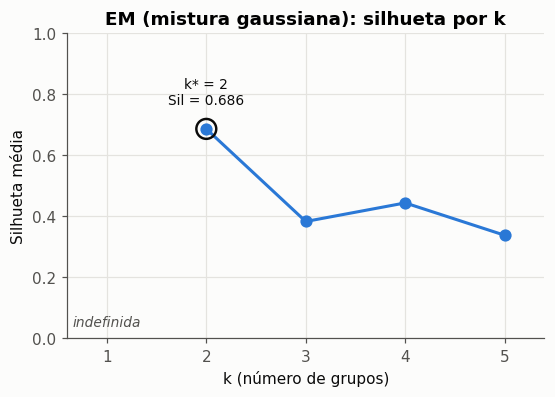

k* = 2 | grupos = 2 | Sil(k*) = 0.6864 | ARI(k*) = 0.5681
Sem avisos: as partições avaliadas convergiram e têm exatamente k grupos.


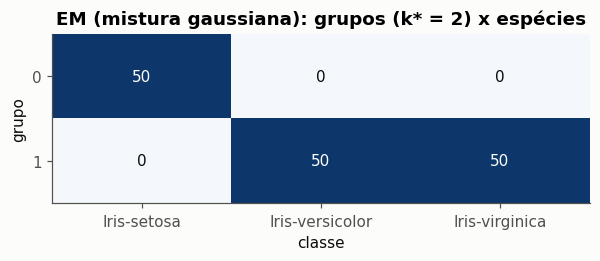

Médias (cm) e pesos dos componentes em k* = 2:


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala,objetos,peso
grupo,,,,,,
0,5.006,3.418,1.464,0.244,50,0.333
1,6.262,2.872,4.906,1.676,100,0.667


Probabilidade a posteriori máxima por grupo em k* = 2:


,count,mean,min,25%,50%
grupo,,,,,
0,50.0,1.0,0.9993,1.0,1.0
1,100.0,1.0,1.0000,1.0,1.0


In [ ]:
apresentar_avaliacao("gmm", "EM (mistura gaussiana)", aval_gmm, exec_gmm)
k_gmm = aval_gmm["k_estrela"]
escolhida_gmm = exec_gmm[exec_gmm["melhor"] & (exec_gmm["k"] == k_gmm)].iloc[0]
modelo_gmm = ajustar_gmm(X, k_gmm, escolhida_gmm["semente"])
print(f"Médias (cm) e pesos dos componentes em k* = {k_gmm}:")
display(tabela_prototipos(exec_gmm, k_gmm).assign(peso=modelo_gmm.weights_.round(3)))

prob_max = pd.Series(escolhida_gmm["pertinencias"].max(axis=1), name="probabilidade máxima")
print(f"Probabilidade a posteriori máxima por grupo em k* = {k_gmm}:")
display(prob_max.groupby(escolhida_gmm["rotulos"]).describe()[["count", "mean", "min", "25%", "50%"]]
        .rename_axis("grupo").round(4))

#### 5.5.4 Verificações

Para cada \(k\), a melhor execução é refeita e passa por cinco verificações:

- **Reprodutibilidade:** mesma log-verossimilhança.
- **Objetivo:** log-verossimilhança recalculada coincide com a do modelo.
- **Etapa E:** probabilidades recalculadas por Bayes coincidem com as do modelo, e a partição corresponde à maior probabilidade.
- **Etapa M:** pesos, médias e covariâncias recalculados coincidem com os parâmetros finais, dentro da tolerância.
- **\(k=1\):** a log-verossimilhança também é conferida por sua fórmula fechada.

Não exigimos aumento da log-verossimilhança a cada iteração, pois a regularização não garante essa monotonicidade. Verificamos, em vez disso, a convergência para um ponto fixo da iteração regularizada.

In [ ]:
def verificar_gmm(execucoes, X):
    """Verificações da melhor execução de cada k (ver texto acima)."""
    reg, linhas = CONFIG["gmm"]["reg_covar"], []
    for _, e in execucoes[execucoes["melhor"]].iterrows():
        modelo = ajustar_gmm(X, e["k"], e["semente"])
        dens = np.column_stack([w * multivariate_normal(mu, c).pdf(X)
                                for w, mu, c in zip(modelo.weights_, modelo.means_, modelo.covariances_)])
        tau = dens / dens.sum(axis=1, keepdims=True)                  # etapa E pela regra de Bayes
        nk = tau.sum(axis=0)                                          # etapa M a partir de tau
        medias = (tau.T @ X) / nk[:, None]
        covs = np.array([((tau[:, g, None] * (X - medias[g])).T @ (X - medias[g])) / nk[g]
                         + reg * np.eye(X.shape[1]) for g in range(e["k"])])
        linhas.append({"k": e["k"],
                       "reajuste reproduz ℓ": bool(np.isclose(modelo.score(X) * len(X), e["objetivo"], rtol=1e-12)),
                       "ℓ recalculada confere": bool(np.isclose(np.log(dens.sum(axis=1)).sum(), e["objetivo"], rtol=1e-9)),
                       "etapa E confere": bool(np.allclose(tau, e["pertinencias"], atol=1e-8)),
                       "crisp = argmax": bool((particao_crisp(tau) == e["rotulos"]).all()),
                       "max |Δπ|": np.abs(nk / len(X) - modelo.weights_).max(),
                       "max |Δμ| (cm)": np.abs(medias - modelo.means_).max(),
                       "max |ΔΣ| (cm²)": np.abs(covs - modelo.covariances_).max()})
    return pd.DataFrame(linhas).set_index("k")


verif_gmm = verificar_gmm(exec_gmm, X)
display(verif_gmm)

S_amostral = np.cov(X, rowvar=False, ddof=0)
Sigma_1 = S_amostral + CONFIG["gmm"]["reg_covar"] * np.eye(X.shape[1])
ell_1 = -len(X) / 2 * (X.shape[1] * np.log(2 * np.pi) + np.linalg.slogdet(Sigma_1)[1]
                       + np.trace(np.linalg.solve(Sigma_1, S_amostral)))
ell_1_exec = exec_gmm[exec_gmm["melhor"] & (exec_gmm["k"] == 1)]["objetivo"].iloc[0]
print(f"k = 1: ℓ = {ell_1_exec:.6f} | forma fechada = {ell_1:.6f}")

assert verif_gmm[["reajuste reproduz ℓ", "ℓ recalculada confere", "etapa E confere", "crisp = argmax"]].all().all()
assert (verif_gmm[["max |Δπ|", "max |Δμ| (cm)", "max |ΔΣ| (cm²)"]] < 1e-3).all().all()
assert np.isclose(ell_1_exec, ell_1, rtol=1e-9)
print("Verificações do EM: OK")

,reajuste reproduz ℓ,ℓ recalculada confere,etapa E confere,crisp = argmax,max |Δπ|,max |Δμ| (cm),max |ΔΣ| (cm²)
k,,,,,,,
1,True,True,True,True,0.000000e+00,0.000000e+00,0.000000e+00
2,True,True,True,True,1.710965e-12,9.252155e-12,3.162770e-11
3,True,True,True,True,1.540768e-04,2.224505e-04,1.865218e-04
4,True,True,True,True,8.847908e-05,5.668704e-04,1.837548e-04
5,True,True,True,True,9.760342e-06,6.395197e-05,2.663938e-05


k = 1: ℓ = -379.592602 | forma fechada = -379.592602
Verificações do EM: OK


#### 5.5.5 Comentários

**Decisões de modelagem.** As correlações dentro dos grupos justificam a covariância completa, pois são fortes e variam entre os lados da lacuna. O diagnóstico também confirmou que a regularização padrão pode gerar componentes degenerados. Com \(h^2/12\), esse problema é evitado, embora os resultados para \(k\geq3\) dependam dessa escolha.

**Busca de parâmetros.** Das 12 configurações testadas, apenas a covariância completa com regularização padrão foi descartada por degeneração. As outras 11 produziram a mesma partição em \(k^*=2\) (100/50; silhueta 0,686). Assim, mantivemos a configuração *a priori*. O BIC também favoreceu a covariância completa.

**Escolha de \(k\).** A maior silhueta ocorreu em \(k^*=2\) (0,686). Para \(k=3,4,5\), os valores foram 0,383, 0,444 e 0,338, indicando maior sobreposição entre os componentes.

**ARI e separação dos grupos.** O ARI foi 0,568, o máximo possível para dois grupos. Um componente reúne as 50 setosas, enquanto o outro reúne as 100 versicolor e virginica. As probabilidades máximas de pertencimento são praticamente 1.

**Diferença em relação ao k-means e FCM.** O EM considera as covariâncias na definição da fronteira entre grupos, que pode ser curva, em vez de considerar apenas a distância aos centros. Isso permite separar corretamente os objetos intermediários e reproduzir a divisão indicada pela lacuna nos dados.

**Estabilidade e convergência.** Em \(k=2\), 7 das 10 execuções encontraram o melhor resultado. A estabilidade diminuiu para \(k=3,4,5\), com 4, 2 e 1 execuções. Todas convergiram, entre 3 e 226 iterações.

**Verificações.** A log-verossimilhança, as probabilidades e os parâmetros foram conferidos independentemente. O caso \(k=1\) também coincidiu com a fórmula fechada.

### 5.6 Agrupamento hierárquico aglomerativo: single linkage (distância city-block)

**Algoritmo.** O algoritmo começa com cada objeto em um grupo e funde, a cada passo, os dois grupos mais próximos. No single linkage, a distância entre dois grupos é a **menor** distância entre um objeto de um e um objeto do outro:

$$D(A, B) = \min_{\mathbf{x} \in A,\, \mathbf{y} \in B} d(\mathbf{x}, \mathbf{y}), \qquad d(\mathbf{x}, \mathbf{y}) = \sum_{p=1}^{4} |x_p - y_p| \quad \text{(city-block, exigida para a nossa dupla)}.$$

O resultado é o dendrograma, com $n-1$ fusões e suas alturas. O algoritmo é determinístico e foi executado **uma única vez**, como manda o enunciado. A partição em $k$ grupos é o estado após as $n-k$ primeiras fusões, isto é, o corte do dendrograma entre a $(n-k)$-ésima e a $(n-k+1)$-ésima altura.

**Hiperparâmetros.** O método (single linkage) e a distância (city-block) são exigidos para a nossa dupla(6), e as partições avaliadas são os cortes em $k = 1, \dots, 5$ do protocolo. Não há, portanto, hiperparâmetro livre a buscar (Seção 4.9). Restam duas escolhas de implementação, que não são hiperparâmetros do método e são tratadas explicitamente abaixo: a precisão do cálculo das distâncias (aritmética exata) e a ordem de desempate entre fusões de mesma altura (Seção 5.6.2).

**Particularidades tratadas:**

- **Empates.** As medidas estão numa grade de 0,1 cm, e as distâncias city-block são múltiplos exatos de 0,1. Calculadas em ponto flutuante, distâncias iguais podem diferir na 16ª casa, e o empate fica escondido. Por isso, as distâncias são calculadas em décimos de centímetro (inteiros), para que empates sejam exatos.
- **Cortes ambíguos.** Quando duas fusões têm a mesma altura justamente na fronteira de um corte, a partição em $k$ grupos depende da ordem de desempate. A célula de cortes detecta esse caso e lista **todas** as partições alternativas, para conferir se $k^*$ depende do desempate.
- **Encadeamento.** O single linkage tende a fundir grupos por cadeias de objetos próximos e a deixar objetos afastados isolados até as últimas fusões. Isso aparece como grupos unitários nos cortes, que recebem silhueta $s(i)=0$.
- **Silhueta (A5):** Euclidiana como critério de $k^*$, com a silhueta city-block, a métrica do próprio algoritmo, como complemento lado a lado.

#### 5.6.1 Execução única e dendrograma

In [ ]:
def distancias_cityblock_exatas(X, precisao):
    """Distâncias city-block (forma condensada) calculadas em unidades inteiras de `precisao`,
    para que distâncias iguais sejam exatamente iguais (empates exatos)."""
    inteiros = np.rint(X / precisao)
    if not np.allclose(inteiros * precisao, X):
        raise ValueError("Há medidas fora da grade de precisão informada")
    return pdist(inteiros, metric="cityblock") * precisao


dist_cb = distancias_cityblock_exatas(X, CONFIG["precisao_cm"])
Z_single = linkage(dist_cb, method="single")                      # execução única
n_obj = len(X)

ultimas = pd.DataFrame({"altura da fusão (cm)": Z_single[-6:, 2],
                        "objetos no grupo resultante": Z_single[-6:, 3].astype(int)},
                       index=pd.Index([f"{n_obj - r} → {n_obj - r - 1}" for r in range(n_obj - 7, n_obj - 1)],
                                      name="nº de grupos"))
print("As 6 últimas fusões:")
display(ultimas)

As 6 últimas fusões:


,altura da fusão (cm),objetos no grupo resultante
nº de grupos,,
7 → 6,1.0,95
6 → 5,1.0,96
5 → 4,1.1,98
4 → 3,1.2,99
3 → 2,1.2,100
2 → 1,2.7,150


In [ ]:
def grafico_dendrograma(Z, k_corte, titulo, nome_arquivo=None):
    """Dendrograma completo, com o corte em k grupos marcado e os grupos coloridos abaixo do corte."""
    n = len(Z) + 1
    altura_corte = (Z[n - k_corte - 1, 2] + Z[n - k_corte, 2]) / 2      # entre as duas fusões vizinhas
    set_link_color_palette(CORES_CLASSES)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=altura_corte,
               above_threshold_color=CORES["texto_sec"])
    ax.axhline(altura_corte, color=CORES["texto"], linestyle="--", linewidth=1.2)
    ax.text(ax.get_xlim()[1], altura_corte, f"  corte em k = {k_corte}", va="bottom", ha="right",
            fontsize=9, color=CORES["texto"])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(f"{n} objetos (folhas)")
    ax.set_ylabel("Altura de fusão: distância city-block (cm)")
    ax.set_title(titulo)
    set_link_color_palette(None)
    if nome_arquivo:
        salvar_figura(fig, nome_arquivo)
    plt.show()

#### 5.6.2 Partições em $k = 1, \dots, 5$ e detecção de cortes ambíguos

Para cada $k$, a célula mostra: os tamanhos dos grupos, o intervalo de alturas em que o corte é feito, se o corte é único e as duas silhuetas.

Quando o corte é ambíguo, as alternativas são obtidas assim:

1. parte-se da partição em $k+1$ grupos, que precisa ser única;
2. funde-se cada par de grupos cuja distância single-link seja exatamente a altura empatada;
3. cada fusão possível é uma partição alternativa.

In [ ]:
def corte_ambiguo(Z, k):
    """True se a partição em k grupos depende da ordem de desempate: a última fusão incluída
    no corte e a primeira excluída têm a mesma altura."""
    n = len(Z) + 1
    return 1 < k < n and Z[n - k - 1, 2] == Z[n - k, 2]


def alternativas_de_corte(dist, Z, k):
    """Todas as partições em k grupos compatíveis com o dendrograma quando o corte em k é ambíguo."""
    n = len(Z) + 1
    if corte_ambiguo(Z, k + 1):
        raise NotImplementedError("Empate que se estende a mais de um nível: enumerar manualmente")
    altura = Z[n - k - 1, 2]
    base = cut_tree(Z, n_clusters=k + 1).ravel()
    D = squareform(dist)
    alternativas = []
    for a, b in combinations(np.unique(base), 2):
        if D[np.ix_(base == a, base == b)].min() == altura:          # o par pode ser fundido nessa altura
            alternativas.append(pd.factorize(np.where(base == b, a, base))[0])
    return alternativas


particoes_sl = {k: cut_tree(Z_single, n_clusters=k).ravel() for k in CONFIG["valores_k"]}

linhas = []
for k, rot in particoes_sl.items():
    linhas.append({"k": k, "tamanhos dos grupos": sorted(np.bincount(rot).tolist(), reverse=True),
                   "corte entre alturas (cm)": (f"[{Z_single[n_obj - k - 1, 2]:.1f}, {Z_single[n_obj - k, 2]:.1f})"
                                                if k > 1 else f"≥ {Z_single[-1, 2]:.1f}"),
                   "corte único": not corte_ambiguo(Z_single, k),
                   "Sil Euclidiana (critério)": silhueta(X, rot),
                   "Sil city-block (complemento)": silhueta(X, rot, "cityblock")})
cortes_sl = pd.DataFrame(linhas).set_index("k")
display(cortes_sl.style.format({"Sil Euclidiana (critério)": "{:.4f}", "Sil city-block (complemento)": "{:.4f}"},
                               na_rep="indefinida"))

for k in cortes_sl.index[~cortes_sl["corte único"]]:
    alternativas = alternativas_de_corte(dist_cb, Z_single, k)
    print(f"\nk = {k}: corte ambíguo (fusões empatadas em {Z_single[n_obj - k - 1, 2]:.1f} cm). "
          f"{len(alternativas)} partições possíveis:")
    display(pd.DataFrame([{"tamanhos dos grupos": sorted(np.bincount(a).tolist(), reverse=True),
                           "é a do scipy": bool(adjusted_rand_score(a, particoes_sl[k]) == 1.0),
                           "Sil Euclidiana": silhueta(X, a), "Sil city-block": silhueta(X, a, "cityblock")}
                          for a in alternativas]).round(4))

,tamanhos dos grupos,corte entre alturas (cm),corte único,Sil Euclidiana (critério),Sil city-block (complemento)
k,,,,,
1,[150],≥ 2.7,True,indefinida,indefinida
2,"[100, 50]","[1.2, 2.7)",True,0.6864,0.6785
3,"[99, 50, 1]","[1.2, 1.2)",False,0.3917,0.4137
4,"[98, 50, 1, 1]","[1.1, 1.2)",True,0.1946,0.1828
5,"[96, 50, 2, 1, 1]","[1.0, 1.1)",True,0.2193,0.2065



k = 3: corte ambíguo (fusões empatadas em 1.2 cm). 2 partições possíveis:


,tamanhos dos grupos,é a do scipy,Sil Euclidiana,Sil city-block
0,"[99, 50, 1]",True,0.3917,0.4137
1,"[99, 50, 1]",False,0.3401,0.3158


#### 5.6.3 Silhueta, $k^*$, índice de Rand corrigido e dendrograma

,n_grupos,silhueta
k,,
1,1,indefinida
2,2,0.6864
3,3,0.3917
4,4,0.1946
5,5,0.2193


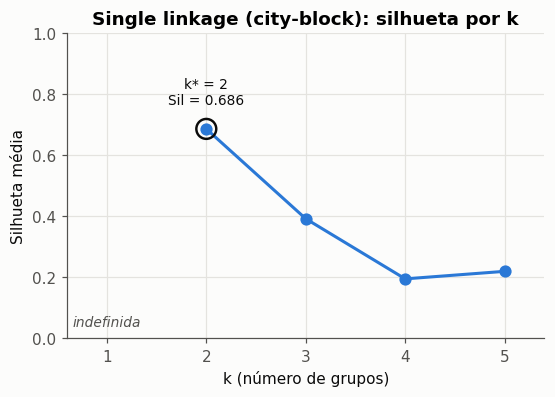

k* = 2 | grupos = 2 | Sil(k*) = 0.6864 | ARI(k*) = 0.5681
Sem avisos: as partições avaliadas convergiram e têm exatamente k grupos.


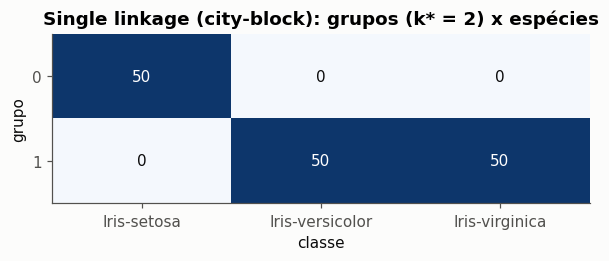

Complemento (A5): com a silhueta city-block, k* seria 2 (igual do critério Euclidiano).


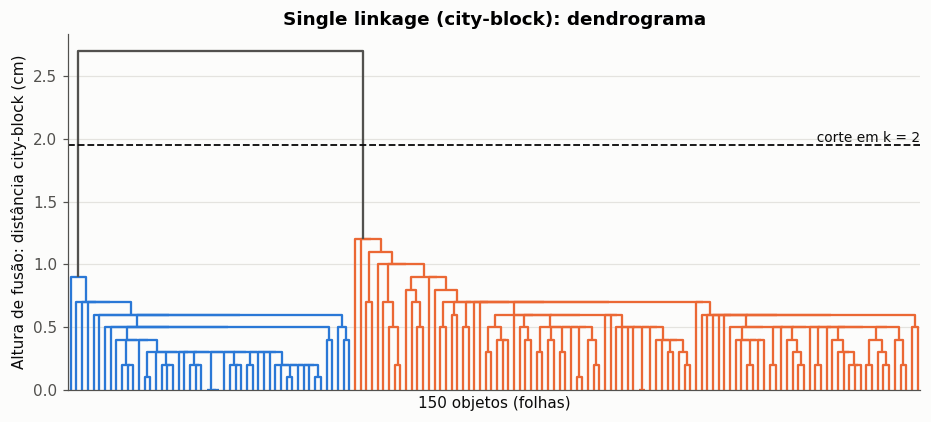

In [ ]:
aval_sl = avaliar_particoes(particoes_sl, X)
apresentar_avaliacao("single_linkage", "Single linkage (city-block)", aval_sl)

k_cb = escolher_k_estrela(curva_silhueta(particoes_sl, X, "cityblock"))
print(f"Complemento (A5): com a silhueta city-block, k* seria {k_cb} "
      f"({'igual' if k_cb == aval_sl['k_estrela'] else 'DIFERENTE'} do critério Euclidiano).")
grafico_dendrograma(Z_single, aval_sl["k_estrela"], "Single linkage (city-block): dendrograma",
                    "single_linkage_dendrograma")

#### 5.6.4 Verificações

- **Equivalência com a árvore geradora mínima** (Gower & Ross, 1969): as $n-1$ alturas de fusão do single linkage são exatamente os pesos das arestas da árvore geradora mínima do grafo completo de distâncias city-block. A conferência é feita com `scipy.sparse.csgraph`, de forma independente do `linkage`.
- **Cortes = componentes conexas:** para cada corte único em $k$ grupos, a partição é igual às componentes conexas do grafo que liga os pares com distância $\le$ a altura da última fusão incluída.
- **Número de grupos:** cada corte tem exatamente $k$ grupos.

In [ ]:
D_cb = squareform(dist_cb)
# minimum_spanning_tree ignora arestas de peso 0 (objetos duplicados): soma-se 1 a todas as arestas,
# o que não muda a árvore mínima (toda árvore geradora tem n - 1 arestas), e subtrai-se depois
arvore = minimum_spanning_tree(D_cb + 1 - np.eye(n_obj))
alturas_iguais_arvore = np.allclose(np.sort(arvore.data - 1), np.sort(Z_single[:, 2]))

linhas = []
for k, rot in particoes_sl.items():
    linha = {"k": k, "grupos no corte": len(np.unique(rot))}
    if not corte_ambiguo(Z_single, k):
        altura = Z_single[n_obj - k - 1, 2] if k < n_obj else 0.0
        n_comp, componentes = connected_components(D_cb <= altura, directed=False)
        linha["componentes conexas"] = n_comp
        linha["corte = componentes"] = bool(adjusted_rand_score(componentes, rot) == 1.0)
    linhas.append(linha)
verif_sl = pd.DataFrame(linhas).set_index("k")
display(verif_sl)
print(f"Alturas de fusão = pesos da árvore geradora mínima: {alturas_iguais_arvore}")

assert alturas_iguais_arvore
assert (verif_sl["grupos no corte"] == verif_sl.index).all()
assert verif_sl["corte = componentes"].dropna().astype(bool).all()
print("Verificações do single linkage: OK")

,grupos no corte,componentes conexas,corte = componentes
k,,,
1,1,1.0,True
2,2,2.0,True
3,3,NaN,NaN
4,4,4.0,True
5,5,5.0,True


Alturas de fusão = pesos da árvore geradora mínima: True
Verificações do single linkage: OK


#### 5.6.5 Comentários

**Dendrograma.** O maior salto ocorre de 1,2 para 2,7 cm, quando um grupo de 50 objetos se une aos outros 100. Isso indica dois blocos bem separados.

**Escolha de \(k\).** A melhor silhueta ocorre em \(k^*=2\) (0,686), resultado também confirmado pela métrica city-block (0,678). Para valores maiores de \(k\), ocorre o encadeamento característico do single linkage: os cortes apenas isolam objetos das extremidades, reduzindo a silhueta.

**Empate em \(k=3\).** Duas fusões têm a mesma altura, gerando duas partições possíveis, com silhuetas 0,392 e 0,340. Ambas são inferiores à de \(k=2\), portanto a escolha de \(k^*\) não depende do desempate.

**ARI.** O ARI é 0,568, o máximo possível para dois grupos. A partição separa exatamente as 50 setosas das outras 100 flores, reproduzindo a divisão observada pela lacuna dos dados.

**Verificações.** As alturas de fusão coincidem com os pesos da árvore geradora mínima, e os cortes correspondem às componentes conexas do grafo de vizinhança.

### 5.7 DBSCAN

**Algoritmo.** O DBSCAN (Ester et al., 1996) forma grupos a partir de vizinhanças definidas por \(\varepsilon\) e `min_samples`:
- **Centrais:** possuem pelo menos `min_samples` objetos na vizinhança.
- **Borda:** não são centrais, mas estão próximas de algum objeto central.
- **Ruído:** não pertencem a nenhum grupo (rótulo \(-1\)).

O número de grupos é definido pelo algoritmo, portanto não há curva Sil × k. O método é determinístico, exceto em possíveis empates na atribuição de objetos de borda, que são verificados.

**Configuração oficial.** Os resultados apresentados vêm de uma única execução, com os parâmetros escolhidos na busca da Seção 5.7.2.

**Hiperparâmetros, escolhidos sem rótulos:**

| Parâmetro | Escolha inicial | Valor final |
|---|---|---|
| Distância | Euclidiana, coerente com o espaço bruto (A4) e a avaliação (A5). | Não buscada |
| `min_samples` | \(2d=8\), conforme Sander et al. (1998) e Schubert et al. (2017). | Definido pela busca |
| \(\varepsilon\) | Joelho da curva de k-distâncias, identificado pelo método Kneedle (Satopää et al., 2011). | Definido pela busca |

**Tratamento do ruído (A11).**
- **Silhueta:** calculada nos objetos agrupados. Como complemento, o ruído recebe silhueta zero, gerando uma média sobre os 150 objetos; esse é o escore usado na busca.
- **ARI:** calculado sem os objetos de ruído. Também são apresentados resultados considerando o ruído como grupo único ou cada objeto como grupo separado.
- **Contingência:** o ruído aparece em uma linha própria.
- **Comparação com os outros algoritmos:** considera apenas os objetos agrupados pelo DBSCAN.

#### 5.7.1 Configuração a priori: $\varepsilon$ pela curva de $k$-distâncias

min_samples = 8 | joelho na posição 116 de 150 | ε = 0.5477 cm


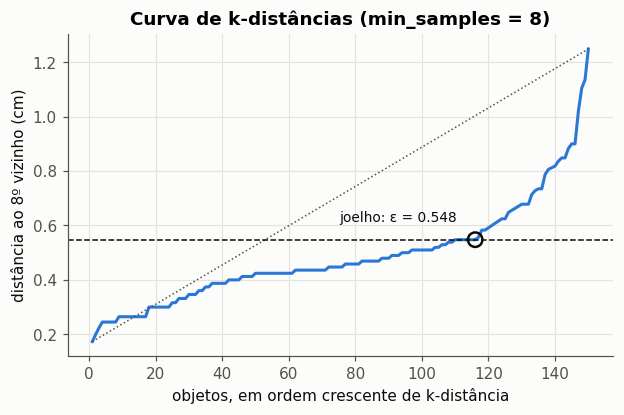

In [ ]:
D_euclid = squareform(pdist(X, metric=CONFIG["dbscan"]["metrica"]))


def curva_k_distancias(D, min_samples):
    """Distância de cada objeto ao seu min_samples-ésimo vizinho mais próximo (contando ele mesmo), em ordem crescente."""
    return np.sort(np.sort(D, axis=1)[:, min_samples - 1])


def indice_joelho(curva):
    """Joelho de uma curva crescente: ponto mais distante abaixo da corda entre os extremos,
    com os dois eixos normalizados para [0, 1] (Kneedle, Satopää et al., 2011)."""
    x = np.linspace(0, 1, len(curva))
    y = (curva - curva[0]) / (curva[-1] - curva[0])
    return int(np.argmax(x - y))


MS_A_PRIORI = CONFIG["dbscan"]["min_samples"]                     # 2 x dimensão (configuração a priori)
k_dist = curva_k_distancias(D_euclid, MS_A_PRIORI)
i_joelho = indice_joelho(k_dist)
EPS_JOELHO = float(k_dist[i_joelho])
print(f"min_samples = {MS_A_PRIORI} | joelho na posição {i_joelho + 1} de {len(k_dist)} | ε = {EPS_JOELHO:.4f} cm")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(np.arange(1, len(k_dist) + 1), k_dist, color=CORES["azul"], linewidth=2)
ax.plot([1, len(k_dist)], [k_dist[0], k_dist[-1]], color=CORES["texto_sec"], linewidth=1, linestyle=":")
ax.scatter([i_joelho + 1], [EPS_JOELHO], s=90, facecolor="none", edgecolor=CORES["texto"], linewidth=1.6, zorder=4)
ax.axhline(EPS_JOELHO, color=CORES["texto"], linestyle="--", linewidth=1)
ax.annotate(f"joelho: ε = {EPS_JOELHO:.3f}", (i_joelho + 1, EPS_JOELHO), xytext=(-12, 12),
            textcoords="offset points", ha="right", fontsize=9, color=CORES["texto"])
ax.set_xlabel("objetos, em ordem crescente de k-distância")
ax.set_ylabel(f"distância ao {MS_A_PRIORI}º vizinho (cm)")
ax.set_title(f"Curva de k-distâncias (min_samples = {MS_A_PRIORI})")
salvar_figura(fig, "dbscan_k_distancias")
plt.show()

#### 5.7.2 Busca de ε e `min_samples`

A busca testa:
- `min_samples` de 4 a 16;
- ε de 0,30 a 1,20 cm, em intervalos de 0,05 cm;
- o ε indicado pelo joelho da curva de k-distâncias para cada valor de `min_samples`.

Cada configuração é executada uma vez, pois o DBSCAN é determinístico. A distância Euclidiana é mantida.

**Escore e escolha.** Usamos a silhueta média dos 150 objetos, atribuindo zero ao ruído. Assim, evitamos favorecer configurações que descartam objetos difíceis como ruído. Configurações com menos de dois grupos são descartadas.

A escolha segue a regra da Seção 4.9. Em caso de empate, priorizamos `min_samples` = 8 e depois o ε mais próximo do joelho, mantendo a configuração *a priori* sempre que possível.

As tabelas e a figura mostram os escores, o número de grupos e a quantidade de ruído para cada configuração.

In [ ]:
def avaliar_dbscan(D, eps, min_samples, X):
    """Uma configuração do DBSCAN, sem rótulos: grupos, ruído, silhueta sem o ruído e silhueta com
    ruído = 0 (o escore da busca), com o erro-padrão deste."""
    rotulos = DBSCAN(eps=eps, min_samples=min_samples, metric="precomputed").fit_predict(D)
    ruido = rotulos == -1
    n_grupos = len(set(rotulos[~ruido]))
    resumo = {"grupos": n_grupos, "ruído": int(ruido.sum()),
              "tamanhos dos grupos": sorted(np.bincount(rotulos[~ruido]).tolist(), reverse=True) if n_grupos else [],
              "admissível": 2 <= n_grupos <= (~ruido).sum() - 1,
              "Sil sem ruído": np.nan, "Sil com ruído = 0": np.nan, "EP": np.nan}
    if resumo["admissível"]:
        s = silhueta_por_objeto(X, rotulos, ruido)
        resumo.update({"Sil sem ruído": float(s[~ruido].mean()), "Sil com ruído = 0": float(s.mean()),
                       "EP": erro_padrao(s)})
    return resumo, rotulos


inicio, fim, passo = CONFIG["busca"]["dbscan_eps"]
GRADE_EPS = np.round(np.arange(inicio, fim + passo / 2, passo), 2)
EPS_JOELHO_POR_MS, linhas, particoes = {}, [], {}
for ms in CONFIG["busca"]["dbscan_min_samples"]:
    curva = curva_k_distancias(D_euclid, ms)
    EPS_JOELHO_POR_MS[ms] = float(curva[indice_joelho(curva)])
    for eps in sorted(set(GRADE_EPS.tolist()) | {EPS_JOELHO_POR_MS[ms]}):     # grade + joelho deste min_samples
        resumo, rotulos = avaliar_dbscan(D_euclid, eps, ms, X)
        particoes[len(linhas)] = rotulos
        linhas.append({"min_samples": ms, "eps": eps, "joelho": eps == EPS_JOELHO_POR_MS[ms], **resumo})
registrar_busca("dbscan", "DBSCAN", pd.DataFrame(linhas), ["min_samples", "eps"], particoes)

# Regra da Seção 4.9 com o escore do DBSCAN; proximidade: mesmo min_samples a priori, depois o ε mais próximo do joelho
escolhida_dbscan = escolher_configuracao("dbscan", {"min_samples": MS_A_PRIORI, "eps": EPS_JOELHO},
                                         escore="Sil com ruído = 0")
tabela_dbscan = BUSCAS["dbscan"]["tabela"]
regular = tabela_dbscan["eps"].apply(lambda e: np.isclose(GRADE_EPS, e).any())


def grade_dbscan(coluna):
    """Tabela ε x min_samples de uma coluna da busca (só a grade regular de ε)."""
    return tabela_dbscan[regular].pivot(index="eps", columns="min_samples", values=coluna)


destaque = np.where(grade_dbscan("escolhida").to_numpy(bool), "background-color: #cde2fb; font-weight: bold",
                    np.where(grade_dbscan("na tolerância (1 EP)").to_numpy(bool), "background-color: #eef4fb", ""))
print("Escore: silhueta com ruído = 0 (azul: na faixa de tolerância de 1 EP; negrito: escolhida; —: menos de 2 grupos)")
display(grade_dbscan("Sil com ruído = 0").style.apply(lambda _: destaque, axis=None)
        .format("{:.3f}", na_rep="—").format_index("{:.2f}", axis=0))
print("Grupos | objetos de ruído:")
display(tabela_dbscan[regular].assign(**{"grupos | ruído": lambda t: t["grupos"].astype(str) + " | " + t["ruído"].astype(str)})
        .pivot(index="eps", columns="min_samples", values="grupos | ruído")
        .style.format_index("{:.2f}", axis=0))
print("Joelho da curva de k-distâncias de cada min_samples:")
display(estilo_busca(tabela_dbscan[tabela_dbscan["joelho"]][
    ["min_samples", "eps", "grupos", "ruído", "tamanhos dos grupos", "Sil sem ruído", "Sil com ruído = 0",
     "EP", "na tolerância (1 EP)"]], "dbscan"))
resumir_escolha("dbscan")
MIN_SAMPLES, EPS_DBSCAN = int(escolhida_dbscan["min_samples"]), float(escolhida_dbscan["eps"])
fixar_configuracao("dbscan", "dbscan")

Escore: silhueta com ruído = 0 (azul: na faixa de tolerância de 1 EP; negrito: escolhida; —: menos de 2 grupos)


min_samples,4,6,8,10,12,16
eps,,,,,,
0.30,0.312,0.246,—,—,—,—
0.35,0.359,0.341,0.296,—,—,—
0.40,0.401,0.395,0.392,0.335,—,—
0.45,0.457,0.608,0.580,0.399,0.330,—
0.50,0.464,0.634,0.617,0.599,0.448,0.337
0.55,0.469,0.664,0.661,0.653,0.634,0.593
0.60,0.473,0.675,0.670,0.670,0.653,0.634
0.65,0.680,0.685,0.676,0.676,0.676,0.660
0.70,0.680,0.684,0.682,0.678,0.678,0.665


Grupos | objetos de ruído:


min_samples,4,6,8,10,12,16
eps,,,,,,
0.30,6 | 81,2 | 106,1 | 118,1 | 120,0 | 150,0 | 150
0.35,7 | 49,3 | 80,2 | 96,1 | 111,1 | 111,1 | 119
0.40,4 | 25,4 | 32,4 | 66,3 | 83,1 | 106,1 | 109
0.45,3 | 17,2 | 28,2 | 34,4 | 65,2 | 89,1 | 106
0.50,3 | 13,2 | 22,2 | 26,2 | 30,3 | 35,2 | 88
0.55,3 | 6,2 | 14,2 | 15,2 | 17,2 | 22,2 | 31
0.60,3 | 5,2 | 11,2 | 13,2 | 13,2 | 18,2 | 22
0.65,2 | 3,2 | 6,2 | 10,2 | 10,2 | 10,2 | 16
0.70,2 | 3,2 | 5,2 | 6,2 | 8,2 | 8,2 | 12


Joelho da curva de k-distâncias de cada min_samples:


min_samples,eps,grupos,ruído,tamanhos dos grupos,Sil sem ruído,Sil com ruído = 0,EP,na tolerância (1 EP)
4,0.4359,3,17,"[81, 48, 4]",0.5152,0.4568,0.0270,não
6,0.5196,2,17,"[84, 49]",0.7368,0.6533,0.0209,não
8,0.5477,2,15,"[86, 49]",0.7347,0.6612,0.0200,não
10,0.6557,2,10,"[90, 50]",0.7239,0.6756,0.0177,sim
12,0.7071,2,8,"[92, 50]",0.7161,0.6779,0.0169,sim
16,0.8124,2,5,"[95, 50]",0.7005,0.6771,0.0163,sim


Configurações: 120 | admissíveis: 110 | na faixa de tolerância (1 EP): 73
Maior escore (Sil com ruído = 0): 0.6864, EP = 0.0138, em min_samples = 4, eps = 0.9 (mesmo valor em 37 configurações) -> limiar de tolerância = 0.6726
A priori: min_samples = 8, eps = 0.5477 | escore = 0.6612 | admissível: sim | na faixa de tolerância: não
ESCOLHIDA: min_samples = 8, eps = 0.65 | escore = 0.6756 | a configuração a priori foi SUBSTITUÍDA
Obs.: a escolhida não é a de maior escore numérico (0.6864); foi escolhida pelo critério definido antes da busca (faixa de tolerância de 1 EP + preferência pela configuração a priori).
CONFIG['dbscan']['min_samples'] = 8   (a priori, mantido)
CONFIG['dbscan']['eps'] = 0.65   (a priori: 0.5477225575051669)


Na figura, cada linha é um valor de `min_samples`. Os círculos vazados marcam o joelho de cada um; o círculo preto, a configuração escolhida; e a linha tracejada do painel central, o limiar da faixa de tolerância (maior escore − 1 EP).

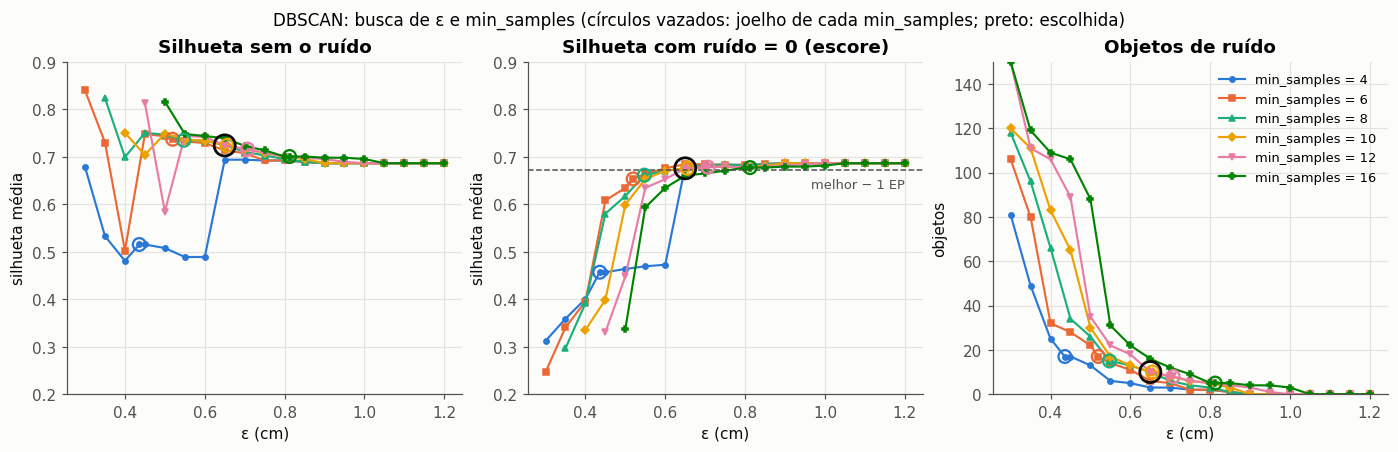

In [ ]:
# comportamento do DBSCAN na grade: silhueta sem o ruído, escore (ruído = 0) e quantidade de ruído
paineis = [("Sil sem ruído", "Silhueta sem o ruído", "silhueta média"),
           ("Sil com ruído = 0", "Silhueta com ruído = 0 (escore)", "silhueta média"),
           ("ruído", "Objetos de ruído", "objetos")]
fig, eixos = plt.subplots(1, 3, figsize=(12.6, 4.0), layout="constrained")
for (ms, grupo), cor, marcador in zip(tabela_dbscan.groupby("min_samples"), CORES_SERIES, MARCADORES_SERIES):
    grupo = grupo.sort_values("eps")
    for ax, (coluna, _, _) in zip(eixos, paineis):
        ax.plot(grupo["eps"], grupo[coluna], color=cor, linewidth=1.4, marker=marcador, markersize=3.5,
                label=f"min_samples = {ms}")
        joelho = grupo[grupo["joelho"]]
        ax.scatter(joelho["eps"], joelho[coluna], s=70, facecolor="none", edgecolor=cor, linewidth=1.5, zorder=4)
for ax, (coluna, titulo, rotulo_y) in zip(eixos, paineis):
    ax.scatter([EPS_DBSCAN], [escolhida_dbscan[coluna]], s=190, facecolor="none", edgecolor=CORES["texto"],
               linewidth=1.8, zorder=5)
    ax.set_title(titulo)
    ax.set_xlabel("ε (cm)")
    ax.set_ylabel(rotulo_y)
for ax in eixos[:2]:
    ax.set_ylim(0.2, 0.9)
eixos[1].axhline(BUSCAS["dbscan"]["limiar"], color=CORES["texto_sec"], linestyle="--", linewidth=1)
eixos[1].annotate("melhor − 1 EP", (GRADE_EPS[-1], BUSCAS["dbscan"]["limiar"]), xytext=(0, -12),
                  textcoords="offset points", ha="right", fontsize=8.5, color=CORES["texto_sec"])
eixos[2].set_ylim(0, len(X))
eixos[2].legend(loc="upper right", fontsize=8.5)
fig.suptitle("DBSCAN: busca de ε e min_samples (círculos vazados: joelho de cada min_samples; preto: escolhida)",
             fontsize=11)
salvar_figura(fig, "dbscan_busca")
plt.show()

**ARI descritivo (depois da escolha).** A tabela abaixo mostra o ARI, nas duas convenções, de quatro configurações de referência da grade: a *a priori*, a escolhida, a de maior escore e a de maior silhueta sem o ruído. Em seguida, como exemplo do regime fragmentado ($\varepsilon$ pequeno, muito ruído), a composição por espécie de uma configuração. Nenhum desses valores participou da escolha.

In [ ]:
# ARI de configurações de referência da grade, calculado depois da escolha (não participa dela)
indices_ref = {"a priori (joelho, min_samples = 8)": indice_a_priori("dbscan"),
               "escolhida": BUSCAS["dbscan"]["escolhida"],
               "maior silhueta com ruído = 0": BUSCAS["dbscan"]["melhor"],
               "maior silhueta sem o ruído": tabela_dbscan.loc[tabela_dbscan["admissível"], "Sil sem ruído"].idxmax()}
linhas = []
for nome, i in indices_ref.items():
    c, rot = tabela_dbscan.loc[i], BUSCAS["dbscan"]["particoes"][i]
    agrup = rot != -1
    linhas.append({"configuração": nome, "min_samples": c["min_samples"], "ε (cm)": c["eps"],
                   "grupos": c["grupos"], "ruído": c["ruído"], "Sil sem ruído": c["Sil sem ruído"],
                   "Sil com ruído = 0": c["Sil com ruído = 0"],
                   "ARI sem o ruído": avaliar_com_classes(rot[agrup], y_verdadeiro[agrup])[0],
                   "ARI, ruído = −1": avaliar_com_classes(rot)[0]})
display(pd.DataFrame(linhas).set_index("configuração").style.format(precision=4))

# Regime fragmentado (ε pequeno, muito ruído): composição por espécie de uma configuração de referência
i_frag = next(i for i, c in tabela_dbscan.iterrows() if c["min_samples"] == 4 and np.isclose(c["eps"], 0.40))
c_frag = tabela_dbscan.loc[i_frag]
print(f"Regime fragmentado (min_samples = 4, ε = 0,40 cm): {c_frag['grupos']} grupos, {c_frag['ruído']} objetos de ruído, "
      f"silhueta com ruído = 0 de {c_frag['Sil com ruído = 0']:.3f}. Composição por espécie (só descrição):")
display(avaliar_com_classes(BUSCAS["dbscan"]["particoes"][i_frag])[1])

,min_samples,ε (cm),grupos,ruído,Sil sem ruído,Sil com ruído = 0,ARI sem o ruído,"ARI, ruído = −1"
configuração,,,,,,,,
"a priori (joelho, min_samples = 8)",8,0.5477,2,15,0.7347,0.6612,0.6013,0.5252
escolhida,8,0.6500,2,10,0.7239,0.6756,0.5949,0.5468
maior silhueta com ruído = 0,4,0.9000,2,0,0.6864,0.6864,0.5681,0.5681
maior silhueta sem o ruído,6,0.3000,2,106,0.8395,0.2463,1.0000,0.2879


Regime fragmentado (min_samples = 4, ε = 0,40 cm): 4 grupos, 25 objetos de ruído, silhueta com ruído = 0 de 0.401. Composição por espécie (só descrição):


classe,Iris-setosa,Iris-versicolor,Iris-virginica
grupo,,,
0,47,0,0
1,0,38,0
2,0,3,33
3,0,4,0
ruído,3,5,17


#### 5.7.3 Configuração oficial: execução, silhueta e índice de Rand corrigido

Uma única execução, com a configuração escolhida na Seção 5.7.2. O ARI oficial exclui os objetos de ruído (A11).

,DBSCAN
configuração,oficial (única execução; escolhida na Seção 5.7.2)
ε (cm),0.6500
min_samples,8
grupos encontrados,2
objetos de ruído,10
fração de ruído,0.0667
Silhueta sem o ruído (critério),0.7239
Silhueta com ruído = 0 (complemento; escore da busca),0.6756
ARI sem o ruído (critério),0.5949
objetos no ARI (critério),140


Tamanhos dos grupos: [50, 90] | espécies dos objetos agrupados: [50, 47, 43]


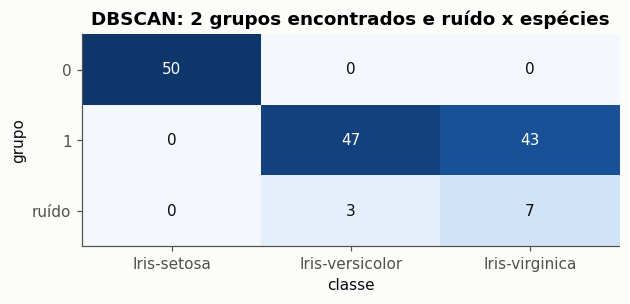

In [ ]:
def ruido_como_unitarios(rotulos):
    """Cada objeto de ruído (-1) vira um grupo unitário próprio, para o ARI."""
    novos = rotulos.copy()
    indices = np.flatnonzero(novos == -1)
    novos[indices] = novos.max() + 1 + np.arange(len(indices))
    return novos


# Configuração oficial (escolhida na Seção 5.7.2): a única execução do DBSCAN usada nos resultados
modelo_dbscan = DBSCAN(eps=EPS_DBSCAN, min_samples=MIN_SAMPLES, metric="precomputed").fit(D_euclid)
rot_dbscan = modelo_dbscan.labels_
assert np.array_equal(rot_dbscan, BUSCAS["dbscan"]["particoes"][BUSCAS["dbscan"]["escolhida"]])
ruido = rot_dbscan == -1
n_grupos_dbscan = len(set(rot_dbscan) - {-1})

sil_sem_ruido = silhueta(X[~ruido], rot_dbscan[~ruido])
sil_ruido_zero = sil_sem_ruido * (~ruido).sum() / len(X)            # média com s(i) = 0 para o ruído
ari_sem_ruido = avaliar_com_classes(rot_dbscan[~ruido], y_verdadeiro[~ruido])[0]     # critério (A11)
ari_rotulo_unico, contingencia_dbscan = avaliar_com_classes(rot_dbscan)              # complemento
ari_unitarios = avaliar_com_classes(ruido_como_unitarios(rot_dbscan))[0]             # complemento
TETO_ARI_2_AGRUPADOS = teto_ari_dois_grupos(np.bincount(y_verdadeiro[~ruido], minlength=len(CLASSES)))[0]

resultado_dbscan = pd.Series({
    "configuração": "oficial (única execução; escolhida na Seção 5.7.2)", "ε (cm)": EPS_DBSCAN,
    "min_samples": MIN_SAMPLES, "grupos encontrados": n_grupos_dbscan, "objetos de ruído": int(ruido.sum()),
    "fração de ruído": ruido.mean(),
    "Silhueta sem o ruído (critério)": sil_sem_ruido,
    "Silhueta com ruído = 0 (complemento; escore da busca)": sil_ruido_zero,
    "ARI sem o ruído (critério)": ari_sem_ruido,
    "objetos no ARI (critério)": int((~ruido).sum()),
    "teto do ARI para 2 grupos nesses objetos (referência)": TETO_ARI_2_AGRUPADOS,
    "ARI, ruído com rótulo −1 (complemento)": ari_rotulo_unico,
    "ARI, ruído como unitários (complemento)": ari_unitarios}, name="DBSCAN", dtype=object)
display(resultado_dbscan.to_frame().style.format(lambda v: f"{v:.4f}" if isinstance(v, float) else v))
print("Tamanhos dos grupos:", np.bincount(rot_dbscan[~ruido]).tolist(),
      "| espécies dos objetos agrupados:", np.bincount(y_verdadeiro[~ruido], minlength=len(CLASSES)).tolist())

grafico_contingencia(contingencia_dbscan, f"DBSCAN: {n_grupos_dbscan} grupos encontrados e ruído x espécies",
                     "dbscan_contingencia")
RESUMO_Q1["DBSCAN"] = {"k*": n_grupos_dbscan, "grupos em k*": n_grupos_dbscan, "Sil(k*)": float(sil_sem_ruido),
                       "ARI(k*)": float(ari_sem_ruido), "avisos": 0, "ruído": int(ruido.sum()),
                       "ARI com ruído = −1": float(ari_rotulo_unico)}

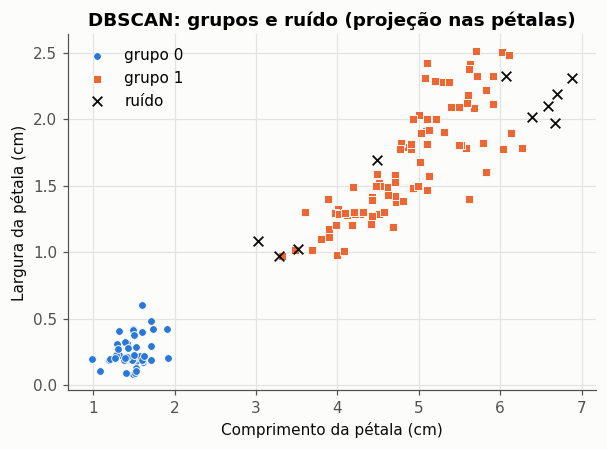

In [ ]:
# Onde estão os grupos e o ruído: comprimento x largura da pétala (sem informação de espécie)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
rng_grafico = np.random.default_rng(CONFIG["semente_global"])
tremor = rng_grafico.uniform(-0.03, 0.03, size=(len(X), 2))          # separa visualmente pontos coincidentes
for g in range(n_grupos_dbscan):
    m = rot_dbscan == g
    ax.scatter(X[m, 2] + tremor[m, 0], X[m, 3] + tremor[m, 1], s=26, color=CORES_CLASSES[g % 3],
               marker=MARCADORES[g % 3], edgecolor=CORES["fundo"], linewidth=0.6, label=f"grupo {g}")
ax.scatter(X[ruido, 2] + tremor[ruido, 0], X[ruido, 3] + tremor[ruido, 1], s=40, color=CORES["texto"],
           marker="x", linewidth=1.2, label="ruído")
ax.set_xlabel("Comprimento da pétala (cm)")
ax.set_ylabel("Largura da pétala (cm)")
ax.set_title("DBSCAN: grupos e ruído (projeção nas pétalas)")
ax.legend(loc="upper left")
salvar_figura(fig, "dbscan_petalas")
plt.show()

#### 5.7.4 Verificações

A célula reconstrói a definição do DBSCAN a partir da matriz de distâncias, sem usar o scikit-learn, e confere:

- os **objetos centrais** são exatamente os que têm pelo menos `min_samples` objetos a distância $\le \varepsilon$;
- os **grupos** correspondem às componentes conexas do grafo de vizinhança restrito aos objetos centrais;
- todo objeto de **borda** recebeu o grupo de um vizinho central;
- **ruído** são exatamente os objetos não centrais sem vizinho central;
- **bordas ambíguas**, vizinhas de centrais de grupos diferentes, são contadas. Se não houver nenhuma, o resultado não depende da ordem dos objetos.

In [ ]:
vizinhos = D_euclid <= EPS_DBSCAN                                  # vizinhança fechada, inclui o próprio objeto
centrais = vizinhos.sum(axis=1) >= MIN_SAMPLES
tem_vizinho_central = vizinhos[:, centrais].any(axis=1)
borda = ~centrais & tem_vizinho_central

n_comp, comp = connected_components(vizinhos[np.ix_(centrais, centrais)], directed=False)
grupos_vizinhos = [set(rot_dbscan[centrais & vizinhos[i]]) for i in np.flatnonzero(borda)]

verif_dbscan = pd.Series({
    "objetos centrais": int(centrais.sum()),
    "objetos de borda": int(borda.sum()),
    "objetos de ruído": int(ruido.sum()),
    "centrais conferem": set(np.flatnonzero(centrais)) == set(modelo_dbscan.core_sample_indices_),
    "grupos = componentes dos centrais": n_comp == n_grupos_dbscan
                                         and adjusted_rand_score(comp, rot_dbscan[centrais]) == 1.0,
    "bordas no grupo de um vizinho central": all(r in g for r, g in zip(rot_dbscan[borda], grupos_vizinhos)),
    "ruído = não centrais sem vizinho central": bool((ruido == (~centrais & ~tem_vizinho_central)).all()),
    "bordas ambíguas": sum(len(g) > 1 for g in grupos_vizinhos)}, name="verificação")
display(verif_dbscan.to_frame())

assert all(verif_dbscan[["centrais conferem", "grupos = componentes dos centrais",
                         "bordas no grupo de um vizinho central", "ruído = não centrais sem vizinho central"]])
print("Verificações do DBSCAN: OK")

,verificação
objetos centrais,126
objetos de borda,14
objetos de ruído,10
centrais conferem,True
grupos = componentes dos centrais,True
bordas no grupo de um vizinho central,True
ruído = não centrais sem vizinho central,True
bordas ambíguas,0


Verificações do DBSCAN: OK


#### 5.7.5 Comentários

**Configuração a priori.** Com `min_samples` = 8, o joelho da curva indica $\varepsilon = 0{,}548$ cm. O resultado é de 2 grupos (49 e 86 objetos) e 15 objetos de ruído.

**Busca (Seção 5.7.2).**
- A maior silhueta sem ruído (0,840) ocorre com `min_samples` = 6 e $\varepsilon = 0{,}30$ cm, mas classifica 106 objetos como ruído. Contando o ruído com $s(i)=0$, o escore cai para 0,246.
- O escore aumenta com $\varepsilon$, conforme o ruído diminui. A partir de 0,90 cm, chega a 0,686, sem ruído e com a separação 100/50.
- O limiar de tolerância é 0,673. Das 110 configurações admissíveis, 73 ficam nessa faixa. A configuração a priori fica fora, com escore 0,661.
- **Escolha:** foi selecionado $\varepsilon = 0{,}65$ cm e `min_samples` = 8 (escore 0,676). Embora não tenha o maior escore, atende ao critério de desempate definido antes da busca: manter `min_samples` = 8 e ficar o mais próximo possível do joelho.
- Com `min_samples` = 8, há 2 grupos para $\varepsilon$ entre 0,45 e 1,20 cm; o que muda é a quantidade de ruído. Com valores menores, muitos objetos ficam sem grupo. Já com `min_samples` = 4, aparecem 3 grupos entre 0,45 e 0,60 cm, mas versicolor e virginica continuam principalmente agrupadas juntas. A separação entre essas espécies só aparece em configurações mais fragmentadas, com muito ruído.

**Resultado (configuração oficial: $\varepsilon = 0{,}65$ cm, `min_samples` = 8).**
- Foram encontrados **2 grupos**, com 50 e 90 objetos, e **10 objetos (6,7%) classificados como ruído**.
- O grupo de 50 contém todas as setosas. O de 90 reúne 47 versicolor e 43 virginica. O ruído contém 3 versicolor e 7 virginica.
- Os objetos classificados como ruído são principalmente flores periféricas, incluindo versicolor próximas à lacuna e flores maiores. O objeto 107, embora pareça central na projeção das pétalas, é periférico nas medidas da sépala.
- Em relação à configuração a priori, cinco objetos deixaram de ser classificados como ruído: 42, 88, 94, 109 e 110.

**Silhueta (A11).**
- Sem o ruído, a silhueta é 0,724, calculada sobre 140 objetos. Por excluir os objetos periféricos, não é diretamente comparável à dos outros algoritmos.
- Atribuindo silhueta zero ao ruído, o valor cai para 0,676, próximo aos resultados dos demais algoritmos.

**Índice de Rand ajustado (A11: sem o ruído).**
- O ARI é **0,595**, calculado sobre os 140 objetos agrupados. Esse é o maior valor possível para essa partição em 2 grupos.
- O DBSCAN separa corretamente todas as setosas. A diferença em relação ao ARI máximo 1 vem da união de versicolor e virginica.
- O valor supera o teto de 0,568 dos outros algoritmos porque o cálculo exclui o ruído e considera uma população diferente. Isso não significa, por si só, uma partição melhor.
- Considerando o ruído como um único grupo, o ARI é 0,547; tratando cada objeto de ruído como um grupo separado, é 0,545.

**Verificações.** A reconstrução pela matriz de distâncias confirmou 126 objetos centrais, 14 de borda e 10 de ruído. O resultado não depende da ordem dos objetos.

## `6. Questão 1 — Consolidação e comparação dos sete algoritmos`

Esta seção **não executa nenhum algoritmo de novo**. Ela usa apenas os objetos calculados na Seção 5: o resumo `RESUMO_Q1`, as avaliações `aval_*`, as execuções `exec_*`, as buscas `BUSCAS` e as variáveis do DBSCAN. A primeira célula recalcula a silhueta e o ARI a partir das partições guardadas e confere que coincidem com o resumo, antes de qualquer tabela.

Organização:

| Seção | Conteúdo |
|---|---|
| 6.1 | consistência dos resultados |
| 6.2 | tabela comparativa |
| 6.3 | curvas Sil × k |
| 6.4 | comparação das partições |
| 6.5 | estabilidade |
| 6.6 | síntese das buscas de hiperparâmetros |
| 6.7 | por que dois grupos |
| 6.8 | diferenças metodológicas e limitações |
| 6.9 | conclusão |

### 6.1 Consistência dos resultados

Para cada algoritmo, a célula confere três coisas:

- $k^*$ é o argmax da curva de silhueta registrada;
- a silhueta e o ARI recalculados a partir da partição em $k^*$ são iguais aos valores do resumo;
- a partição tem o número de grupos registrado.

No DBSCAN, a silhueta e o ARI são recalculados sem os objetos de ruído, como definido na A11.

In [ ]:
AVALIACOES = {"K-means": aval_kmeans, "K-medoids": aval_kmedoids, "FCM": aval_fcm, "KFCM": aval_kfcm,
              "EM (mistura gaussiana)": aval_gmm, "Single linkage (city-block)": aval_sl}
ALGORITMOS = list(AVALIACOES) + ["DBSCAN"]

# Partição oficial de cada algoritmo (no DBSCAN, -1 = ruído)
PARTICOES_Q1 = {nome: aval["rotulos"] for nome, aval in AVALIACOES.items()}
PARTICOES_Q1["DBSCAN"] = rot_dbscan

assert list(RESUMO_Q1) == ALGORITMOS, f"Resumo incompleto ou fora de ordem: {list(RESUMO_Q1)}"
for nome, aval in AVALIACOES.items():
    r, rot = RESUMO_Q1[nome], aval["rotulos"]
    assert escolher_k_estrela(aval["curva"]) == r["k*"] == aval["k_estrela"]
    assert len(np.unique(rot)) == r["grupos em k*"]
    assert np.isclose(silhueta(X, rot), r["Sil(k*)"], rtol=1e-12)
    assert np.isclose(avaliar_com_classes(rot)[0], r["ARI(k*)"], rtol=1e-12)
agrupados = rot_dbscan != -1
assert len(set(rot_dbscan[agrupados])) == RESUMO_Q1["DBSCAN"]["grupos em k*"]
assert np.isclose(silhueta(X[agrupados], rot_dbscan[agrupados]), RESUMO_Q1["DBSCAN"]["Sil(k*)"], rtol=1e-12)
assert np.isclose(avaliar_com_classes(rot_dbscan[agrupados], y_verdadeiro[agrupados])[0],
                  RESUMO_Q1["DBSCAN"]["ARI(k*)"], rtol=1e-12)                 # ARI sem o ruído (A11)
assert int((~agrupados).sum()) == RESUMO_Q1["DBSCAN"]["ruído"]
print("Consistência: os valores do resumo coincidem com os recalculados a partir das 7 partições.")

Consistência: os valores do resumo coincidem com os recalculados a partir das 7 partições.


### 6.2 Tabela comparativa

Os valores numéricos vêm do `RESUMO_Q1`, conferido acima.

- A coluna "Sil e ARI sobre" indica quantos objetos entraram no cálculo. No DBSCAN, a silhueta e o ARI excluem os objetos de ruído (A11), e por isso **não são diretamente comparáveis** aos demais (Seção 6.8).
- O teto de ARI para qualquer partição dos 150 objetos em exatamente 2 grupos é 0,568 (Seção 5.0). Para o DBSCAN, o teto correspondente é o de 2 grupos nos objetos que ele agrupou, calculado pela mesma enumeração. A célula informa os dois tetos e, abaixo da tabela, os complementos do DBSCAN sobre os 150 objetos.

In [ ]:
DESCRICAO_Q1 = {
    "K-means":                     ("particional (tipo k-means)", "10 por k", "Euclidiana² (soma dos quadrados)"),
    "K-medoids":                   ("particional (tipo k-means)", "10 por k", "Euclidiana (exigida)"),
    "FCM":                         ("particional fuzzy",          "10 por k", f"Euclidiana², ponderada por u^m (m = {CONFIG['fcm']['m']:g})"),
    "KFCM":                        ("particional fuzzy (kernel)", "10 por k", f"espaço do kernel gaussiano (σ² = {SIGMA2_KFCM:.3f}; m = {CONFIG['kfcm']['m']:g})"),
    "EM (mistura gaussiana)":      ("modelo probabilístico",      "10 por k", f"verossimilhança gaussiana, covariância {NOMES_COVARIANCIA[CONFIG['gmm']['covariance_type']]}"),
    "Single linkage (city-block)": ("hierárquico aglomerativo",   "1",        "city-block (exigida)"),
    "DBSCAN":                      ("densidade",                  "1",        f"Euclidiana (ε = {EPS_DBSCAN:.2f}, min_samples = {MIN_SAMPLES})"),
}

linhas = []
for nome in ALGORITMOS:
    tipo, execucoes, distancia = DESCRICAO_Q1[nome]
    r = RESUMO_Q1[nome]
    sobre = f"{int(agrupados.sum())} objetos (sem ruído)" if nome == "DBSCAN" else f"{len(X)} objetos"
    linhas.append({"algoritmo": nome, "tipo": tipo, "execuções": execucoes,
                   "distância / critério do algoritmo": distancia,
                   "como o nº de grupos é obtido": "nº de grupos encontrado pelo algoritmo" if nome == "DBSCAN"
                                                   else "k* = argmax Sil(k)",
                   "grupos": r["grupos em k*"], "ruído": r.get("ruído", 0),
                   "Sil e ARI sobre": sobre, "Sil": r["Sil(k*)"], "ARI": r["ARI(k*)"], "avisos": r["avisos"]})
TABELA_Q1 = pd.DataFrame(linhas).set_index("algoritmo")
display(TABELA_Q1.style.format({"Sil": "{:.4f}", "ARI": "{:.4f}"}))
TABELA_Q1.to_csv(DIRS["resultados"] / "q1_tabela_comparativa.csv")
print(f"Teto do ARI para 2 grupos nos 150 objetos: {TETO_ARI_2:.4f} | "
      f"nos {int(agrupados.sum())} objetos agrupados pelo DBSCAN: {TETO_ARI_2_AGRUPADOS:.4f}")
print(f"Complementos do DBSCAN sobre os 150 objetos: Sil com ruído = 0: {sil_ruido_zero:.4f} | "
      f"ARI com ruído = −1: {ari_rotulo_unico:.4f}")

,tipo,execuções,distância / critério do algoritmo,como o nº de grupos é obtido,grupos,ruído,Sil e ARI sobre,Sil,ARI,avisos
algoritmo,,,,,,,,,,
K-means,particional (tipo k-means),10 por k,Euclidiana² (soma dos quadrados),k* = argmax Sil(k),2,0,150 objetos,0.6808,0.5399,0
K-medoids,particional (tipo k-means),10 por k,Euclidiana (exigida),k* = argmax Sil(k),2,0,150 objetos,0.6855,0.5584,0
FCM,particional fuzzy,10 por k,"Euclidiana², ponderada por u^m (m = 2)",k* = argmax Sil(k),2,0,150 objetos,0.6808,0.5399,0
KFCM,particional fuzzy (kernel),10 por k,espaço do kernel gaussiano (σ² = 2.785; m = 2),k* = argmax Sil(k),2,0,150 objetos,0.6855,0.5584,0
EM (mistura gaussiana),modelo probabilístico,10 por k,"verossimilhança gaussiana, covariância completa",k* = argmax Sil(k),2,0,150 objetos,0.6864,0.5681,0
Single linkage (city-block),hierárquico aglomerativo,1,city-block (exigida),k* = argmax Sil(k),2,0,150 objetos,0.6864,0.5681,0
DBSCAN,densidade,1,"Euclidiana (ε = 0.65, min_samples = 8)",nº de grupos encontrado pelo algoritmo,2,10,140 objetos (sem ruído),0.7239,0.5949,0


Teto do ARI para 2 grupos nos 150 objetos: 0.5681 | nos 140 objetos agrupados pelo DBSCAN: 0.5949
Complementos do DBSCAN sobre os 150 objetos: Sil com ruído = 0: 0.6756 | ARI com ruído = −1: 0.5468


### 6.3 Curvas Sil × k dos seis algoritmos com escolha de $k$

O DBSCAN não aparece: ele não escolhe o número de grupos pela silhueta e tem uma única partição. As curvas usam a mesma silhueta Euclidiana (A5) e o mesmo eixo.

- Para facilitar a leitura, os marcadores de cada algoritmo são levemente deslocados na horizontal, mas todos se referem ao mesmo $k$.
- Cada algoritmo tem também um marcador próprio, para que a identificação não dependa só da cor.
- A tabela abaixo do gráfico traz os valores exatos.

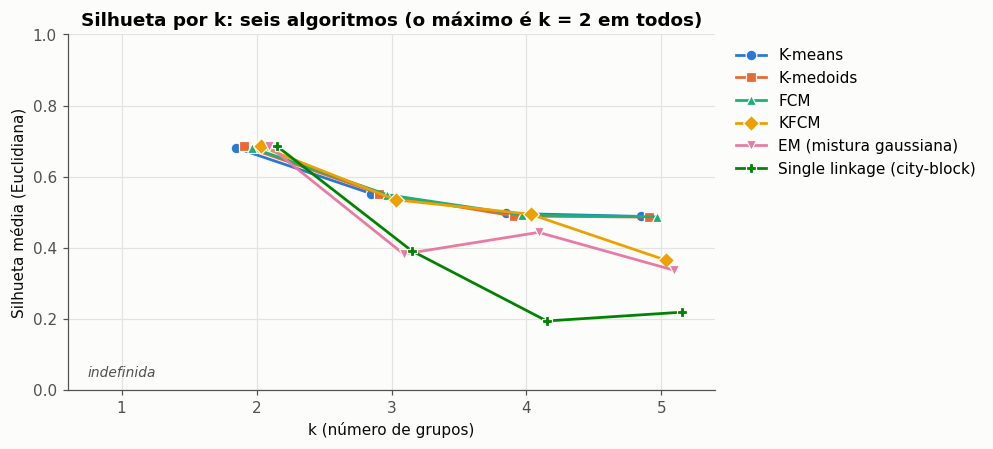

k,k = 1,k = 2,k = 3,k = 4,k = 5
K-means,indefinida,0.6808,0.5526,0.4972,0.4885
K-medoids,indefinida,0.6855,0.5526,0.4895,0.4865
FCM,indefinida,0.6808,0.5493,0.4925,0.4872
KFCM,indefinida,0.6855,0.5352,0.4946,0.3659
EM (mistura gaussiana),indefinida,0.6864,0.3827,0.4437,0.3376
Single linkage (city-block),indefinida,0.6864,0.3917,0.1946,0.2193


In [ ]:
CORES_ALGORITMOS, MARCADORES_ALGORITMOS = CORES_SERIES, MARCADORES_SERIES

curvas_q1 = pd.DataFrame({nome: aval["curva"]["silhueta"] for nome, aval in AVALIACOES.items()})

fig, ax = plt.subplots(figsize=(7.6, 4.2))
deslocamentos = np.linspace(-0.15, 0.15, len(AVALIACOES))
for (nome, aval), cor, marcador, dx in zip(AVALIACOES.items(), CORES_ALGORITMOS, MARCADORES_ALGORITMOS, deslocamentos):
    curva = aval["curva"]["silhueta"].dropna()
    ax.plot(curva.index + dx, curva.values, color=cor, linewidth=1.8, marker=marcador, markersize=7,
            markeredgecolor=CORES["fundo"], markeredgewidth=0.8, label=nome, zorder=3)
ax.text(1, 0.03, "indefinida", ha="center", va="bottom", fontsize=9, style="italic", color=CORES["texto_sec"])
ax.set_xticks(CONFIG["valores_k"])
ax.set_xlim(0.6, 5.4)
ax.set_ylim(0, 1)
ax.set_xlabel("k (número de grupos)")
ax.set_ylabel("Silhueta média (Euclidiana)")
ax.set_title("Silhueta por k: seis algoritmos (o máximo é k = 2 em todos)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
salvar_figura(fig, "q1_silhuetas_comparadas")
plt.show()

display(curvas_q1.T.rename(columns=lambda k: f"k = {k}")
        .style.format("{:.4f}", na_rep="indefinida").highlight_max(axis=1, props="font-weight: bold"))

### 6.4 Comparação das partições

As sete partições oficiais são comparadas de duas formas, **sem usar as espécies**:

1. **ARI entre algoritmos.** Mede a concordância entre as partições de dois algoritmos. ARI = 1 significa a mesma partição, a menos da numeração dos grupos. Nos pares com o DBSCAN, o ARI é calculado só sobre os objetos que ele agrupou, como na A11; o valor com o ruído como rótulo $-1$ é dado como complemento.
2. **Diferença em relação à separação pela lacuna.** A lacuna do comprimento da pétala (Seção 3.4) separa 50 objetos de 100. A célula conta quantos objetos cada partição atribui de forma diferente dessa separação, e quais são.

A última coluna repete o ARI com as espécies, já reportado, para relacionar as duas leituras.

In [ ]:
nomes_curtos_alg = {"EM (mistura gaussiana)": "EM", "Single linkage (city-block)": "Single linkage"}
rotulo = lambda nome: nomes_curtos_alg.get(nome, nome)

# 1. ARI entre as partições dos algoritmos. Com o DBSCAN, só sobre os objetos que ele agrupou (A11)
def ari_entre_algoritmos(a, b):
    mascara = agrupados if "DBSCAN" in (a, b) else np.ones(len(X), dtype=bool)
    return adjusted_rand_score(PARTICOES_Q1[a][mascara], PARTICOES_Q1[b][mascara])


ari_entre = pd.DataFrame([[ari_entre_algoritmos(a, b) for b in ALGORITMOS] for a in ALGORITMOS],
                         index=[rotulo(a) for a in ALGORITMOS], columns=[rotulo(a) for a in ALGORITMOS])
print(f"ARI entre as partições dos algoritmos (sem rótulos; pares com o DBSCAN: {int(agrupados.sum())} objetos agrupados):")
display(ari_entre.style.format("{:.3f}"))
ari_dbscan_rotulo_unico = [adjusted_rand_score(PARTICOES_Q1["DBSCAN"], PARTICOES_Q1[a]) for a in ALGORITMOS[:-1]]
print(f"Complemento: com o ruído como rótulo −1, sobre os 150 objetos, o ARI do DBSCAN com os demais fica "
      f"entre {min(ari_dbscan_rotulo_unico):.3f} e {max(ari_dbscan_rotulo_unico):.3f}.")

# 2. Diferenças em relação à separação pela lacuna (abaixo: 50 objetos; acima: 100 objetos)
linhas = []
for nome in ALGORITMOS:
    rot = PARTICOES_Q1[nome]
    agrup = rot != -1
    g_abaixo = pd.Series(rot[abaixo.to_numpy() & agrup]).mode()[0]          # grupo que contém os objetos abaixo
    acima_no_grupo_de_baixo = np.flatnonzero(~abaixo.to_numpy() & (rot == g_abaixo))
    abaixo_fora = np.flatnonzero(abaixo.to_numpy() & agrup & (rot != g_abaixo))
    linhas.append({"algoritmo": nome,
                   "tamanhos dos grupos": sorted(np.bincount(rot[agrup]).tolist(), reverse=True),
                   "ruído": int((~agrup).sum()),
                   "objetos acima da lacuna no grupo de baixo": (acima_no_grupo_de_baixo + 1).tolist(),
                   "objetos abaixo da lacuna fora dele": (abaixo_fora + 1).tolist(),
                   "ARI com as espécies": RESUMO_Q1[nome]["ARI(k*)"]})
DIFERENCAS_Q1 = pd.DataFrame(linhas).set_index("algoritmo")
print("Diferenças em relação à separação pela lacuna (números dos objetos, de 1 a 150):")
display(DIFERENCAS_Q1.style.format({"ARI com as espécies": "{:.4f}"}))

ARI entre as partições dos algoritmos (sem rótulos; pares com o DBSCAN: 140 objetos agrupados):


,K-means,K-medoids,FCM,KFCM,EM,Single linkage,DBSCAN
K-means,1.000,0.947,1.000,0.947,0.920,0.920,0.971
K-medoids,0.947,1.000,0.947,1.000,0.973,0.973,1.000
FCM,1.000,0.947,1.000,0.947,0.920,0.920,0.971
KFCM,0.947,1.000,0.947,1.000,0.973,0.973,1.000
EM,0.920,0.973,0.920,0.973,1.000,1.000,1.000
Single linkage,0.920,0.973,0.920,0.973,1.000,1.000,1.000
DBSCAN,0.971,1.000,0.971,1.000,1.000,1.000,1.000


Complemento: com o ruído como rótulo −1, sobre os 150 objetos, o ARI do DBSCAN com os demais fica entre 0.827 e 0.845.
Diferenças em relação à separação pela lacuna (números dos objetos, de 1 a 150):


,tamanhos dos grupos,ruído,objetos acima da lacuna no grupo de baixo,objetos abaixo da lacuna fora dele,ARI com as espécies
algoritmo,,,,,
K-means,"[97, 53]",0,"[58, 94, 99]",[],0.5399
K-medoids,"[99, 51]",0,[99],[],0.5584
FCM,"[97, 53]",0,"[58, 94, 99]",[],0.5399
KFCM,"[99, 51]",0,[99],[],0.5584
EM (mistura gaussiana),"[100, 50]",0,[],[],0.5681
Single linkage (city-block),"[100, 50]",0,[],[],0.5681
DBSCAN,"[90, 50]",10,[],[],0.5949


### 6.5 Estabilidade

**Algoritmos com 10 execuções por $k$.** A tabela mostra quantas das 10 execuções atingiram o melhor valor da função objetivo, a estabilidade do objetivo da Seção 4.3. A célula também confere se essa contagem coincide com o número de execuções que reproduzem a partição escolhida, a estabilidade da partição.

**Single linkage e DBSCAN** são determinísticos e executados uma única vez. Para eles, a robustez foi avaliada de outra forma nas Seções 5.6 e 5.7:

- no single linkage, a dependência do desempate no corte em $k = 3$;
- no DBSCAN, a busca de $\varepsilon$ e `min_samples` (Seção 5.7.2).

In [ ]:
EXECUCOES_Q1 = {"K-means": exec_kmeans, "K-medoids": exec_kmedoids, "FCM": exec_fcm, "KFCM": exec_kfcm,
                "EM (mistura gaussiana)": exec_gmm}
resumos = {nome: resumo_por_k(execucoes) for nome, execucoes in EXECUCOES_Q1.items()}
estab_objetivo = pd.DataFrame({rotulo(n): r["objetivo: execuções no melhor valor"] for n, r in resumos.items()}).T
estab_particao = pd.DataFrame({rotulo(n): r["partição: execuções idênticas à escolhida"] for n, r in resumos.items()}).T

print("Execuções (de 10) que atingiram o melhor valor da função objetivo:")
display(estab_objetivo.rename(columns=lambda k: f"k = {k}"))
coincidem = estab_objetivo.equals(estab_particao)
print(f"As contagens de estabilidade da partição são idênticas às do objetivo em todos os casos: {coincidem}")
if not coincidem:
    display(estab_particao.rename(columns=lambda k: f"k = {k}"))
convergencia = {rotulo(n): int(e["convergiu"].sum()) for n, e in EXECUCOES_Q1.items()}
print(f"Execuções convergidas (de 50): {convergencia}")

Execuções (de 10) que atingiram o melhor valor da função objetivo:


k,k = 1,k = 2,k = 3,k = 4,k = 5
K-means,10,10,4,2,1
K-medoids,10,10,5,2,3
FCM,10,10,10,9,5
KFCM,10,10,10,8,3
EM,10,7,4,2,1


As contagens de estabilidade da partição são idênticas às do objetivo em todos os casos: True
Execuções convergidas (de 50): {'K-means': 50, 'K-medoids': 50, 'FCM': 50, 'KFCM': 50, 'EM': 50}


### 6.6 Busca de hiperparâmetros: síntese

A tabela resume as buscas das Seções 5.1 a 5.5 e 5.7; o single linkage não tem hiperparâmetro livre. Para cada algoritmo: o número de configurações, quantas foram admissíveis e quantas ficaram na faixa de tolerância, a configuração *a priori*, a escolhida e os escores. A célula confere ainda que as execuções oficiais são as da configuração escolhida e compara, no DBSCAN, a configuração *a priori* com a escolhida, nas duas convenções de ARI.

In [ ]:
linhas = []
for codigo, busca in BUSCAS.items():
    tabela, hp, escore = busca["tabela"], busca["hiperparametros"], busca["escore"]
    escolhida, melhor, a_priori = (tabela.loc[busca["escolhida"]], tabela.loc[busca["melhor"]],
                                   tabela.loc[indice_a_priori(codigo)])
    linhas.append({"algoritmo": busca["titulo"], "hiperparâmetros": ", ".join(hp),
                   "configurações": len(tabela), "admissíveis": int(tabela["admissível"].sum()),
                   "na tolerância (1 EP)": int(tabela["na tolerância (1 EP)"].sum()),
                   "a priori": descrever(a_priori, hp), "escolhida": descrever(escolhida, hp),
                   "a priori mantida": mesma_configuracao(escolhida, busca["a_priori"], hp),
                   "escore": escore, "escore a priori": a_priori[escore], "escore escolhida": escolhida[escore],
                   "maior escore": melhor[escore], "EP": melhor["EP"]})
SINTESE_BUSCAS = pd.DataFrame(linhas).set_index("algoritmo")
display(SINTESE_BUSCAS.style.format({"a priori mantida": lambda b: "sim" if b else "não"}, precision=4))
SINTESE_BUSCAS.to_csv(DIRS["resultados"] / "q1_sintese_buscas.csv")

# As execuções oficiais vêm da configuração escolhida (conferido objeto a objeto nas Seções 5.1 a 5.5 e 5.7)
assert all(BUSCAS[c]["execucoes"][BUSCAS[c]["escolhida"]]["objetivo"].equals(e["objetivo"])
           for c, e in [("kmeans", exec_kmeans), ("kmedoids", exec_kmedoids), ("fcm", exec_fcm),
                        ("kfcm", exec_kfcm), ("gmm", exec_gmm)])

# DBSCAN: configuração a priori (Etapas 1 a 8) x escolhida pela busca, nas duas convenções de ARI
linhas = []
for nome, i in (("a priori (joelho)", indice_a_priori("dbscan")), ("escolhida (busca)", BUSCAS["dbscan"]["escolhida"])):
    c, rot = BUSCAS["dbscan"]["tabela"].loc[i], BUSCAS["dbscan"]["particoes"][i]
    agrup = rot != -1
    linhas.append({"DBSCAN": nome, "ε (cm)": c["eps"], "min_samples": c["min_samples"], "grupos": c["grupos"],
                   "tamanhos": c["tamanhos dos grupos"], "ruído": c["ruído"], "Sil sem ruído": c["Sil sem ruído"],
                   "Sil com ruído = 0": c["Sil com ruído = 0"],
                   "ARI sem o ruído (critério)": avaliar_com_classes(rot[agrup], y_verdadeiro[agrup])[0],
                   "ARI, ruído = −1": avaliar_com_classes(rot)[0]})
display(pd.DataFrame(linhas).set_index("DBSCAN").style.format(precision=4))

,hiperparâmetros,configurações,admissíveis,na tolerância (1 EP),a priori,escolhida,a priori mantida,escore,escore a priori,escore escolhida,maior escore,EP
algoritmo,,,,,,,,,,,,
K-means,inicializacao,2,2,2,inicializacao = sorteio,inicializacao = sorteio,sim,Sil(k*),0.6808,0.6808,0.6808,0.0128
K-medoids,inicializacao,3,3,3,inicializacao = sorteio,inicializacao = sorteio,sim,Sil(k*),0.6855,0.6855,0.6855,0.0132
FCM,m,4,4,4,m = 2,m = 2,sim,Sil(k*),0.6808,0.6808,0.6808,0.0128
KFCM,"quantil_largura, m",15,10,10,"quantil_largura = 0.5, m = 2","quantil_largura = 0.5, m = 2",sim,Sil(k*),0.6855,0.6855,0.6864,0.0138
EM (mistura gaussiana),"covariance_type, reg_covar",12,11,11,"covariance_type = full, reg_covar = 0.0008333","covariance_type = full, reg_covar = 0.0008333",sim,Sil(k*),0.6864,0.6864,0.6864,0.0138
DBSCAN,"min_samples, eps",120,110,73,"min_samples = 8, eps = 0.5477","min_samples = 8, eps = 0.65",não,Sil com ruído = 0,0.6612,0.6756,0.6864,0.0138


,ε (cm),min_samples,grupos,tamanhos,ruído,Sil sem ruído,Sil com ruído = 0,ARI sem o ruído (critério),"ARI, ruído = −1"
DBSCAN,,,,,,,,,
a priori (joelho),0.5477,8,2,"[86, 49]",15,0.7347,0.6612,0.6013,0.5252
escolhida (busca),0.6500,8,2,"[90, 50]",10,0.7239,0.6756,0.5949,0.5468


**Leitura.**
- **Cinco algoritmos mantiveram a configuração *a priori*.** No k-means, no k-medoids, no FCM e no EM, todas as configurações admissíveis deram a mesma partição em $k^*=2$ e o mesmo escore. No KFCM, a melhor (largura no quantil 0,25, $m = 1{,}5$) supera a *a priori* em 0,0009, muito menos que a tolerância de 1 EP (0,014).
- **As inadmissíveis são as que degeneram:** o KFCM com kernel estreito, cujos protótipos coincidem e dão menos grupos efetivos que $k$; e o EM com covariância completa sem regularização efetiva, cujos componentes colapsam.
- **Só o DBSCAN mudou.** A configuração *a priori* (joelho, 15 objetos de ruído) ficou 0,025 abaixo da melhor, fora da faixa de tolerância. A escolhida mantém `min_samples` = 8 e usa $\varepsilon = 0{,}65$ cm, com 10 objetos de ruído e os mesmos 2 grupos.
- **A escolhida nem sempre é a de maior escore.** No KFCM (a *a priori*, 0,0009 abaixo da melhor) e no DBSCAN (0,676 contra 0,686), a configuração escolhida não é a de maior escore numérico da grade: nos dois casos, a escolha segue o critério definido antes da busca. A faixa de tolerância é uma heurística de parcimônia, e não uma prova de equivalência estatística (Seção 4.9).
- **As conclusões anteriores continuam válidas:**
  - $k^* = 2$ em todos os algoritmos com escolha de $k$;
  - as seis partições oficiais desses algoritmos não mudaram, com as mesmas silhuetas e o mesmo ARI;
  - o DBSCAN continua a encontrar os 2 grupos da lacuna.
- **O que mudou no DBSCAN.** O ARI oficial passou de 0,525 (ruído com rótulo $-1$, configuração anterior) para 0,595 (sem o ruído, configuração escolhida). A mudança vem sobretudo da convenção: na configuração anterior, o ARI sem o ruído já era 0,601 (tabela acima). Na escolhida, 0,595 é exatamente o teto de 2 grupos para os 140 objetos agrupados.
- **Separação entre busca e resultados.** As execuções oficiais reproduzem exatamente as da configuração escolhida em cada busca.

### 6.7 Por que todos os métodos favoreceram dois grupos

**Resultado.** Os seis algoritmos que escolhem $k$ pela silhueta selecionaram $k^\*=2$, com valores entre 0,681 e 0,686. O DBSCAN também encontrou 2 grupos densos.

**Estrutura dos dados.** A análise exploratória já indicava uma lacuna entre 1,9 e 3,0 cm no comprimento da pétala, separando 50 objetos dos outros 100. Esses 100 não apresentam lacunas nos atributos. Os algoritmos confirmaram essa divisão pelo dendrograma, pelo DBSCAN e pelas partições finais.

**Critério.** Versicolor e virginica se sobrepõem. Dividir esse grupo de 100 objetos cria grupos próximos, reduzindo a silhueta. Como ela mede coesão e separação, tende a favorecer dois grupos nessa estrutura.

**Consequência para o ARI.** Com três espécies e apenas dois grupos, o ARI máximo possível é 0,568. Os seis algoritmos ficaram entre 0,540 e 0,568, indicando que a maior parte da diferença em relação a 1 vem da escolha de dois grupos, não de erros de atribuição. O DBSCAN atinge seu máximo possível (0,595) quando os objetos de ruído são excluídos.

**Ressalva.** Essa conclusão vale para os atributos brutos (A4) e a distância Euclidiana (A5), definidos antes dos experimentos.

### 6.8 Diferenças metodológicas, qualidade e limitações

**Qualidade das partições.** As seis partições escolhidas se resumem a três:

| Partição | Algoritmos | Tamanhos | Objetos acima da lacuna no grupo pequeno | Sil(k*) | ARI(k*) |
|---|---|---|---|---|---|
| A | k-means, FCM | 97 / 53 | 58, 94, 99 | 0,681 | 0,540 |
| B | k-medoids, KFCM | 99 / 51 | 99 | 0,685 | 0,558 |
| C | EM, single linkage | 100 / 50 | nenhum | 0,686 | 0,568 |

As partições diferem em no máximo 3 objetos, todos próximos à lacuna. O ARI entre elas é de pelo menos 0,920. Essas diferenças refletem as formas distintas de cada algoritmo definir as fronteiras, mas não indicam superioridade geral de um método.

**DBSCAN.** O algoritmo encontra regiões densas e classifica objetos isolados como ruído, sem escolher $k$ pela silhueta. Sua silhueta é 0,724 sem os 10 objetos de ruído e 0,676 quando eles recebem valor zero. O ARI é 0,595 sem o ruído e 0,547 considerando os 150 objetos. Esses valores não são diretamente comparáveis aos demais, pois foram calculados sobre populações diferentes. Ainda assim, os grupos encontrados acompanham a separação pela lacuna.

**Estabilidade.**
- Todas as 250 execuções convergiram.
- FCM e KFCM foram os mais estáveis até $k=3$.
- O EM apresentou instabilidade já em $k=2$.
- Para $k \geq 4$, todos os métodos perderam estabilidade, justificando as 10 execuções.
- Single linkage é determinístico. No DBSCAN, o número de grupos permanece estável em uma ampla faixa de $\varepsilon$, mas a quantidade de ruído varia.

**Particularidades e limitações dos algoritmos.**

| Algoritmo | Particularidade | Limitação observada |
|---|---|---|
| K-means | Usa médias como protótipos | Sensível à inicialização |
| K-medoids | Usa objetos reais como protótipos | Garante apenas ótimo local |
| FCM | Permite pertinências graduais | A conversão crisp perde essa informação |
| KFCM | Usa a geometria do kernel | A largura $\sigma$ pode causar colapso dos grupos |
| EM | Modela grupos com covariâncias | Sensível à regularização e à inicialização |
| Single linkage | Constrói uma hierarquia de grupos | O encadeamento prejudica cortes com $k \geq 3$ |
| DBSCAN | Agrupa por densidade | A quantidade de ruído depende dos parâmetros |

**Limitações gerais.**
- Foi utilizada apenas uma base de dados.
- A silhueta Euclidiana favorece grupos compactos e separados.
- Os atributos brutos são dominados pelo comprimento da pétala.
- O ARI foi calculado apenas para $k^\*$.
- As buscas usaram grades pequenas e critérios internos. Outras escolhas poderiam produzir resultados diferentes, principalmente no DBSCAN. A faixa de tolerância de 1 EP é apenas uma heurística, pois as silhuetas não são observações independentes.

### 6.9 Conclusão da Questão 1

**Estrutura identificada.** Os sete algoritmos encontraram a mesma estrutura principal na base Iris: as setosas formam um grupo bem separado, enquanto versicolor e virginica ficam reunidas.

- Os seis algoritmos que selecionam o número de grupos escolheram $k^*=2$, com silhuetas entre 0,681 e 0,686.
- O DBSCAN também encontrou dois grupos, além de 10 objetos classificados como ruído.
- O resultado é coerente com a separação observada na análise exploratória e com a sobreposição entre versicolor e virginica.

**Concordância entre os algoritmos.** As partições encontradas são muito semelhantes. Entre os seis algoritmos com escolha de $k$, o ARI mínimo foi 0,920, e as diferenças ficaram concentradas em apenas três objetos de fronteira.

Os valores de ARI em relação às espécies (0,540 a 0,568) refletem principalmente a união de versicolor e virginica em um único grupo. EM e single linkage atingiram o limite teórico de 0,568. K-medoids e KFCM ficaram a um objeto desse resultado, enquanto k-means e FCM ficaram a três. O DBSCAN apresentou ARI de 0,595, mas esse valor considera apenas os 140 objetos que não foram classificados como ruído, portanto não é diretamente comparável aos demais.

**Busca de hiperparâmetros.** As buscas sem utilizar os rótulos mantiveram as configurações iniciais de cinco algoritmos, geralmente com a mesma partição. Apenas o DBSCAN apresentou mudança relevante: $\varepsilon$ passou de 0,548 para 0,65 cm, reduzindo o número de objetos de ruído de 15 para 10. Essas alterações não modificaram as conclusões.

**Nenhum método se mostrou superior.** Cada algoritmo apresentou vantagens diferentes, dependendo do objetivo:

- **FCM e KFCM:** mostram os objetos de fronteira pelas pertinências e apresentaram boa estabilidade.
- **EM:** oferece uma abordagem probabilística, mas exige regularização.
- **Single linkage:** apresenta a hierarquia dos grupos e evidencia a separação entre os dois blocos.
- **DBSCAN:** identifica objetos periféricos como ruído.
- **K-means e k-medoids:** são métodos mais simples, sendo que o k-medoids utiliza flores reais como representantes dos grupos.

## `7. Questão 2 — Redução de dimensionalidade`

O enunciado pede quatro métodos sobre a base Iris, cada um com as saídas padrão da ferramenta, o gráfico 2D e um comentário. Os quatro **não produzem o mesmo tipo de informação**:

| | PCA | Kernel PCA | t-SNE | UMAP |
|---|---|---|---|---|
| tipo | linear | não linear (kernel) | não linear (vizinhanças) | não linear (vizinhanças) |
| o que otimiza | variância projetada | variância no espaço induzido pelo kernel | divergência KL entre vizinhanças (alta × baixa dimensão) | entropia cruzada entre grafos de vizinhança |
| eixos | combinações lineares dos atributos centrados (cargas adimensionais; escores em cm) | componentes no espaço do kernel, sem cargas | sem significado próprio | sem significado próprio |
| saída quantitativa própria | variância explicada | autovalores da matriz de kernel centrada | divergência KL final | grafo de vizinhança fuzzy |
| distâncias no gráfico | aproximam as distâncias originais | refletem a geometria do kernel | só as vizinhanças locais são confiáveis | só as vizinhanças locais são confiáveis |

**Cuidados adotados:**

- **Pré-processamento.** Todos os métodos usam a mesma matriz `X` de atributos brutos (A4). Na PCA, isso significa decompor a matriz de **covariâncias**, e não a de correlações.
- **Rótulos.** As espécies são usadas **só** para colorir os gráficos e interpretar os resultados. Nenhuma transformação recebe os rótulos, e nenhum hiperparâmetro foi ajustado com eles.
- **Reprodutibilidade.** Os métodos estocásticos (t-SNE e UMAP) usam a semente global; a PCA e o Kernel PCA são calculados de forma exata e determinística.
- **Sinais.** Autovetores são definidos a menos do sinal, então refletir um eixo não muda a interpretação. O scikit-learn fixa o sinal de forma determinística.

In [ ]:
def grafico_projecao(ax, Z, titulo, rotulo_x, rotulo_y):
    """Dispersão 2D colorida pelas espécies. Os rótulos são usados SÓ para colorir."""
    for c, (classe, cor, marcador) in enumerate(zip(CLASSES, CORES_CLASSES, MARCADORES)):
        m = y_verdadeiro == c
        ax.scatter(Z[m, 0], Z[m, 1], s=24, color=cor, marker=marcador, edgecolor=CORES["fundo"],
                   linewidth=0.6, alpha=0.9, label=classe.replace("Iris-", ""))
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel(rotulo_y)
    ax.set_title(titulo)
    ax.set_aspect("equal", adjustable="datalim")       # mesma escala nos dois eixos


def figura_projecao(Z, titulo, rotulo_x, rotulo_y, nome_arquivo, tamanho=(6.4, 4.6)):
    fig, ax = plt.subplots(figsize=tamanho)
    grafico_projecao(ax, Z, titulo, rotulo_x, rotulo_y)
    ax.legend(title="espécie (só cor)", loc="best")
    salvar_figura(fig, nome_arquivo)
    plt.show()


def verificar_embedding(Z, n_dims):
    """Verificações comuns: dimensões corretas e todos os valores finitos."""
    return {"dimensões": Z.shape == (len(X), n_dims), "valores finitos": bool(np.isfinite(Z).all())}

### 7.1 PCA

**Método.** A PCA encontra as direções ortogonais de maior variância. Elas são os autovetores da matriz de covariâncias $\mathbf S$, e a variância ao longo de cada uma é o autovalor correspondente.

- A $j$-ésima componente é a projeção $z_{ij} = (\mathbf x_i - \bar{\mathbf x})^\top \mathbf a_j$, em que $\mathbf a_j$ é o vetor de **cargas**: o peso de cada atributo.
- A proporção da variância explicada é $\lambda_j / \sum_l \lambda_l$.

**Unidades.** É preciso distinguir dois objetos:
- as **cargas** $\mathbf a_j$ (`components_`) são coeficientes **adimensionais**: cada $\mathbf a_j$ é um vetor unitário ($\lVert \mathbf a_j \rVert = 1$), e a mesma carga vale qualquer que seja a unidade comum dos atributos;
- os **escores** $z_{ij}$, as coordenadas dos objetos nas componentes, estão em **cm**, porque combinam atributos em cm com pesos sem unidade. A variância de cada componente, $\lambda_j$, está em cm².

Parte da literatura chama de "cargas" os vetores reescalados $\sqrt{\lambda_j}\,\mathbf a_j$, que têm unidade de cm. Aqui, "carga" designa sempre o vetor unitário de `components_`.

**Implementação** (`sklearn.decomposition.PCA`):

- todas as 4 componentes, para mostrar o espectro completo;
- `svd_solver="full"`: decomposição exata e determinística;
- sem *whitening*;
- nenhum hiperparâmetro foi ajustado.

**Saídas padrão do scikit-learn:**

| Saída | Conteúdo |
|---|---|
| `explained_variance_` | variâncias |
| `explained_variance_ratio_` | proporções |
| `singular_values_` | valores singulares |
| `components_` | cargas (coeficientes adimensionais; cada linha é um vetor unitário) |
| `mean_` | médias |
| `noise_variance_` | variância residual |
| `n_components_` | número de componentes |

In [ ]:
pca = PCA(n_components=X.shape[1], svd_solver="full").fit(X)
Z_pca = pca.transform(X)                                         # escores nas 4 componentes

componentes = [f"CP{j + 1}" for j in range(pca.n_components_)]
display(pd.DataFrame({"variância (cm²)": pca.explained_variance_,
                      "proporção": pca.explained_variance_ratio_,
                      "proporção acumulada": np.cumsum(pca.explained_variance_ratio_),
                      "valor singular": pca.singular_values_}, index=componentes)
        .style.format({"variância (cm²)": "{:.4f}", "proporção": "{:.4f}",
                       "proporção acumulada": "{:.4f}", "valor singular": "{:.3f}"}))
print("Cargas (components_): coeficientes adimensionais; cada linha é um vetor unitário")
display(pd.DataFrame(pca.components_, index=componentes, columns=[NOMES_CURTOS[a] for a in ATRIBUTOS]).round(3))
print(f"mean_ (cm): {dict(zip([NOMES_CURTOS[a] for a in ATRIBUTOS], pca.mean_.round(3)))}")
print(f"n_components_ = {pca.n_components_} | noise_variance_ = {pca.noise_variance_:.4f} "
      f"(zero: todas as componentes foram mantidas)")

,variância (cm²),proporção,proporção acumulada,valor singular
CP1,4.2248,0.9246,0.9246,25.090
CP2,0.2422,0.0530,0.9776,6.008
CP3,0.0785,0.0172,0.9948,3.421
CP4,0.0237,0.0052,1.0000,1.879


Cargas (components_): coeficientes adimensionais; cada linha é um vetor unitário


,Comp. sépala,Larg. sépala,Comp. pétala,Larg. pétala
CP1,0.362,-0.082,0.857,0.359
CP2,0.657,0.730,-0.176,-0.075
CP3,-0.581,0.596,0.073,0.549
CP4,0.317,-0.324,-0.480,0.751


mean_ (cm): {'Comp. sépala': np.float64(5.843), 'Larg. sépala': np.float64(3.054), 'Comp. pétala': np.float64(3.759), 'Larg. pétala': np.float64(1.199)}
n_components_ = 4 | noise_variance_ = 0.0000 (zero: todas as componentes foram mantidas)


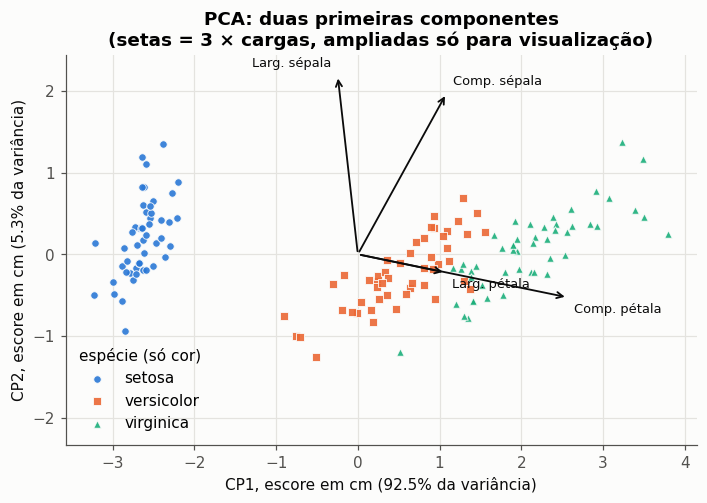

In [ ]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
grafico_projecao(ax, Z_pca[:, :2], "PCA: duas primeiras componentes\n(setas = 3 × cargas, ampliadas só para visualização)",
                 f"CP1, escore em cm ({100 * pca.explained_variance_ratio_[0]:.1f}% da variância)",
                 f"CP2, escore em cm ({100 * pca.explained_variance_ratio_[1]:.1f}% da variância)")
# As cargas são adimensionais (vetores unitários) e ficariam curtas demais diante dos escores em cm.
# O fator 3 é SÓ visual: o comprimento das setas não está na escala dos escores.
escala = 3.0
for j, atributo in enumerate(ATRIBUTOS):
    dx, dy = escala * pca.components_[0, j], escala * pca.components_[1, j]
    ax.annotate("", xy=(dx, dy), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": CORES["texto"], "linewidth": 1.2})
    ax.annotate(NOMES_CURTOS[atributo], (dx, dy), xytext=(4 if dx >= 0 else -4, 6 if dy >= 0 else -10),
                textcoords="offset points", ha="left" if dx >= 0 else "right", fontsize=8.5,
                color=CORES["texto"])
ax.legend(title="espécie (só cor)", loc="lower left")
salvar_figura(fig, "q2_pca")
plt.show()

**Leitura das setas.** Cada seta mostra as cargas de um atributo em CP1 e CP2, **multiplicadas por 3 apenas para ficarem visíveis**. Sem esse fator, os vetores de cargas são unitários e adimensionais, enquanto os pontos são escores em cm. Por isso:
- a direção de cada seta e a comparação entre setas são interpretáveis;
- o comprimento absoluto das setas não está na escala dos eixos e não deve ser lido como distância.

#### 7.1.1 Verificações da PCA

- As variâncias são os autovalores da matriz de covariâncias amostral, e somam a variância total (o traço).
- As cargas são ortonormais.
- Os escores são $(\mathbf X - \bar{\mathbf x})\mathbf A^\top$, não correlacionados entre si, e cada um tem a variância da sua componente.
- Com as 4 componentes, a reconstrução é exata.
- Os valores singulares satisfazem $s_j^2/(n-1) = \lambda_j$.
- Um novo ajuste reproduz o mesmo resultado.

In [ ]:
S_cov = np.cov(X, rowvar=False)                                    # divisor n - 1, como o scikit-learn
autovalores_S = np.linalg.eigvalsh(S_cov)[::-1]
escores = (X - X.mean(axis=0)) @ pca.components_.T

verif_pca = pd.Series({
    **verificar_embedding(Z_pca, X.shape[1]),
    "variâncias = autovalores de S": np.allclose(pca.explained_variance_, autovalores_S),
    "soma das variâncias = traço de S": bool(np.isclose(pca.explained_variance_.sum(), np.trace(S_cov))),
    "cargas ortonormais": np.allclose(pca.components_ @ pca.components_.T, np.eye(X.shape[1])),
    "escores = (X - média) A^T": np.allclose(Z_pca, escores),
    "escores não correlacionados, var = λ": np.allclose(np.cov(Z_pca, rowvar=False), np.diag(pca.explained_variance_), atol=1e-10),
    "reconstrução exata com 4 componentes": np.allclose(pca.inverse_transform(Z_pca), X),
    "s² / (n - 1) = λ": np.allclose(pca.singular_values_ ** 2 / (len(X) - 1), pca.explained_variance_),
    "reprodutível": np.array_equal(PCA(n_components=X.shape[1], svd_solver="full").fit(X).transform(X), Z_pca),
}, name="verificação")
display(verif_pca.to_frame())
assert verif_pca.all()
print("Verificações da PCA: OK")

,verificação
dimensões,True
valores finitos,True
variâncias = autovalores de S,True
soma das variâncias = traço de S,True
cargas ortonormais,True
escores = (X - média) A^T,True
"escores não correlacionados, var = λ",True
reconstrução exata com 4 componentes,True
s² / (n - 1) = λ,True
reprodutível,True


Verificações da PCA: OK


#### 7.1.2 Comentários

**Variância explicada.** A CP1 explica 92,5% da variância e a CP2, 5,3%. Juntas, representam 97,8%, tornando o gráfico 2D uma boa representação dos dados originais.

**Cargas.**
- A CP1 representa principalmente o tamanho da flor, com maior peso para o comprimento da pétala (0,857).
- A CP2 está relacionada às medidas da sépala.
- As cargas são coeficientes sem unidade; os escores representam as coordenadas dos pontos em cm. Os dados não foram padronizados, mantendo a decisão da A4.

**Separação e sobreposição.**
- As setosas ficam isoladas na CP1, reproduzindo a lacuna observada nas pétalas.
- Versicolor e virginica se sobrepõem entre aproximadamente 0,5 e 1,6 na CP1. A CP2 pouco contribui para separá-las.

**Verificações.** Os autovalores correspondem às variâncias, as cargas são ortonormais, os escores não são correlacionados e a reconstrução com quatro componentes é exata.

### 7.2 Kernel PCA

**Método.** A Kernel PCA aplica a PCA em um espaço de características criado por um kernel, sem calcular esse espaço diretamente. Para isso, utiliza a matriz de kernel centrada:

$$\tilde K = HKH, \qquad H = I - \frac{1}{n}\mathbf 1\mathbf 1^\top.$$

Seus autovalores e autovetores definem as componentes, e as coordenadas são calculadas por $\sqrt{\mu_j}\alpha_{ij}$.

**Interpretação dos autovalores.**
- $\mu_j/n$ representa a variância da componente no espaço do kernel.
- A fração $\mu_j/\sum_l\mu_l$ indica a variância explicada nesse espaço.
- Diferentemente da PCA comum, esses valores dependem do kernel e de sua largura. Não são comparáveis à variância dos atributos originais e não existem cargas, pois as componentes não são combinações lineares dos atributos.

**Hiperparâmetros** (`sklearn.decomposition.KernelPCA`).
- Kernel gaussiano, com a mesma largura do KFCM: $2\sigma^2$ igual à mediana das distâncias quadráticas.
- `eigen_solver="dense"`: decomposição exata e determinística.
- `n_components=None`: calcula todas as componentes com autovalor positivo; o gráfico apresenta as duas primeiras.

**Saídas do scikit-learn.**

| Saída | Conteúdo |
|---|---|
| `eigenvalues_` | Autovalores da matriz de kernel |
| `eigenvectors_` | Autovetores da matriz de kernel |
| `gamma_` | Valor de $\gamma$ utilizado |
| `X_fit_` | Dados usados no ajuste |

In [ ]:
GAMMA_KPCA = 1 / (2 * SIGMA2_KFCM)
kpca = KernelPCA(n_components=None, kernel="rbf", gamma=GAMMA_KPCA, eigen_solver="dense").fit(X)
Z_kpca = kpca.transform(X)
mu = kpca.eigenvalues_

print(f"gamma_ = {kpca.gamma_:.5f} (σ² = {SIGMA2_KFCM:.4f} cm²) | componentes com autovalor positivo: {len(mu)} "
      f"| eigenvectors_: {kpca.eigenvectors_.shape} | X_fit_: {kpca.X_fit_.shape}")
display(pd.DataFrame({"autovalor μ (matriz de kernel centrada)": mu[:8],
                      "variância das coordenadas (μ / n)": mu[:8] / len(X),
                      "fração do traço de K̃ (variância no espaço do kernel)": mu[:8] / mu.sum(),
                      "fração acumulada": np.cumsum(mu)[:8] / mu.sum()},
                     index=[f"CPK{j + 1}" for j in range(8)])
        .style.format("{:.4f}"))
print("Atenção: as frações acima se referem à variância no espaço induzido pelo kernel, "
      "e não à variância dos atributos originais (não são comparáveis à PCA).")

gamma_ = 0.17953 (σ² = 2.7850 cm²) | componentes com autovalor positivo: 146 | eigenvectors_: (150, 146) | X_fit_: (150, 4)


,autovalor μ (matriz de kernel centrada),variância das coordenadas (μ / n),fração do traço de K̃ (variância no espaço do kernel),fração acumulada
CPK1,48.6991,0.3247,0.5838,0.5838
CPK2,17.1197,0.1141,0.2052,0.7890
CPK3,4.7194,0.0315,0.0566,0.8456
CPK4,3.4949,0.0233,0.0419,0.8875
CPK5,2.8201,0.0188,0.0338,0.9213
CPK6,1.7446,0.0116,0.0209,0.9422
CPK7,1.1094,0.0074,0.0133,0.9555
CPK8,0.6574,0.0044,0.0079,0.9634


Atenção: as frações acima se referem à variância no espaço induzido pelo kernel, e não à variância dos atributos originais (não são comparáveis à PCA).


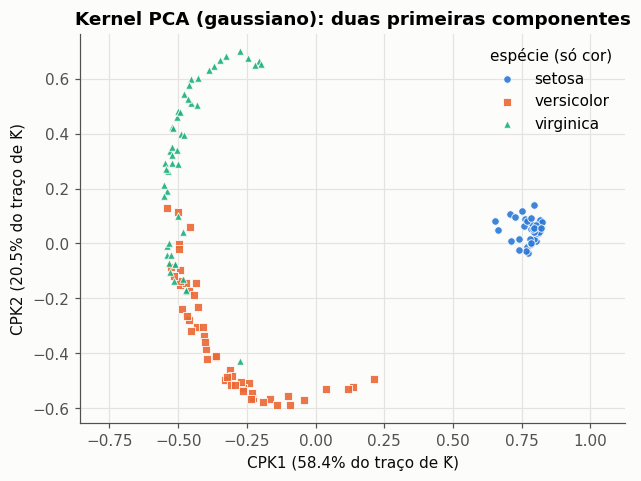

In [ ]:
figura_projecao(Z_kpca[:, :2], "Kernel PCA (gaussiano): duas primeiras componentes",
                f"CPK1 ({100 * mu[0] / mu.sum():.1f}% do traço de K̃)",
                f"CPK2 ({100 * mu[1] / mu.sum():.1f}% do traço de K̃)", "q2_kernel_pca")

#### 7.2.1 Verificações do Kernel PCA

- **Autovalores:** coincidem com os da matriz centrada $\tilde K = HKH$, construída de forma independente com a mesma função de kernel da Seção 5.4.
- **Número de componentes:** o kernel gaussiano é estritamente positivo definido para pontos distintos. Por isso, $K$ tem posto igual ao número de pontos distintos (147, já que a base tem duplicatas), e a centralização remove mais uma dimensão. O número esperado de autovalores positivos é 146.
- **Coordenadas:** são $\sqrt{\mu_j}\,\boldsymbol\alpha_j$, mutuamente ortogonais, com variância $\mu_j/n$.
- **Limite $\sigma \to \infty$:** com um kernel gaussiano muito largo, as duas primeiras componentes devem coincidir, a menos de sinal e escala, com as da PCA linear. É o mesmo argumento de expansão usado para o KFCM.
- **Reprodutibilidade:** um novo ajuste dá o mesmo resultado.

In [ ]:
n_obj = len(X)
H_c = np.eye(n_obj) - np.ones((n_obj, n_obj)) / n_obj
K_c = H_c @ matriz_kernel(X, "gaussiano", SIGMA2_KFCM) @ H_c          # mesma função de kernel do KFCM
mu_independente = np.linalg.eigvalsh(K_c)[::-1]
n_distintos = len(np.unique(X, axis=0))

kpca_largo = KernelPCA(n_components=2, kernel="rbf", gamma=GAMMA_KPCA / 1e4, eigen_solver="dense").fit_transform(X)
corr_limite = [abs(np.corrcoef(kpca_largo[:, j], Z_pca[:, j])[0, 1]) for j in range(2)]

verif_kpca = pd.Series({
    **verificar_embedding(Z_kpca, len(mu)),
    "autovalores = os de HKH (independente)": np.allclose(mu, mu_independente[:len(mu)]),
    f"nº de componentes = pontos distintos - 1 ({n_distintos} - 1)": len(mu) == n_distintos - 1,
    "coordenadas = √μ · α": np.allclose(Z_kpca, kpca.eigenvectors_ * np.sqrt(mu)),
    "coordenadas ortogonais, var = μ / n": np.allclose(Z_kpca.T @ Z_kpca / n_obj, np.diag(mu / n_obj), atol=1e-8),
    "limite σ→∞: |corr| com CP1 e CP2 da PCA > 0,9999": min(corr_limite) > 0.9999,
    "reprodutível": np.array_equal(KernelPCA(n_components=None, kernel="rbf", gamma=GAMMA_KPCA,
                                             eigen_solver="dense").fit(X).transform(X), Z_kpca),
}, name="verificação")
display(verif_kpca.to_frame())
print(f"Limite σ→∞ (σ² x 10⁴): |corr| com a PCA = {corr_limite[0]:.6f} (CP1), {corr_limite[1]:.6f} (CP2)")
assert verif_kpca.all()
print("Verificações do Kernel PCA: OK")

,verificação
dimensões,True
valores finitos,True
autovalores = os de HKH (independente),True
nº de componentes = pontos distintos - 1 (147 - 1),True
coordenadas = √μ · α,True
"coordenadas ortogonais, var = μ / n",True
"limite σ→∞: |corr| com CP1 e CP2 da PCA > 0,9999",True
reprodutível,True


Limite σ→∞ (σ² x 10⁴): |corr| com a PCA = 1.000000 (CP1), 1.000000 (CP2)
Verificações do Kernel PCA: OK


#### 7.2.2 Comentários

**Espectro.** O kernel gaussiano ($\gamma=0{,}180$) gerou 146 autovalores positivos. As duas primeiras componentes explicam 78,9% da variância no espaço do kernel, e as oito primeiras, 96,3%. Esses valores não são comparáveis aos 97,8% da PCA, pois se referem a espaços diferentes.

**Separação e sobreposição.**
- As setosas formam um grupo compacto e isolado na primeira componente.
- Versicolor e virginica aparecem em um arco e se misturam na região intermediária.

**Efeito do kernel.** O arco representa uma variação contínua entre versicolor e virginica, não dois grupos separados. Já a compactação das setosas ocorre porque o kernel limita as distâncias entre os objetos, como também observado no KFCM.

**Verificações.** Os resultados conferem com uma decomposição independente. Com um kernel muito largo, as componentes coincidem com as da PCA, mostrando que a não linearidade depende da largura escolhida.

### 7.3 t-SNE

**Método.** O t-SNE (van der Maaten & Hinton, 2008) transforma distâncias em probabilidades de vizinhança e busca uma representação em 2D que preserve essas relações, minimizando a divergência KL.

**Interpretação do gráfico.**
- **Pode:** identificar objetos próximos, pois o método preserva vizinhanças locais.
- **Não pode:** interpretar distâncias entre grupos, tamanhos, eixos ou variância explicada.
- A principal medida de ajuste é a divergência KL final, comparável apenas entre execuções com a mesma perplexidade.

**Hiperparâmetros** (`sklearn.manifold.TSNE`).

| Parâmetro | Valor | Justificativa |
|---|---|---|
| Perplexidade | 30 | Padrão, dentro da faixa recomendada |
| `early_exaggeration` | 12 | Padrão |
| `learning_rate` | `"auto"` | Regra de Belkina et al. (2019) |
| `init` | `"pca"` | Aproveita a estrutura inicial da PCA |
| `method` | `"exact"` | Viável para 150 objetos |
| `max_iter` | 1000 | Padrão |
| `n_iter_without_progress` | 300 | Padrão |
| `min_grad_norm` | $10^{-7}$ | Padrão |
| `random_state` | Semente global | Reprodutibilidade |

**Critérios de parada.** A otimização ocorre em duas fases: 250 iterações com exageração inicial e, depois, as demais. Pode parar antes de 1000 iterações se a KL ficar sem melhorar por 300 iterações ou se a norma do gradiente cair abaixo de $10^{-7}$. Essas verificações ocorrem a cada 50 iterações. Usar todas as iterações não garante que o mínimo foi alcançado.

**Saídas do scikit-learn.**
- `embedding_`: coordenadas em 2D.
- `kl_divergence_`: divergência KL final.
- `n_iter_`: índice da última iteração, começando em zero. Assim, sem parada antecipada, vale 999 para `max_iter` = 1000.
- `learning_rate_`: taxa de aprendizado utilizada.

embedding_: (150, 2) | kl_divergence_ = 0.1219 | n_iter_ = 999 (índice da última iteração, a partir de 0: 1000 iterações de max_iter = 1000) | learning_rate_ = 50.0 | perplexidade = 30


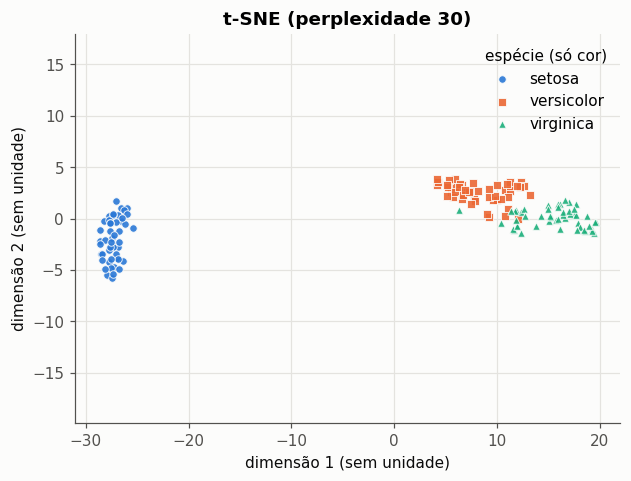

In [ ]:
def ajustar_tsne(X, semente, **ajustes):
    """t-SNE com os hiperparâmetros de CONFIG["tsne"] (ajustes só na análise de sensibilidade)."""
    p = {**CONFIG["tsne"], **ajustes}
    return TSNE(n_components=2, perplexity=p["perplexity"], early_exaggeration=p["early_exaggeration"],
                learning_rate=p["learning_rate"], init=p["init"], max_iter=p["max_iter"],
                method=p["method"], metric="euclidean", random_state=semente).fit(X)


tsne = ajustar_tsne(X, CONFIG["semente_global"])
Z_tsne = tsne.embedding_
print(f"embedding_: {Z_tsne.shape} | kl_divergence_ = {tsne.kl_divergence_:.4f} "
      f"| n_iter_ = {tsne.n_iter_} (índice da última iteração, a partir de 0: "
      f"{tsne.n_iter_ + 1} iterações de max_iter = {CONFIG['tsne']['max_iter']}) "
      f"| learning_rate_ = {tsne.learning_rate_:.1f} | perplexidade = {CONFIG['tsne']['perplexity']}")
figura_projecao(Z_tsne, "t-SNE (perplexidade 30)", "dimensão 1 (sem unidade)", "dimensão 2 (sem unidade)", "q2_tsne")

#### 7.3.1 Sensibilidade à perplexidade (não substitui a configuração oficial)

O mesmo t-SNE é ajustado com perplexidade 5, 30 e 50, com a mesma semente e a mesma inicialização. O objetivo é mostrar o que **muda** com o hiperparâmetro: tamanhos aparentes e distâncias entre grupos. As conclusões só devem se apoiar no que **não muda** entre os três gráficos.

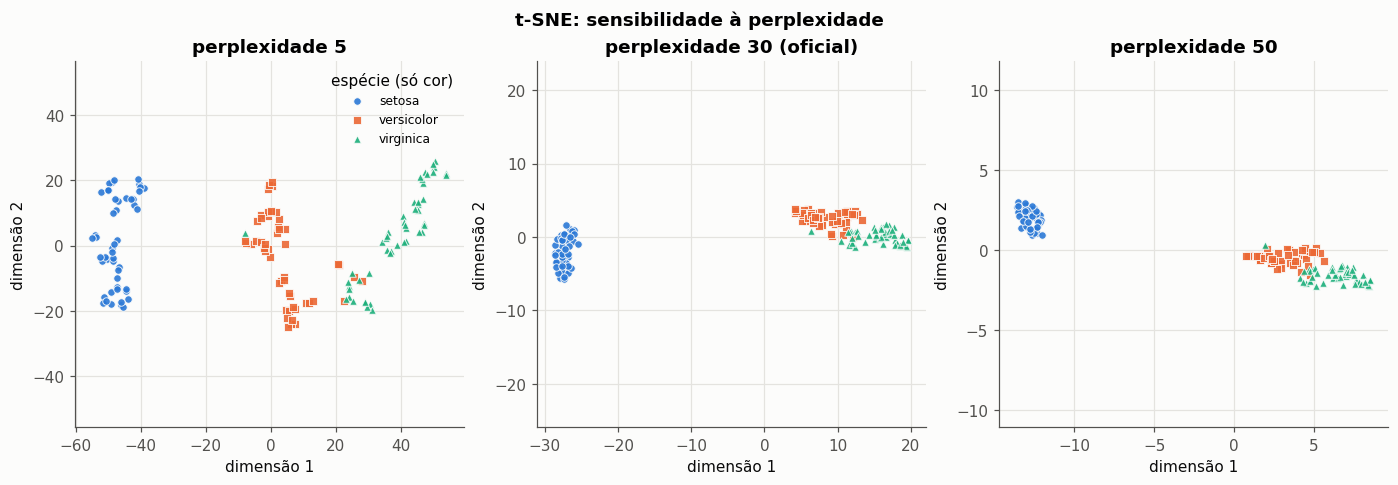

KL final por perplexidade (comparável só dentro da mesma perplexidade): {5: np.float64(0.3511), 30: np.float64(0.1219), 50: np.float64(0.0707)}


In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(12.6, 4.3), layout="constrained")
kl_sens = {}
for ax, perp in zip(eixos, (5, 30, 50)):
    modelo = ajustar_tsne(X, CONFIG["semente_global"], perplexity=perp)
    kl_sens[perp] = modelo.kl_divergence_
    grafico_projecao(ax, modelo.embedding_, f"perplexidade {perp}" + (" (oficial)" if perp == 30 else ""),
                     "dimensão 1", "dimensão 2")
eixos[0].legend(title="espécie (só cor)", loc="best", fontsize=8)
fig.suptitle("t-SNE: sensibilidade à perplexidade", fontweight="bold")
salvar_figura(fig, "q2_tsne_sensibilidade")
plt.show()
print("KL final por perplexidade (comparável só dentro da mesma perplexidade):",
      {p: round(v, 4) for p, v in kl_sens.items()})

#### 7.3.2 Verificações do t-SNE

- Dimensões e valores finitos.
- **Reprodutibilidade:** um novo ajuste com a mesma semente dá o mesmo embedding.
- A divergência KL é finita e positiva.
- A taxa de aprendizado efetiva segue a regra `"auto"`.
- O número de iterações executadas, `n_iter_` + 1, não passa de `max_iter`.

In [ ]:
verif_tsne = pd.Series({
    **verificar_embedding(Z_tsne, 2),
    "reprodutível (mesma semente)": np.array_equal(ajustar_tsne(X, CONFIG["semente_global"]).embedding_, Z_tsne),
    "KL finita e positiva": bool(np.isfinite(tsne.kl_divergence_) and tsne.kl_divergence_ > 0),
    "learning_rate_ = max(n / (12·4), 50)": bool(np.isclose(
        tsne.learning_rate_, max(len(X) / CONFIG["tsne"]["early_exaggeration"] / 4, 50))),
    "iterações executadas (n_iter_ + 1) ≤ max_iter": tsne.n_iter_ + 1 <= CONFIG["tsne"]["max_iter"],
}, name="verificação")
display(verif_tsne.to_frame())
assert verif_tsne.all()
print("Verificações do t-SNE: OK")

,verificação
dimensões,True
valores finitos,True
reprodutível (mesma semente),True
KL finita e positiva,True
"learning_rate_ = max(n / (12·4), 50)",True
iterações executadas (n_iter_ + 1) ≤ max_iter,True


Verificações do t-SNE: OK


### 7.3.3 Comentários

**Saídas.**
- A divergência KL final foi 0,122, indicando o quanto as vizinhanças foram preservadas na representação 2D.
- Foram executadas as 1000 iterações, com taxa de aprendizado 50. O valor `n_iter_ = 999` representa o índice da última iteração, contado a partir de zero.
- Não houve parada antecipada. Isso não significa que o mínimo foi alcançado, apenas que a otimização chegou ao limite de 1000 iterações.
- O t-SNE não fornece variância explicada, diferentemente da PCA.

**Separação e sobreposição.**
- As setosas formam um grupo isolado.
- Versicolor e virginica aparecem em agrupamentos próximos, com sobreposição na região de contato. Algumas virginica ficam entre as versicolor.

### 7.4 UMAP

**Método** (McInnes, Healy & Melville, 2018):

1. Constrói um grafo de vizinhança usando os `n_neighbors` vizinhos mais próximos de cada objeto.
2. Cria uma representação 2D que tenta preservar essas relações, minimizando uma entropia cruzada.
3. O parâmetro `min_dist` controla o quanto os pontos podem ficar próximos no gráfico.

**Interpretação.** Assim como no t-SNE, as vizinhanças locais são mais confiáveis. Distâncias globais, tamanhos aparentes e eixos não têm interpretação métrica. O UMAP também não fornece variância explicada.

**Hiperparâmetros** (`umap.UMAP`):

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `n_neighbors` | 15 | Padrão; equilibra estruturas locais e globais |
| `min_dist` | 0,1 | Padrão; controla a proximidade dos pontos |
| `spread` | 1,0 | Padrão |
| Métrica | Euclidiana | Coerente com a A4 |
| `random_state` | Semente global | Garante reprodutibilidade, mas desativa o paralelismo |

**Saídas padrão:**

| Saída | Conteúdo |
|---|---|
| `embedding_` | Coordenadas em 2D |
| `graph_` | Grafo de vizinhança fuzzy, em matriz esparsa |
| $a$ e $b$ | Parâmetros da curva definidos por `min_dist` e `spread` |

embedding_: (150, 2) | graph_: (150, 150), 2678 arestas (pares ordenados), densidade 0.119 | a = 1.5769, b = 0.8951
Pesos das arestas: mín 0.0001, mediana 0.2335, máx 1.0000 | vizinhos por objeto: mín 14, máx 28


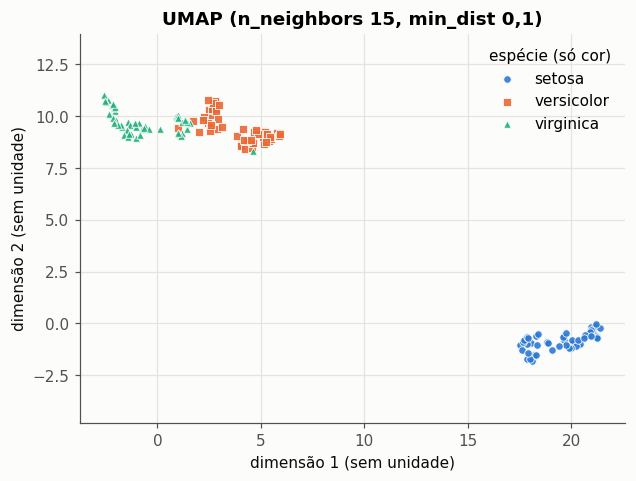

In [ ]:
import warnings
from umap.umap_ import find_ab_params


def ajustar_umap(X, semente, **ajustes):
    """UMAP com os hiperparâmetros de CONFIG["umap"] (ajustes só na análise de sensibilidade)."""
    p = {**CONFIG["umap"], **ajustes}
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="n_jobs value")    # aviso esperado ao fixar a semente
        return umap.UMAP(n_components=2, n_neighbors=p["n_neighbors"], min_dist=p["min_dist"],
                         spread=p["spread"], metric="euclidean", random_state=semente).fit(X)


modelo_umap = ajustar_umap(X, CONFIG["semente_global"])
Z_umap = modelo_umap.embedding_
grafo = modelo_umap.graph_
a_umap, b_umap = find_ab_params(CONFIG["umap"]["spread"], CONFIG["umap"]["min_dist"])
print(f"embedding_: {Z_umap.shape} | graph_: {grafo.shape}, {grafo.nnz} arestas (pares ordenados), "
      f"densidade {grafo.nnz / len(X) ** 2:.3f} | a = {a_umap:.4f}, b = {b_umap:.4f}")
print(f"Pesos das arestas: mín {grafo.data.min():.4f}, mediana {np.median(grafo.data):.4f}, máx {grafo.data.max():.4f} "
      f"| vizinhos por objeto: mín {np.diff(grafo.indptr).min()}, máx {np.diff(grafo.indptr).max()}")
figura_projecao(Z_umap, "UMAP (n_neighbors 15, min_dist 0,1)", "dimensão 1 (sem unidade)",
                "dimensão 2 (sem unidade)", "q2_umap")

#### 7.4.1 Sensibilidade a `n_neighbors` (não substitui a configuração oficial)

O UMAP é ajustado com `n_neighbors` = 5, 15 e 50, com a mesma semente. Valores pequenos privilegiam a estrutura muito local; valores grandes, a estrutura mais global.

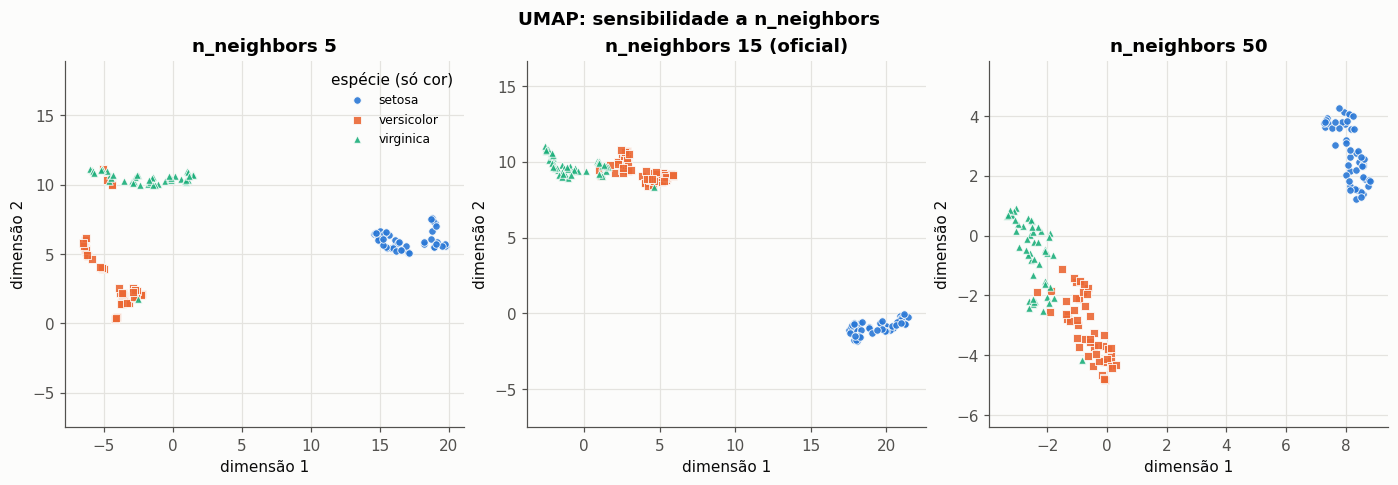

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(12.6, 4.3), layout="constrained")
for ax, viz in zip(eixos, (5, 15, 50)):
    grafico_projecao(ax, ajustar_umap(X, CONFIG["semente_global"], n_neighbors=viz).embedding_,
                     f"n_neighbors {viz}" + (" (oficial)" if viz == 15 else ""), "dimensão 1", "dimensão 2")
eixos[0].legend(title="espécie (só cor)", loc="best", fontsize=8)
fig.suptitle("UMAP: sensibilidade a n_neighbors", fontweight="bold")
salvar_figura(fig, "q2_umap_sensibilidade")
plt.show()

#### 7.4.2 Verificações do UMAP

- Dimensões e valores finitos.
- **Reprodutibilidade:** um novo ajuste com a mesma semente dá o mesmo embedding.
- O grafo de vizinhança é simétrico (união fuzzy), tem pesos em $(0, 1]$ e nenhum objeto isolado.
- Os parâmetros $a$ e $b$ usados correspondem a `min_dist` e `spread`.

In [ ]:
verif_umap = pd.Series({
    **verificar_embedding(Z_umap, 2),
    "reprodutível (mesma semente)": np.array_equal(ajustar_umap(X, CONFIG["semente_global"]).embedding_, Z_umap),
    "grafo simétrico": abs(grafo - grafo.T).max() < 1e-12,
    "pesos em (0, 1]": bool((grafo.data > 0).all() and (grafo.data <= 1 + 1e-12).all()),
    "nenhum objeto isolado": bool((np.diff(grafo.indptr) > 0).all()),
    "a, b correspondem a min_dist e spread": bool(np.allclose((modelo_umap._a, modelo_umap._b), (a_umap, b_umap))),
}, name="verificação")
display(verif_umap.to_frame())
assert verif_umap.all()
print("Verificações do UMAP: OK")

,verificação
dimensões,True
valores finitos,True
reprodutível (mesma semente),True
grafo simétrico,True
"pesos em (0, 1]",True
nenhum objeto isolado,True
"a, b correspondem a min_dist e spread",True


Verificações do UMAP: OK


#### 7.4.3 Comentários


**Saídas.**
- O grafo de vizinhança fuzzy tem 2678 entradas não nulas (densidade 0,119). Cada objeto fica ligado a entre 14 e 28 outros: pelo menos `n_neighbors` − 1 = 14, e mais por causa da simetrização.
- Os pesos das arestas vão de 0,0001 a 1, com mediana de cerca de 0,23.
- Os parâmetros da curva derivados de `min_dist` = 0,1 são $a = 1{,}577$ e $b = 0{,}895$.
- Como no t-SNE, **não há variância explicada**.

**Separação e sobreposição.**
- As setosas formam um grupo isolado.
- Versicolor e virginica formam **uma faixa contínua**, com virginica numa ponta e versicolor na outra, misturadas na região central.

**Sensibilidade.**
- Com `n_neighbors` = 5, a estrutura muito local fragmenta as versicolor em dois pedaços.
- Com 50, a faixa versicolor–virginica fica mais contínua e alongada.
- Nas três configurações, o que se mantém é o mesmo do t-SNE: setosa separada, e versicolor e virginica contíguas, sem fronteira nítida.


### 7.5 Comparação dos quatro métodos

O painel compara as quatro representações usando duas métricas, sem utilizar os rótulos:

- **Confiabilidade das vizinhanças:** verifica se os pontos próximos no gráfico também são próximos nos dados originais. Quanto mais perto de 1, melhor.
- **Correlação de Spearman:** compara a ordem das distâncias entre os objetos nos dados originais e nas projeções. Quanto mais perto de 1, melhor a preservação global.

As métricas ajudam a comparar as representações, mas não definem um vencedor, pois cada método tem objetivos diferentes.

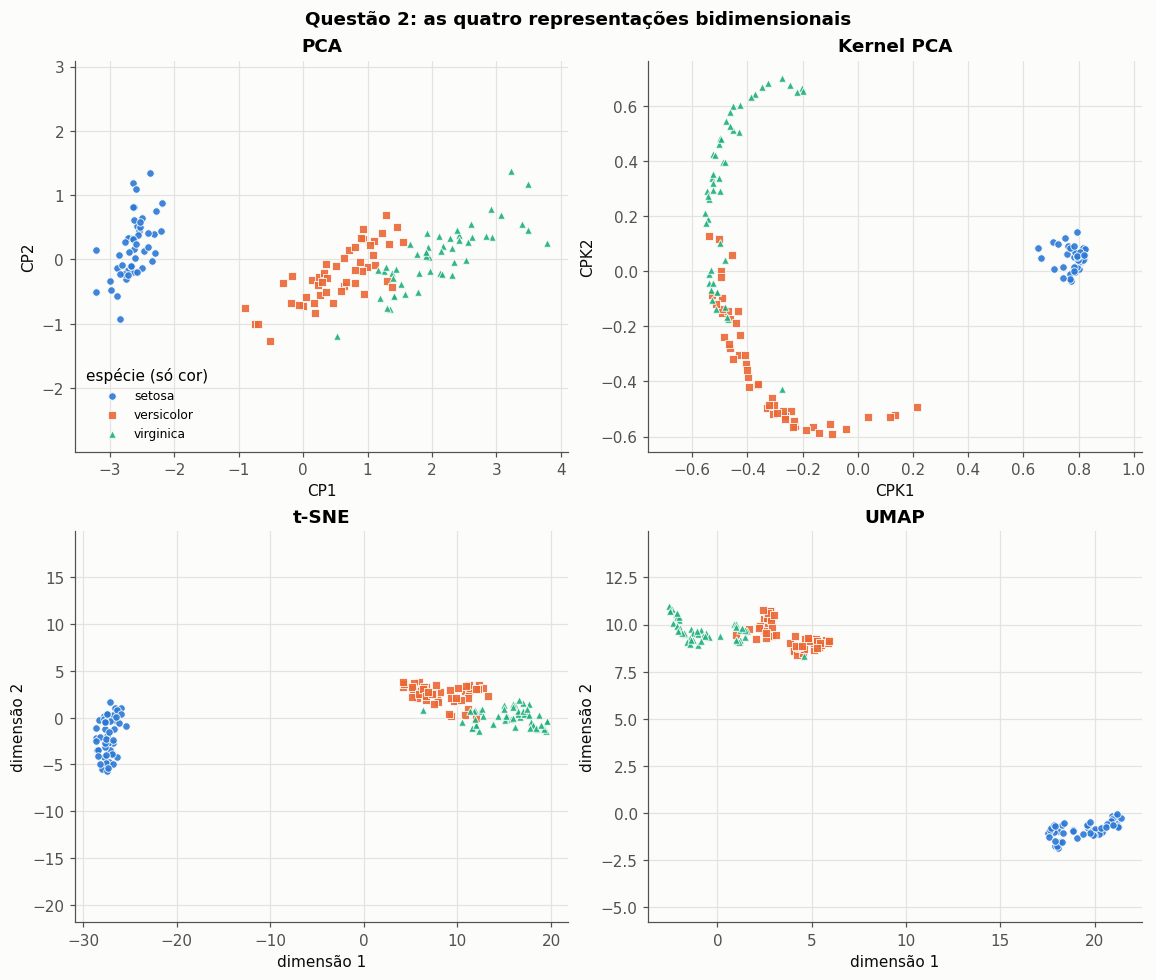

,confiabilidade das vizinhanças (k = 10),Spearman: distâncias originais × 2D
PCA,0.9830,0.9958
Kernel PCA,0.9396,0.9387
t-SNE,0.9894,0.9732
UMAP,0.9802,0.9564


In [ ]:
PROJECOES_Q2 = {"PCA": (Z_pca[:, :2], "CP1", "CP2"), "Kernel PCA": (Z_kpca[:, :2], "CPK1", "CPK2"),
                "t-SNE": (Z_tsne, "dimensão 1", "dimensão 2"), "UMAP": (Z_umap, "dimensão 1", "dimensão 2")}

fig, eixos = plt.subplots(2, 2, figsize=(10.4, 8.8), layout="constrained")
for ax, (nome, (Z, rx, ry)) in zip(eixos.ravel(), PROJECOES_Q2.items()):
    grafico_projecao(ax, Z, nome, rx, ry)
eixos[0, 0].legend(title="espécie (só cor)", loc="lower left", fontsize=8)
fig.suptitle("Questão 2: as quatro representações bidimensionais", fontweight="bold")
salvar_figura(fig, "q2_comparacao")
plt.show()

dist_originais = pdist(X)
diagnosticos_q2 = pd.DataFrame({
    nome: {"confiabilidade das vizinhanças (k = 10)": trustworthiness(X, Z, n_neighbors=10),
           "Spearman: distâncias originais × 2D": spearmanr(dist_originais, pdist(Z)).statistic}
    for nome, (Z, _, _) in PROJECOES_Q2.items()}).T
display(diagnosticos_q2.style.format("{:.4f}"))


### 7.5.1 Discussão comparativa

**Estrutura comum.** Os quatro métodos mostram as setosas isoladas e uma sobreposição entre versicolor e virginica. Isso confirma visualmente o resultado da Questão 1, em que todos os algoritmos escolheram $k^*=2$.

**Diferenças entre os métodos.**
- **PCA:** projeção linear, de fácil interpretação, que preserva 97,8% da variância em duas componentes.
- **Kernel PCA:** utiliza um kernel gaussiano, produzindo uma representação não linear que modifica a geometria dos dados.
- **t-SNE e UMAP:** priorizam a preservação de vizinhanças locais e dependem de hiperparâmetros. Suas distâncias entre grupos não devem ser interpretadas diretamente.

**Comparação dos diagnósticos.**

| Método | Preservação local | Spearman global |
|---|---:|---:|
| PCA | 0,983 | 0,996 |
| Kernel PCA | 0,940 | 0,939 |
| t-SNE | 0,989 | 0,973 |
| UMAP | 0,980 | 0,956 |

O t-SNE apresentou o melhor resultado local, enquanto a PCA preservou melhor as distâncias globais. A boa preservação global do t-SNE pode estar relacionada à inicialização pela PCA (Kobak & Linderman, 2021).

Os resultados mais baixos do Kernel PCA não indicam inferioridade, pois o método trabalha com uma geometria diferente da Euclidiana original. Além disso, as pequenas diferenças entre PCA, t-SNE e UMAP não permitem estabelecer um ranking geral.

Assim, a escolha depende do objetivo: PCA para interpretação dos atributos, Kernel PCA para análise de estruturas não lineares e t-SNE e UMAP para visualização de vizinhanças locais.
